<a href="https://colab.research.google.com/github/jidall/jidall/blob/main/CONSUMIDORES.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import pandas as pd
import numpy as np

# ID da planilha do Google Sheets
sheet_id = "1rhwFuhAlnTWkvZeb3mOoiXSp6rKMLTO0_MhPDsxRzLs"

# Exportação direta da primeira aba como CSV
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv"

df = pd.read_csv(url)

print("Número de respostas:", df.shape[0])
print("Número de colunas:", df.shape[1])

df.head()

Número de respostas: 121
Número de colunas: 25


,Carimbo de data/hora,Pontuação,Qual o seu nome completo?,Aceita participar? ( Termo de Consentimento),Idade,Sexo,Município/Cidade/Estado,"Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)",Renda familiar mensal (R$),Com que frequência consome leite ou derivados?,...,"Acredito que o leite vendido no Brasil/na minha cidade é, na maioria das vezes, seguro quanto a resíduos de antibióticos.",Confio nas instituições que fiscalizam a qualidade do leite (Vigilância Sanitária/Ministério da Agricultura).,"Se existisse um leite com selo “Livre de Antibióticos”, você teria interesse em comprá-lo?","Se respondeu “Sim” ou “Talvez”, quanto a mais pagaria por litro? (Escolha apenas uma)",Quais dos motivos mais influenciariam a sua compra? (marcar até 2 alternativas),Gostaria de deixar algum comentário?,Comentário:,"Você pode assinalar o campo a seguir, para receber o resultado desta pesquisa, caso seja de seu interesse:",Qual seu e-mail para envio do resultado,Endereço de e-mail
0,19/02/2026 15:48:26,0 / 3,Ricardo Bellintani Leocádio,Sim,45,Masculino,Cascavel,Pós-graduação completo,"Entre R$6.000,00 e R$12.000,00",Diariamente,...,1,2,Sim,Não pagaria nada a mais,"Preço, Confiança no selo",Não,NaN,Quero receber os resultados da pesquisa,ricardobleocadio@gmail.com,NaN
1,26/02/2026 16:22:46,0 / 3,Caroline Kudla,Sim,30,Feminino,Curitiba,Ensino Superior completo,Prefiro não informar,3–6x por semana,...,3,1,Sim,NaN,Qualidade/sabor,Não,NaN,Quero receber os resultados da pesquisa,carolinekudla@gmail.com,NaN
2,26/02/2026 16:26:09,0 / 3,Francine Magalhães,Sim,40,Feminino,Francisco Beltrão,Pós-graduação completa,"Entre R$6.000,00 e R$12.000,00",Diariamente,...,2,3,Sim,Até 5% a mais,Confiança no selo,Não,NaN,Quero receber os resultados da pesquisa,francine_magalhaes@live.com,NaN
3,04/03/2026 18:13:12,0 / 3,Juliana Allievi,Sim,35,Feminino,Santa Helena,Pós-graduação completa,"Mais de R$12.000,00",Diariamente,...,5,5,Talvez/Depende,Não pagaria nada a mais,Confiança no selo,Não,NaN,Não quero receber os resultados da pesquisa,NaN,NaN
4,10/03/2026 17:17:44,0 / 3,Grazielle Nunes do Vale,Sim,45,Feminino,Londrina,Ensino Superior completo,"Entre R$3.000,00 e R$6000,00",Diariamente,...,2,5,Sim,Não pagaria nada a mais,"Confiança no selo, Saúde da família, Qualidade...",Não,NaN,Não quero receber os resultados da pesquisa,NaN,NaN


In [10]:
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

1. Carimbo de data/hora
2. Pontuação
3. Qual o seu nome completo?
4. Aceita participar? ( Termo de Consentimento)
5. Idade
6. Sexo
7. Município/Cidade/Estado
8. Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)
9. Renda familiar mensal (R$)   
10. Com que frequência consome leite ou derivados?
11. Onde costuma comprar o leite que consome (marcar até 2 alternativas)
12. Você costuma comprar leite com selo (orgânico, livre de hormônios, livre de antibióticos, etc.)?
13. se marcou sim, qual selo?
14. Na sua opinião, os antibióticos na pecuária leiteira são usados principalmente para:
15. Estou preocupado(a) com a presença de resíduos de antibióticos no leite.
16. Acredito que o leite vendido no Brasil/na minha cidade é, na maioria das vezes, seguro quanto a resíduos de antibióticos. 
17. Confio nas instituições que fiscalizam a qualidade do leite (Vigilância Sanitária/Ministério da Agricultura). 
18. Se existisse um leite com selo “Livre de Antibióticos”, você

In [11]:
print("CONSENTIMENTO:")
print(df["Aceita participar? ( Termo de Consentimento)"].value_counts(dropna=False))

print("\nIDADES:")
print(df["Idade"].value_counts(dropna=False).sort_index())

CONSENTIMENTO:
Aceita participar? ( Termo de Consentimento)
Sim    121
Name: count, dtype: int64

IDADES:
Idade
15           3
15 anos      1
15 anos      1
16           4
17           8
17 anos      2
18          13
18 anos      2
19           6
20           3
21           3
22           8
22 anos      1
23           2
24           3
25           4
27           3
28           2
30           2
31           1
32           1
33           1
35           3
36           5
37           2
38           2
39           1
40           2
42           2
43           4
45           6
46           1
48 anos      1
49           5
50           1
51           1
53 anos      1
55           1
57           1
59           1
62           1
64           1
65           1
66           1
67           2
69           1
Name: count, dtype: int64


In [12]:
df["Idade_num"] = (
    df["Idade"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .astype(float)
)

print(df["Idade_num"].value_counts().sort_index())

print("\nPARTICIPANTES COM MENOS DE 18 ANOS:")
print(df.loc[df["Idade_num"] < 18, ["Idade", "Idade_num"]])

Idade_num
15.0     5
16.0     4
17.0    10
18.0    15
19.0     6
20.0     3
21.0     3
22.0     9
23.0     2
24.0     3
25.0     4
27.0     3
28.0     2
30.0     2
31.0     1
32.0     1
33.0     1
35.0     3
36.0     5
37.0     2
38.0     2
39.0     1
40.0     2
42.0     2
43.0     4
45.0     6
46.0     1
48.0     1
49.0     5
50.0     1
51.0     1
53.0     1
55.0     1
57.0     1
59.0     1
62.0     1
64.0     1
65.0     1
66.0     1
67.0     2
69.0     1
Name: count, dtype: int64

PARTICIPANTES COM MENOS DE 18 ANOS:
       Idade  Idade_num
40        17       17.0
41        17       17.0
42        17       17.0
43        16       16.0
48        16       16.0
51        15       15.0
53        17       17.0
54   17 anos       17.0
57        16       16.0
58  15 anos        15.0
61   15 anos       15.0
62        15       15.0
68   17 anos       17.0
69        17       17.0
70        17       17.0
72        16       16.0
77        17       17.0
79        15       15.0
80        17       1

In [13]:
print("TOTAL DE PARTICIPANTES:", len(df))

print("MENORES DE 18 ANOS:",
      (df["Idade_num"] < 18).sum())

print("18 ANOS OU MAIS:",
      (df["Idade_num"] >= 18).sum())

print("\nIDADE MÍNIMA:", df["Idade_num"].min())
print("IDADE MÁXIMA:", df["Idade_num"].max())

TOTAL DE PARTICIPANTES: 121
MENORES DE 18 ANOS: 19
18 ANOS OU MAIS: 102

IDADE MÍNIMA: 15.0
IDADE MÁXIMA: 69.0


In [14]:
df_raw = df.copy()
df_cons = df.copy()

print("Base original:", df_raw.shape)
print("Base de trabalho:", df_cons.shape)

Base original: (121, 26)
Base de trabalho: (121, 26)


In [15]:
faltantes = df_cons.isna().sum()

print(faltantes[faltantes > 0].sort_values(ascending=False))

se marcou sim, qual selo?                                                                112
Comentário:                                                                              111
Qual seu e-mail para envio do resultado                                                   46
Endereço de e-mail                                                                         9
Gostaria de deixar algum comentário?                                                       5
Se respondeu “Sim” ou “Talvez”, quanto a mais pagaria por litro? (Escolha apenas uma)      3
dtype: int64


In [16]:
print(df_cons["Sexo"].value_counts(dropna=False))

Sexo
Feminino     85
Masculino    36
Name: count, dtype: int64


In [17]:
print(df_cons["Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)"].value_counts(dropna=False))

Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)
Pós-graduação completa         35
Ensino Médio completo          33
Ensino Superior completo       26
Ensino Fundamental completo    26
Pós-graduação completo          1
Name: count, dtype: int64


In [18]:
for valor in df_cons["Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)"].unique():
    print(repr(valor))

'Pós-graduação completo'
'Ensino Superior completo'
'Pós-graduação completa'
'Ensino Médio completo'
'Ensino Fundamental completo'


In [19]:
col_escolaridade = "Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)"

df_cons.loc[
    df_cons[col_escolaridade].str.contains("Pós-graduação", na=False),
    col_escolaridade
] = "Pós-graduação completa"

print(df_cons[col_escolaridade].value_counts(dropna=False))

Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)
Pós-graduação completa         36
Ensino Médio completo          33
Ensino Superior completo       26
Ensino Fundamental completo    26
Name: count, dtype: int64


In [21]:
for col in df_cons.columns:
    if "Renda" in col:
        print(repr(col))

'Renda familiar mensal (R$)   '


In [23]:
df_cons.columns = df_cons.columns.str.strip()

print([repr(col) for col in df_cons.columns if "Renda" in col])

["'Renda familiar mensal (R$)'"]


In [24]:
print(df_cons["Renda familiar mensal (R$)"].value_counts(dropna=False))

Renda familiar mensal (R$)
Entre R$6.000,00 e R$12.000,00    33
Entre R$3.000,00 e R$6000,00      30
Até R$3.000,00                    23
Prefiro não informar              20
Mais de R$12.000,00               15
Name: count, dtype: int64


In [25]:
print(df_cons["Município/Cidade/Estado"].value_counts(dropna=False))

Município/Cidade/Estado
Rio de Janeiro                     21
Rio de Janeiro                     13
Cascavel                            8
Pato Branco                         5
Francisco Beltrão                   4
Rj                                  4
Cascavel                            4
Rio de janeiro                      4
Francisco Beltrão                   3
RJ                                  3
Pato branco                         2
Curitiba                            2
Pato Branco                         2
Rio Pomba                           2
Cascavel PR                         2
São Jorge D'Oeste                   1
Londrina                            1
Itapejara d’Oeste                   1
Coronel Vivida                      1
Planalto                            1
pato branco                         1
Santa Helena                        1
Dois Vizinhos                       1
Maringá                             1
Manfrinópolis                       1
Campo magro Paraná        

In [26]:
df_cons["Municipio_pad"] = (
    df_cons["Município/Cidade/Estado"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print(df_cons["Municipio_pad"].value_counts())

Municipio_pad
rio de janeiro                    42
cascavel                          12
pato branco                       10
francisco beltrão                  7
rj                                 7
rio pomba                          3
curitiba                           2
cascavel pr                        2
cascavel - pr                      2
ampére paraná                      2
coronel vivida                     2
manfrinópolis                      1
são jorge d'oeste                  1
londrina                           1
santa helena                       1
dois vizinhos                      1
maringá                            1
campo magro paraná                 1
são paulo                          1
arapongas                          1
duque de caxias                    1
nova iguaçu                        1
rio janeiro                        1
itapejara d’oeste                  1
planalto                           1
corbélia                           1
rio de janeiro/rj       

In [27]:
mapa_municipios = {
    "rio de janeiro-rj": "rio de janeiro",
    "rio de janeiro/rj": "rio de janeiro",
    "rio de janeiro": "rio de janeiro",
    "cascavel pr": "cascavel",
    "cascavel - pr": "cascavel",
    "pato branco": "pato branco",
    "francisco beltrão - pr": "francisco beltrão",
    "francisco beltrão, paraná": "francisco beltrão",
    "ampére paraná": "ampére",
    "ampère paraná": "ampére",
    "coronel vivida, pr": "coronel vivida",
    "santa izabel do oeste - pr": "santa izabel do oeste",
    "santa izabel do oeste - paraná": "santa izabel do oeste",
    "pinhal de são bento pr": "pinhal de são bento",
    "río de janeiro": "rio de janeiro"
}

df_cons["Municipio_pad"] = df_cons["Municipio_pad"].replace(mapa_municipios)

print(df_cons["Municipio_pad"].value_counts())

Municipio_pad
rio de janeiro            43
cascavel                  16
pato branco               10
francisco beltrão          8
rj                         7
rio pomba                  3
curitiba                   2
santa izabel do oeste      2
ampére                     2
pinhal de são bento        2
coronel vivida             2
planalto                   1
manfrinópolis              1
são jorge d'oeste          1
itapejara d’oeste          1
dois vizinhos              1
santa helena               1
maringá                    1
londrina                   1
duque de caxias            1
campo magro paraná         1
arapongas                  1
são paulo                  1
corbélia                   1
cianorte                   1
rio janeiro                1
nova iguaçu                1
silveirânia                1
magé                       1
pirauba                    1
guidoval - mg              1
francisco beltrao - pr     1
pinheiral                  1
francisco beltrão-pr       1


In [28]:
print("RESPOSTAS COM 'francisco':")
print(
    df_cons.loc[
        df_cons["Municipio_pad"].str.contains("francisco", na=False),
        ["Município/Cidade/Estado", "Municipio_pad"]
    ].drop_duplicates()
)

print("\nRESPOSTAS COM 'rio' OU 'rj':")
print(
    df_cons.loc[
        df_cons["Municipio_pad"].str.contains(r"rio|^rj$", na=False, regex=True),
        ["Município/Cidade/Estado", "Municipio_pad"]
    ].drop_duplicates()
)

RESPOSTAS COM 'francisco':
        Município/Cidade/Estado           Municipio_pad
2            Francisco Beltrão        francisco beltrão
12            Francisco Beltrão       francisco beltrão
111      Francisco Beltrao - PR  francisco beltrao - pr
113        Francisco Beltrão-PR    francisco beltrão-pr
116       Francisco Beltrão, PR   francisco beltrão, pr
117  Francisco Beltrão, Paraná        francisco beltrão

RESPOSTAS COM 'rio' OU 'rj':
    Município/Cidade/Estado   Municipio_pad
39                       Rj              rj
40           Rio de Janeiro  rio de janeiro
41          Rio de Janeiro   rio de janeiro
50           Rio de janeiro  rio de janeiro
57             Rio Janeiro      rio janeiro
59          RIO DE JANEIRO   rio de janeiro
60                       RJ              rj
61           rio de janeiro  rio de janeiro
63          Rio de janeiro   rio de janeiro
65        Rio de Janeiro/RJ  rio de janeiro
79          rio de janeiro   rio de janeiro
101               Rio P

In [29]:
mapa_francisco = {
    "francisco beltrao - pr": "francisco beltrão",
    "francisco beltrão-pr": "francisco beltrão",
    "francisco beltrão, pr": "francisco beltrão"
}

df_cons["Municipio_pad"] = df_cons["Municipio_pad"].replace(mapa_francisco)

print(df_cons["Municipio_pad"].value_counts())

Municipio_pad
rio de janeiro           43
cascavel                 16
francisco beltrão        11
pato branco              10
rj                        7
rio pomba                 3
coronel vivida            2
curitiba                  2
pinhal de são bento       2
santa izabel do oeste     2
ampére                    2
dois vizinhos             1
são jorge d'oeste         1
maringá                   1
londrina                  1
santa helena              1
campo magro paraná        1
são paulo                 1
arapongas                 1
itapejara d’oeste         1
planalto                  1
manfrinópolis             1
nova iguaçu               1
duque de caxias           1
cianorte                  1
corbélia                  1
rio janeiro               1
magé                      1
pirauba                   1
silveirânia               1
pinheiral                 1
guidoval - mg             1
Name: count, dtype: int64


In [30]:
print(df_cons["Com que frequência consome leite ou derivados?"].value_counts(dropna=False))

Com que frequência consome leite ou derivados?
Diariamente                    67
3–6x por semana                27
1–2x por semana                16
Raramente (menos de 1x/sem)     9
Nunca                           2
Name: count, dtype: int64


In [31]:
print(df_cons["Onde costuma comprar o leite que consome (marcar até 2 alternativas)"].value_counts(dropna=False))

Onde costuma comprar o leite que consome (marcar até 2 alternativas)
Supermercado (marcas industrializadas)                                                                                                      71
Supermercado (marcas industrializadas), Mercado local/mini-mercado                                                                          28
Não consumo leite, somente derivados                                                                                                         6
Supermercado (marcas industrializadas), Produtor local (venda direta)                                                                        6
Produtor local (venda direta)                                                                                                                2
De minha propriedade                                                                                                                         1
Supermercado (marcas industrializadas), Mercado local/mini-mercado, Produ

In [32]:
col_compra = "Onde costuma comprar o leite que consome (marcar até 2 alternativas)"

respostas_compra = (
    df_cons[col_compra]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

print(respostas_compra.value_counts())

Onde costuma comprar o leite que consome (marcar até 2 alternativas)
Supermercado (marcas industrializadas)    109
Mercado local/mini-mercado                 31
Produtor local (venda direta)              10
Não consumo leite                           8
somente derivados                           8
De minha propriedade                        1
Consumo leite esporadicamente               1
Compro pois moro com família.               1
Feira                                       1
Produtor de outra localidade                1
Tenho em casa                               1
uma vaca de leite                           1
Name: count, dtype: int64


In [33]:
categorias_principais = [
    "Supermercado (marcas industrializadas)",
    "Mercado local/mini-mercado",
    "Produtor local (venda direta)",
    "Não consumo leite"
]

respostas_livres = respostas_compra[
    ~respostas_compra.isin(categorias_principais)
]

print(respostas_livres.value_counts())

Onde costuma comprar o leite que consome (marcar até 2 alternativas)
somente derivados                8
De minha propriedade             1
Consumo leite esporadicamente    1
Compro pois moro com família.    1
Feira                            1
Produtor de outra localidade     1
Tenho em casa                    1
uma vaca de leite                1
Name: count, dtype: int64


In [34]:
mask_livres = df_cons[col_compra].str.contains(
    "De minha propriedade|Consumo leite esporadicamente|Compro pois moro com família|Feira|Produtor de outra localidade|Tenho em casa|uma vaca de leite",
    na=False
)

print(
    df_cons.loc[
        mask_livres,
        [col_compra]
    ].to_string(index=True)
)

                                                                         Onde costuma comprar o leite que consome (marcar até 2 alternativas)
8                                                                                                                       De minha propriedade 
25                                Supermercado (marcas industrializadas), Não consumo leite, somente derivados, Consumo leite esporadicamente
38   Supermercado (marcas industrializadas), Mercado local/mini-mercado, Não consumo leite, somente derivados, Compro pois moro com família. 
85                                                                                              Supermercado (marcas industrializadas), Feira
105                                                                               Produtor local (venda direta), Produtor de outra localidade
118                                                                                                         Tenho em casa, uma vaca de leite 


In [35]:
df_cons["compra_producao_propria"] = df_cons[col_compra].str.contains(
    "De minha propriedade|Tenho em casa, uma vaca de leite",
    na=False
)

print(df_cons["compra_producao_propria"].value_counts())

compra_producao_propria
False    119
True       2
Name: count, dtype: int64


In [36]:
df_cons["compra_produtor_direto"] = df_cons[col_compra].str.contains(
    "Produtor local \\(venda direta\\)|Produtor de outra localidade",
    na=False,
    regex=True
)

print(df_cons["compra_produtor_direto"].value_counts())

compra_produtor_direto
False    111
True      10
Name: count, dtype: int64


In [37]:
df_cons["compra_supermercado"] = df_cons[col_compra].str.contains(
    "Supermercado (marcas industrializadas)",
    na=False,
    regex=False
)

print(df_cons["compra_supermercado"].value_counts())

compra_supermercado
True     109
False     12
Name: count, dtype: int64


In [38]:
df_cons["compra_mercado_local"] = df_cons[col_compra].str.contains(
    "Mercado local/mini-mercado",
    na=False,
    regex=False
)

print(df_cons["compra_mercado_local"].value_counts())

compra_mercado_local
False    90
True     31
Name: count, dtype: int64


In [39]:
df_cons["nao_consome_leite"] = df_cons[col_compra].str.contains(
    "Não consumo leite",
    na=False,
    regex=False
)

print(df_cons["nao_consome_leite"].value_counts())

nao_consome_leite
False    113
True       8
Name: count, dtype: int64


In [40]:
df_cons["compra_feira"] = df_cons[col_compra].str.contains(
    "Feira",
    na=False,
    regex=False
)

print(df_cons["compra_feira"].value_counts())

compra_feira
False    120
True       1
Name: count, dtype: int64


In [41]:
print(
    df_cons["Você costuma comprar leite com selo (orgânico, livre de hormônios, livre de antibióticos, etc.)?"]
    .value_counts(dropna=False)
)

Você costuma comprar leite com selo (orgânico, livre de hormônios, livre de antibióticos, etc.)?
Não                        93
Raramente                  13
Não compro nenhum leite     8
Sim                         7
Name: count, dtype: int64


In [42]:
print(
    df_cons["Você costuma comprar leite com selo (orgânico, livre de hormônios, livre de antibióticos, etc.)?"]
    .value_counts(dropna=False)
)

Você costuma comprar leite com selo (orgânico, livre de hormônios, livre de antibióticos, etc.)?
Não                        93
Raramente                  13
Não compro nenhum leite     8
Sim                         7
Name: count, dtype: int64


In [43]:
print(
    df_cons["se marcou sim, qual selo?"]
    .value_counts(dropna=False)
)

se marcou sim, qual selo?
NaN                               112
nunca reparei nisso na verdade      1
apenas zero lactose                 1
Livre de antibióticos               1
SIF                                 1
Nenhuma                             1
Molico                              1
.                                   1
livre de antibioticos               1
Selo de inspeção (SIE/SIF)          1
Name: count, dtype: int64


In [44]:
col_selo_compra = "Você costuma comprar leite com selo (orgânico, livre de hormônios, livre de antibióticos, etc.)?"
col_qual_selo = "se marcou sim, qual selo?"

print(
    df_cons.loc[
        df_cons[col_selo_compra] == "Sim",
        [col_selo_compra, col_qual_selo]
    ].to_string(index=True)
)

    Você costuma comprar leite com selo (orgânico, livre de hormônios, livre de antibióticos, etc.)?   se marcou sim, qual selo?
6                                                                                                Sim                         NaN
32                                                                                               Sim       Livre de antibióticos
34                                                                                               Sim                         SIF
55                                                                                               Sim                      Molico
71                                                                                               Sim                         NaN
79                                                                                               Sim       livre de antibioticos
110                                                                                              

In [45]:
df_cons["citou_livre_antibioticos"] = df_cons[col_qual_selo].str.contains(
    "Livre de antibióticos",
    case=False,
    na=False,
    regex=False
)

print(df_cons["citou_livre_antibioticos"].value_counts())

citou_livre_antibioticos
False    120
True       1
Name: count, dtype: int64


In [46]:
for valor in df_cons.loc[
    df_cons[col_selo_compra] == "Sim",
    col_qual_selo
]:
    print(repr(valor))

nan
'Livre de antibióticos'
'SIF'
'Molico'
nan
'livre de antibioticos'
'Selo de inspeção (SIE/SIF)'


In [47]:
df_cons["citou_livre_antibioticos"] = df_cons[col_qual_selo].str.contains(
    "livre de antibi",
    case=False,
    na=False,
    regex=False
)

print(df_cons["citou_livre_antibioticos"].value_counts())

citou_livre_antibioticos
False    119
True       2
Name: count, dtype: int64


In [48]:
print(
    df_cons["Na sua opinião, os antibióticos na pecuária leiteira são usados principalmente para:"]
    .value_counts(dropna=False)
)

Na sua opinião, os antibióticos na pecuária leiteira são usados principalmente para:
Tratar vacas doentes                                         59
Evitar todas as doenças (preventivo em animais saudáveis)    47
Fazer as vacas produzirem mais leite                          8
Não sei                                                       7
Name: count, dtype: int64


In [49]:
print(
    df_cons["Estou preocupado(a) com a presença de resíduos de antibióticos no leite."]
    .value_counts(dropna=False)
    .sort_index()
)

Estou preocupado(a) com a presença de resíduos de antibióticos no leite.
1    19
2    12
3    35
4    25
5    30
Name: count, dtype: int64


In [50]:
print(
    df_cons["Acredito que o leite vendido no Brasil/na minha cidade é, na maioria das vezes, seguro quanto a resíduos de antibióticos."]
    .value_counts(dropna=False)
    .sort_index()
)

Acredito que o leite vendido no Brasil/na minha cidade é, na maioria das vezes, seguro quanto a resíduos de antibióticos.
1     9
2    23
3    36
4    28
5    25
Name: count, dtype: int64


In [51]:
print(
    df_cons["Confio nas instituições que fiscalizam a qualidade do leite (Vigilância Sanitária/Ministério da Agricultura)."]
    .value_counts(dropna=False)
    .sort_index()
)

Confio nas instituições que fiscalizam a qualidade do leite (Vigilância Sanitária/Ministério da Agricultura).
1    14
2    20
3    22
4    36
5    29
Name: count, dtype: int64


In [52]:
print(
    df_cons["Se existisse um leite com selo “Livre de Antibióticos”, você teria interesse em comprá-lo?"]
    .value_counts(dropna=False)
)

Se existisse um leite com selo “Livre de Antibióticos”, você teria interesse em comprá-lo?
Talvez/Depende    61
Sim               56
Não                4
Name: count, dtype: int64


In [53]:
print(
    df_cons["Se respondeu “Sim” ou “Talvez”, quanto a mais pagaria por litro? (Escolha apenas uma)"]
    .value_counts(dropna=False)
)

Se respondeu “Sim” ou “Talvez”, quanto a mais pagaria por litro? (Escolha apenas uma)
Não pagaria nada a mais    31
5–10%                      31
Até 5% a mais              28
10–20%                     21
Prefiro não responder       5
NaN                         3
>20%                        2
Name: count, dtype: int64


In [54]:
pd.crosstab(
    df_cons["Se existisse um leite com selo “Livre de Antibióticos”, você teria interesse em comprá-lo?"],
    df_cons["Se respondeu “Sim” ou “Talvez”, quanto a mais pagaria por litro? (Escolha apenas uma)"],
    dropna=False
)

"Se respondeu “Sim” ou “Talvez”, quanto a mais pagaria por litro? (Escolha apenas uma)",10–20%,5–10%,>20%,Até 5% a mais,Não pagaria nada a mais,Prefiro não responder,NaN
"Se existisse um leite com selo “Livre de Antibióticos”, você teria interesse em comprá-lo?",,,,,,,
Não,0,0,0,0,3,0,1
Sim,10,14,2,13,13,2,2
Talvez/Depende,11,17,0,15,15,3,0


In [55]:
col_pagar = "Se respondeu “Sim” ou “Talvez”, quanto a mais pagaria por litro? (Escolha apenas uma)"

for valor in df_cons[col_pagar].unique():
    print(repr(valor))

'Não pagaria nada a mais'
nan
'Até 5% a mais'
'Prefiro não responder'
'5–10%'
'10–20%'
'>20%'


In [56]:
mapa_pagar = {
    "Não pagaria nada a mais": 0,
    "Até 5% a mais": 1,
    "5-10%": 2,
    "10-20%": 3,
    ">20%": 4
}

df_cons["disposicao_pagar_ord"] = df_cons[col_pagar].map(mapa_pagar)

print(df_cons["disposicao_pagar_ord"].value_counts(dropna=False).sort_index())

disposicao_pagar_ord
0.0    31
1.0    28
4.0     2
NaN    60
Name: count, dtype: int64


In [57]:
for valor in df_cons[col_pagar].dropna().unique():
    print(repr(valor), " -> ", [ord(c) for c in valor])

'Não pagaria nada a mais'  ->  [78, 227, 111, 32, 112, 97, 103, 97, 114, 105, 97, 32, 110, 97, 100, 97, 32, 97, 32, 109, 97, 105, 115]
'Até 5% a mais'  ->  [65, 116, 233, 32, 53, 37, 32, 97, 32, 109, 97, 105, 115]
'Prefiro não responder'  ->  [80, 114, 101, 102, 105, 114, 111, 32, 110, 227, 111, 32, 114, 101, 115, 112, 111, 110, 100, 101, 114]
'5–10%'  ->  [53, 8211, 49, 48, 37]
'10–20%'  ->  [49, 48, 8211, 50, 48, 37]
'>20%'  ->  [62, 50, 48, 37]


In [58]:
mapa_pagar = {
    "Não pagaria nada a mais": 0,
    "Até 5% a mais": 1,
    "5–10%": 2,
    "10–20%": 3,
    ">20%": 4
}

df_cons["disposicao_pagar_ord"] = df_cons[col_pagar].map(mapa_pagar)

print(df_cons["disposicao_pagar_ord"].value_counts(dropna=False).sort_index())

disposicao_pagar_ord
0.0    31
1.0    28
2.0    31
3.0    21
4.0     2
NaN     8
Name: count, dtype: int64


In [59]:
print(
    df_cons["Quais dos motivos mais influenciariam a sua compra? (marcar até 2 alternativas)"]
    .value_counts(dropna=False)
)

Quais dos motivos mais influenciariam a sua compra? (marcar até 2 alternativas)
Preço                                                                                                                                                                                                                                                                                                                                         16
Saúde da família                                                                                                                                                                                                                                                                                                                              13
Preço, Qualidade/sabor                                                                                                                                                                                                                                

In [60]:
col_motivos = "Quais dos motivos mais influenciariam a sua compra? (marcar até 2 alternativas)"

motivos = (
    df_cons[col_motivos]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

print(motivos.value_counts())

Quais dos motivos mais influenciariam a sua compra? (marcar até 2 alternativas)
Saúde da família                                                                                                                                                                                                  64
Preço                                                                                                                                                                                                             57
Confiança no selo                                                                                                                                                                                                 46
Qualidade/sabor                                                                                                                                                                                                   45
Apoiar produtores locais                                            

In [61]:
df_cons["motivo_saude_familia"] = df_cons[col_motivos].str.contains(
    "Saúde da família",
    na=False,
    regex=False
)

print(df_cons["motivo_saude_familia"].value_counts())

motivo_saude_familia
True     64
False    57
Name: count, dtype: int64


In [62]:
df_cons["motivo_preco"] = df_cons[col_motivos].str.contains(
    "Preço",
    na=False,
    regex=False
)

print(df_cons["motivo_preco"].value_counts())

motivo_preco
False    64
True     57
Name: count, dtype: int64


In [63]:
df_cons["motivo_confianca_selo"] = df_cons[col_motivos].str.contains(
    "Confiança no selo",
    na=False,
    regex=False
)

print(df_cons["motivo_confianca_selo"].value_counts())

motivo_confianca_selo
False    75
True     46
Name: count, dtype: int64


In [64]:
df_cons["motivo_qualidade_sabor"] = df_cons[col_motivos].str.contains(
    "Qualidade/sabor",
    na=False,
    regex=False
)

print(df_cons["motivo_qualidade_sabor"].value_counts())

motivo_qualidade_sabor
False    76
True     45
Name: count, dtype: int64


In [65]:
df_cons["motivo_apoiar_produtores"] = df_cons[col_motivos].str.contains(
    "Apoiar produtores locais",
    na=False,
    regex=False
)

print(df_cons["motivo_apoiar_produtores"].value_counts())

motivo_apoiar_produtores
False    105
True      16
Name: count, dtype: int64


In [66]:
print(
    df_cons["Gostaria de deixar algum comentário?"]
    .value_counts(dropna=False)
)

Gostaria de deixar algum comentário?
Não    107
Sim      9
NaN      5
Name: count, dtype: int64


In [67]:
print(
    df_cons.loc[
        df_cons["Comentário:"].notna(),
        ["Comentário:"]
    ].to_string(index=True)
)

                                                                                                                                                                                                                                                                                                                               Comentário:
25                                                                                                                                 Acredito que muitas pessoas vão confundir antibióticos com “conservantes” principalmente se for pessoa leiga sobre o assunto. Talvez seja um viés para explicar melhor antes das perguntas da pesquisa.
29                                                                                                                                                                                                       Eu não pagaria a mais por um leite livre de antibióticos porque entendo que isso é o mínimo que deve ser oferecido ao consumidor.
33     

In [68]:
comentarios = df_cons.loc[df_cons["Comentário:"].notna(), "Comentário:"]

for indice, texto in comentarios.items():
    print(f"\nLinha {indice}:")
    print(texto)


Linha 25:
Acredito que muitas pessoas vão confundir antibióticos com “conservantes” principalmente se for pessoa leiga sobre o assunto. Talvez seja um viés para explicar melhor antes das perguntas da pesquisa.

Linha 29:
Eu não pagaria a mais por um leite livre de antibióticos porque entendo que isso é o mínimo que deve ser oferecido ao consumidor.

Linha 33:
Bem na verdade deveria ser obrigatório a não presença de antibióticos no leite e derivados pois o mesmo é consumido por todos nós más  principalmente por crianças e idosos.

Linha 45:
Não 

Linha 63:
Não conheço esses selos que foram citados

Linha 70:
O apoio de produtores locais é o melhor e mais saudável para que uma comunidade/população possa ter a segurança alimentar necessária. Só é triste que muitos destes leites e derivados costumam ser mais caros, afetando famílias que passam pela insegurança financeira... amei a pesquisa, assunto super interessante e relevante!! 

Linha 78:
É um tema pouco discutido e desconhecido por g

In [69]:
for i in range(11, 18):
    print(i+1, df_cons.columns[i])

12 Você costuma comprar leite com selo (orgânico, livre de hormônios, livre de antibióticos, etc.)?
13 se marcou sim, qual selo?
14 Na sua opinião, os antibióticos na pecuária leiteira são usados principalmente para:
15 Estou preocupado(a) com a presença de resíduos de antibióticos no leite.
16 Acredito que o leite vendido no Brasil/na minha cidade é, na maioria das vezes, seguro quanto a resíduos de antibióticos.
17 Confio nas instituições que fiscalizam a qualidade do leite (Vigilância Sanitária/Ministério da Agricultura).
18 Se existisse um leite com selo “Livre de Antibióticos”, você teria interesse em comprá-lo?


In [70]:
print(df_cons["Idade_num"].describe())

count    121.000000
mean      30.818182
std       14.681054
min       15.000000
25%       18.000000
50%       25.000000
75%       42.000000
max       69.000000
Name: Idade_num, dtype: float64


In [71]:
from scipy.stats import shapiro

estatistica, p_valor = shapiro(df_cons["Idade_num"].dropna())

print("Shapiro-Wilk")
print("Estatística:", estatistica)
print("p-valor:", p_valor)

Shapiro-Wilk
Estatística: 0.8715768338959116
p-valor: 7.963339605685648e-09


In [72]:
bins = [14, 17, 24, 34, 44, 54, 64, 100]
labels = [
    "15–17",
    "18–24",
    "25–34",
    "35–44",
    "45–54",
    "55–64",
    "65 ou mais"
]

df_cons["faixa_etaria"] = pd.cut(
    df_cons["Idade_num"],
    bins=bins,
    labels=labels
)

print(df_cons["faixa_etaria"].value_counts().sort_index())

faixa_etaria
15–17         19
18–24         41
25–34         14
35–44         21
45–54         16
55–64          5
65 ou mais     5
Name: count, dtype: int64


In [73]:
bins2 = [14, 17, 24, 34, 44, 54, 100]

labels2 = [
    "15–17",
    "18–24",
    "25–34",
    "35–44",
    "45–54",
    "55 ou mais"
]

df_cons["faixa_etaria_agrupada"] = pd.cut(
    df_cons["Idade_num"],
    bins=bins2,
    labels=labels2
)

print(df_cons["faixa_etaria_agrupada"].value_counts().sort_index())

faixa_etaria_agrupada
15–17         19
18–24         41
25–34         14
35–44         21
45–54         16
55 ou mais    10
Name: count, dtype: int64


In [74]:
pd.crosstab(
    df_cons["faixa_etaria_agrupada"],
    df_cons["Sexo"],
    margins=True
)

Sexo,Feminino,Masculino,All
faixa_etaria_agrupada,,,
15–17,11,8,19
18–24,27,14,41
25–34,13,1,14
35–44,15,6,21
45–54,12,4,16
55 ou mais,7,3,10
All,85,36,121


In [75]:
pd.crosstab(
    df_cons["Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)"],
    df_cons["Na sua opinião, os antibióticos na pecuária leiteira são usados principalmente para:"],
    margins=True
)

"Na sua opinião, os antibióticos na pecuária leiteira são usados principalmente para:",Evitar todas as doenças (preventivo em animais saudáveis),Fazer as vacas produzirem mais leite,Não sei,Tratar vacas doentes,All
"Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)",,,,,
Ensino Fundamental completo,20,2,1,3,26
Ensino Médio completo,8,5,2,18,33
Ensino Superior completo,8,0,1,17,26
Pós-graduação completa,11,1,3,21,36
All,47,8,7,59,121


In [76]:
from scipy.stats import chi2_contingency

tabela = pd.crosstab(
    df_cons["Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)"],
    df_cons["Na sua opinião, os antibióticos na pecuária leiteira são usados principalmente para:"]
)

chi2, p, gl, esperadas = chi2_contingency(tabela)

print("Qui-quadrado:", chi2)
print("p-valor:", p)
print("Graus de liberdade:", gl)

esperadas_df = pd.DataFrame(
    esperadas,
    index=tabela.index,
    columns=tabela.columns
)

print("\nFREQUÊNCIAS ESPERADAS:")
print(esperadas_df.round(2))

Qui-quadrado: 29.306408492387124
p-valor: 0.0005752424214599781
Graus de liberdade: 9

FREQUÊNCIAS ESPERADAS:
Na sua opinião, os antibióticos na pecuária leiteira são usados principalmente para:  Evitar todas as doenças (preventivo em animais saudáveis)  \
Escolaridade (Se a escolaridade não for complet...                                                                                                
Ensino Fundamental completo                                                                                                       10.10           
Ensino Médio completo                                                                                                             12.82           
Ensino Superior completo                                                                                                          10.10           
Pós-graduação completa                                                                                                            13.98           

Na sua 

In [77]:
col_uso_antibiotico = "Na sua opinião, os antibióticos na pecuária leiteira são usados principalmente para:"

df_cons["uso_antibiotico_correto"] = np.where(
    df_cons[col_uso_antibiotico] == "Tratar vacas doentes",
    "Resposta correta",
    "Outras respostas"
)

print(df_cons["uso_antibiotico_correto"].value_counts())

uso_antibiotico_correto
Outras respostas    62
Resposta correta    59
Name: count, dtype: int64


In [78]:
tabela2 = pd.crosstab(
    df_cons["Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)"],
    df_cons["uso_antibiotico_correto"]
)

chi2_2, p_2, gl_2, esperadas_2 = chi2_contingency(tabela2)

print("TABELA OBSERVADA:")
print(tabela2)

print("\nQui-quadrado:", chi2_2)
print("p-valor:", p_2)
print("Graus de liberdade:", gl_2)

esperadas2_df = pd.DataFrame(
    esperadas_2,
    index=tabela2.index,
    columns=tabela2.columns
)

print("\nFREQUÊNCIAS ESPERADAS:")
print(esperadas2_df.round(2))

TABELA OBSERVADA:
uso_antibiotico_correto                             Outras respostas  \
Escolaridade (Se a escolaridade não for complet...                     
Ensino Fundamental completo                                       23   
Ensino Médio completo                                             15   
Ensino Superior completo                                           9   
Pós-graduação completa                                            15   

uso_antibiotico_correto                             Resposta correta  
Escolaridade (Se a escolaridade não for complet...                    
Ensino Fundamental completo                                        3  
Ensino Médio completo                                             18  
Ensino Superior completo                                          17  
Pós-graduação completa                                            21  

Qui-quadrado: 19.05621503974429
p-valor: 0.00026617830736417025
Graus de liberdade: 3

FREQUÊNCIAS ESPERADAS:
uso_antibiot

In [79]:
percentuais = pd.crosstab(
    df_cons["Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)"],
    df_cons["uso_antibiotico_correto"],
    normalize="index"
) * 100

print(percentuais.round(1))

uso_antibiotico_correto                             Outras respostas  \
Escolaridade (Se a escolaridade não for complet...                     
Ensino Fundamental completo                                     88.5   
Ensino Médio completo                                           45.5   
Ensino Superior completo                                        34.6   
Pós-graduação completa                                          41.7   

uso_antibiotico_correto                             Resposta correta  
Escolaridade (Se a escolaridade não for complet...                    
Ensino Fundamental completo                                     11.5  
Ensino Médio completo                                           54.5  
Ensino Superior completo                                        65.4  
Pós-graduação completa                                          58.3  


In [80]:
n = tabela2.to_numpy().sum()

cramers_v = np.sqrt(
    chi2_2 / (n * min(tabela2.shape[0] - 1, tabela2.shape[1] - 1))
)

print("V de Cramér:", cramers_v)

V de Cramér: 0.396849317113882


In [81]:
from scipy.stats import kruskal

col_preocupacao = "Estou preocupado(a) com a presença de resíduos de antibióticos no leite."

grupos = [
    grupo[col_preocupacao].dropna()
    for _, grupo in df_cons.groupby(
        "Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)",
        observed=True
    )
]

h, p_kw = kruskal(*grupos)

print("Kruskal-Wallis H:", h)
print("p-valor:", p_kw)

Kruskal-Wallis H: 12.401132960563393
p-valor: 0.0061280771065627


In [82]:
resumo_preocupacao = df_cons.groupby(
    "Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)",
    observed=True
)[col_preocupacao].agg(
    n="count",
    mediana="median",
    q1=lambda x: x.quantile(0.25),
    q3=lambda x: x.quantile(0.75)
)

print(resumo_preocupacao)

                                                     n  mediana    q1   q3
Escolaridade (Se a escolaridade não for complet...                        
Ensino Fundamental completo                         26      3.0  2.25  4.0
Ensino Médio completo                               33      3.0  1.00  4.0
Ensino Superior completo                            26      3.0  2.25  4.0
Pós-graduação completa                              36      4.0  3.00  5.0


In [86]:
!pip -q install scikit-posthocs

In [87]:
import scikit_posthocs as sp

dunn = sp.posthoc_dunn(
    df_cons,
    val_col=col_preocupacao,
    group_col="Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)",
    p_adjust="bonferroni"
)

print(dunn.round(4))

                             Ensino Fundamental completo  \
Ensino Fundamental completo                       1.0000   
Ensino Médio completo                             1.0000   
Ensino Superior completo                          1.0000   
Pós-graduação completa                            0.3313   

                             Ensino Médio completo  Ensino Superior completo  \
Ensino Fundamental completo                 1.0000                    1.0000   
Ensino Médio completo                       1.0000                    1.0000   
Ensino Superior completo                    1.0000                    1.0000   
Pós-graduação completa                      0.0032                    0.2431   

                             Pós-graduação completa  
Ensino Fundamental completo                  0.3313  
Ensino Médio completo                        0.0032  
Ensino Superior completo                     0.2431  
Pós-graduação completa                       1.0000  


In [88]:
k = 4
n = 121

epsilon2 = (h - k + 1) / (n - k)

print("Epsilon quadrado:", epsilon2)

Epsilon quadrado: 0.08035156376549908


In [89]:
pd.crosstab(
    df_cons["Renda familiar mensal (R$)"],
    df_cons["disposicao_pagar_ord"],
    margins=True
)

disposicao_pagar_ord,0.0,1.0,2.0,3.0,4.0,All
Renda familiar mensal (R$),,,,,,
"Até R$3.000,00",5,8,3,3,1,20
"Entre R$3.000,00 e R$6000,00",6,8,8,7,0,29
"Entre R$6.000,00 e R$12.000,00",11,7,8,5,1,32
"Mais de R$12.000,00",2,1,6,4,0,13
Prefiro não informar,7,4,6,2,0,19
All,31,28,31,21,2,113


In [90]:
df_renda_teste = df_cons[
    (df_cons["Renda familiar mensal (R$)"] != "Prefiro não informar") &
    (df_cons["disposicao_pagar_ord"].notna())
].copy()

grupos_renda = [
    grupo["disposicao_pagar_ord"]
    for _, grupo in df_renda_teste.groupby(
        "Renda familiar mensal (R$)",
        observed=True
    )
]

h_renda, p_renda = kruskal(*grupos_renda)

print("Kruskal-Wallis H:", h_renda)
print("p-valor:", p_renda)
print("n analisado:", len(df_renda_teste))

Kruskal-Wallis H: 3.498072168654632
p-valor: 0.32101224015364455
n analisado: 94


In [91]:
df_esc_pagar = df_cons[
    df_cons["disposicao_pagar_ord"].notna()
].copy()

grupos_esc_pagar = [
    grupo["disposicao_pagar_ord"]
    for _, grupo in df_esc_pagar.groupby(
        "Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)",
        observed=True
    )
]

h_esc_pagar, p_esc_pagar = kruskal(*grupos_esc_pagar)

print("Kruskal-Wallis H:", h_esc_pagar)
print("p-valor:", p_esc_pagar)
print("n analisado:", len(df_esc_pagar))

Kruskal-Wallis H: 0.8093072271013219
p-valor: 0.8472395967463209
n analisado: 113


In [92]:
from scipy.stats import spearmanr

df_corr = df_cons[
    df_cons[col_preocupacao].notna() &
    df_cons["disposicao_pagar_ord"].notna()
]

rho, p_spear = spearmanr(
    df_corr[col_preocupacao],
    df_corr["disposicao_pagar_ord"]
)

print("Spearman rho:", rho)
print("p-valor:", p_spear)
print("n analisado:", len(df_corr))

Spearman rho: 0.18382399614622127
p-valor: 0.05129643839441371
n analisado: 113


In [93]:
col_interesse = "Se existisse um leite com selo “Livre de Antibióticos”, você teria interesse em comprá-lo?"

grupos_interesse = [
    grupo[col_preocupacao].dropna()
    for _, grupo in df_cons.groupby(
        col_interesse,
        observed=True
    )
]

h_interesse, p_interesse = kruskal(*grupos_interesse)

print("Kruskal-Wallis H:", h_interesse)
print("p-valor:", p_interesse)

Kruskal-Wallis H: 11.753922464701485
p-valor: 0.0028032908948732948


In [94]:
resumo_interesse = df_cons.groupby(
    col_interesse,
    observed=True
)[col_preocupacao].agg(
    n="count",
    mediana="median",
    q1=lambda x: x.quantile(0.25),
    q3=lambda x: x.quantile(0.75)
)

print(resumo_interesse)


                                                     n  mediana   q1   q3
Se existisse um leite com selo “Livre de Antibi...                       
Não                                                  4      1.0  1.0  2.0
Sim                                                 56      4.0  3.0  5.0
Talvez/Depende                                      61      3.0  2.0  4.0


In [95]:
dunn_interesse = sp.posthoc_dunn(
    df_cons,
    val_col=col_preocupacao,
    group_col=col_interesse,
    p_adjust="bonferroni"
)

print(dunn_interesse.round(4))


                   Não     Sim  Talvez/Depende
Não             1.0000  0.0974          0.8708
Sim             0.0974  1.0000          0.0073
Talvez/Depende  0.8708  0.0073          1.0000


In [96]:
k_interesse = 3
n_interesse = 121

epsilon2_interesse = (
    h_interesse - k_interesse + 1
) / (
    n_interesse - k_interesse
)

print("Epsilon quadrado:", epsilon2_interesse)

Epsilon quadrado: 0.08266035987035157


In [97]:
col_seguranca = "Acredito que o leite vendido no Brasil/na minha cidade é, na maioria das vezes, seguro quanto a resíduos de antibióticos."
col_confianca = "Confio nas instituições que fiscalizam a qualidade do leite (Vigilância Sanitária/Ministério da Agricultura)."

rho_conf, p_conf = spearmanr(
    df_cons[col_confianca],
    df_cons[col_seguranca]
)

print("Spearman rho:", rho_conf)
print("p-valor:", p_conf)
print("n analisado:", len(df_cons))

Spearman rho: 0.4827727894252668
p-valor: 2.0482453879167888e-08
n analisado: 121


In [98]:
rho_seg_preoc, p_seg_preoc = spearmanr(
    df_cons[col_preocupacao],
    df_cons[col_seguranca]
)

print("Spearman rho:", rho_seg_preoc)
print("p-valor:", p_seg_preoc)
print("n analisado:", len(df_cons))

Spearman rho: -0.05019414902645963
p-valor: 0.584550983979037
n analisado: 121


In [99]:
rho_preoc_conf, p_preoc_conf = spearmanr(
    df_cons[col_preocupacao],
    df_cons[col_confianca]
)

print("Spearman rho:", rho_preoc_conf)
print("p-valor:", p_preoc_conf)
print("n analisado:", len(df_cons))

Spearman rho: -0.09837461617247317
p-valor: 0.2830492300675312
n analisado: 121


In [100]:
grupos_seguranca_esc = [
    grupo[col_seguranca].dropna()
    for _, grupo in df_cons.groupby(
        "Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)",
        observed=True
    )
]

h_seg_esc, p_seg_esc = kruskal(*grupos_seguranca_esc)

print("Kruskal-Wallis H:", h_seg_esc)
print("p-valor:", p_seg_esc)

Kruskal-Wallis H: 0.7656153902284021
p-valor: 0.8576724404538868


In [101]:
grupos_confianca_esc = [
    grupo[col_confianca].dropna()
    for _, grupo in df_cons.groupby(
        "Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)",
        observed=True
    )
]

h_conf_esc, p_conf_esc = kruskal(*grupos_confianca_esc)

print("Kruskal-Wallis H:", h_conf_esc)
print("p-valor:", p_conf_esc)

Kruskal-Wallis H: 3.3701692239358727
p-valor: 0.3379951920025288


In [102]:
pd.crosstab(
    df_cons["Renda familiar mensal (R$)"],
    df_cons[col_interesse],
    margins=True
)

"Se existisse um leite com selo “Livre de Antibióticos”, você teria interesse em comprá-lo?",Não,Sim,Talvez/Depende,All
Renda familiar mensal (R$),,,,
"Até R$3.000,00",1,8,14,23
"Entre R$3.000,00 e R$6000,00",0,15,15,30
"Entre R$6.000,00 e R$12.000,00",2,15,16,33
"Mais de R$12.000,00",0,8,7,15
Prefiro não informar,1,10,9,20
All,4,56,61,121


In [103]:
mapa_renda_ord = {
    "Até R$3.000,00": 1,
    "Entre R$3.000,00 e R$6.000,00": 2,
    "Entre R$6.000,00 e R$12.000,00": 3,
    "Mais de R$12.000,00": 4
}

mapa_interesse_ord = {
    "Não": 0,
    "Talvez/Depende": 1,
    "Sim": 2
}

df_cons["renda_ord"] = df_cons["Renda familiar mensal (R$)"].map(mapa_renda_ord)
df_cons["interesse_ord"] = df_cons[col_interesse].map(mapa_interesse_ord)

print("RENDA ORDINAL:")
print(df_cons["renda_ord"].value_counts(dropna=False).sort_index())

print("\nINTERESSE ORDINAL:")
print(df_cons["interesse_ord"].value_counts(dropna=False).sort_index())

RENDA ORDINAL:
renda_ord
1.0    23
3.0    33
4.0    15
NaN    50
Name: count, dtype: int64

INTERESSE ORDINAL:
interesse_ord
0     4
1    61
2    56
Name: count, dtype: int64


In [104]:
df_renda_interesse = df_cons[
    df_cons["renda_ord"].notna() &
    df_cons["interesse_ord"].notna()
]

rho_renda_int, p_renda_int = spearmanr(
    df_renda_interesse["renda_ord"],
    df_renda_interesse["interesse_ord"]
)

print("Spearman rho:", rho_renda_int)
print("p-valor:", p_renda_int)
print("n analisado:", len(df_renda_interesse))


Spearman rho: 0.14190474167932868
p-valor: 0.2378126651012609
n analisado: 71


In [105]:
from scipy.stats import mannwhitneyu

grupo_correto = df_cons.loc[
    df_cons["uso_antibiotico_correto"] == "Resposta correta",
    "interesse_ord"
].dropna()

grupo_outros = df_cons.loc[
    df_cons["uso_antibiotico_correto"] == "Outras respostas",
    "interesse_ord"
].dropna()

u, p_mw = mannwhitneyu(
    grupo_correto,
    grupo_outros,
    alternative="two-sided"
)

print("Mann-Whitney U:", u)
print("p-valor:", p_mw)
print("n resposta correta:", len(grupo_correto))
print("n outras respostas:", len(grupo_outros))

Mann-Whitney U: 2043.5
p-valor: 0.2068226550957012
n resposta correta: 59
n outras respostas: 62


In [106]:
grupo_correto_preoc = df_cons.loc[
    df_cons["uso_antibiotico_correto"] == "Resposta correta",
    col_preocupacao
].dropna()

grupo_outros_preoc = df_cons.loc[
    df_cons["uso_antibiotico_correto"] == "Outras respostas",
    col_preocupacao
].dropna()

u_preoc, p_mw_preoc = mannwhitneyu(
    grupo_correto_preoc,
    grupo_outros_preoc,
    alternative="two-sided"
)

print("Mann-Whitney U:", u_preoc)
print("p-valor:", p_mw_preoc)
print("n resposta correta:", len(grupo_correto_preoc))
print("n outras respostas:", len(grupo_outros_preoc))


Mann-Whitney U: 1884.0
p-valor: 0.771497930668654
n resposta correta: 59
n outras respostas: 62


In [107]:
df_cons = df_cons.drop(
    columns=["uso_antibiotico_correto"],
    errors="ignore"
)

print("uso_antibiotico_correto" in df_cons.columns)

False


In [108]:
tabela_percepcao_esc = pd.crosstab(
    df_cons["Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)"],
    df_cons["Na sua opinião, os antibióticos na pecuária leiteira são usados principalmente para:"]
)

print(tabela_percepcao_esc)

Na sua opinião, os antibióticos na pecuária leiteira são usados principalmente para:  Evitar todas as doenças (preventivo em animais saudáveis)  \
Escolaridade (Se a escolaridade não for complet...                                                                                                
Ensino Fundamental completo                                                                                                          20           
Ensino Médio completo                                                                                                                 8           
Ensino Superior completo                                                                                                              8           
Pós-graduação completa                                                                                                               11           

Na sua opinião, os antibióticos na pecuária leiteira são usados principalmente para:  Fazer as vacas produzirem mais 

In [109]:
chi2_perc, p_perc, gl_perc, esperadas_perc = chi2_contingency(tabela_percepcao_esc)

total_celulas = esperadas_perc.size
celulas_menor_5 = (esperadas_perc < 5).sum()
percentual_menor_5 = celulas_menor_5 / total_celulas * 100

print("Total de células:", total_celulas)
print("Células com frequência esperada < 5:", celulas_menor_5)
print("Percentual de células com frequência esperada < 5:", round(percentual_menor_5, 1), "%")
print("Menor frequência esperada:", round(esperadas_perc.min(), 2))


Total de células: 16
Células com frequência esperada < 5: 8
Percentual de células com frequência esperada < 5: 50.0 %
Menor frequência esperada: 1.5


In [110]:
import scipy

print(scipy.__version__)


1.16.3


In [ ]:
from scipy.stats import chi2_contingency, MonteCarloMethod

metodo_mc = MonteCarloMethod(n_resamples=100000, rng=np.random.default_rng(42))

resultado_mc = chi2_contingency(
    tabela_percepcao_esc,
    correction=False,
    method=metodo_mc
)

print("Estatística:", resultado_mc.statistic)
print("p-valor Monte Carlo:", resultado_mc.pvalue)


In [113]:
from scipy.stats import chi2_contingency, MonteCarloMethod

metodo_mc = MonteCarloMethod(
    n_resamples=100000,
    rng=np.random.default_rng(42)
)

resultado_mc = chi2_contingency(
    tabela_percepcao_esc,
    correction=False,
    method=metodo_mc
)

print("Estatística:", resultado_mc.statistic)
print("p-valor Monte Carlo:", resultado_mc.pvalue)

<class 'scipy.stats._resampling.MonteCarloMethod'>


In [116]:
from scipy.stats import chi2_contingency, MonteCarloMethod

metodo_mc = MonteCarloMethod(
    n_resamples=100000,
    rng=np.random.default_rng(42)
)

resultado_mc = chi2_contingency(
    tabela_percepcao_esc,
    correction=False,
    method=metodo_mc
)

print("Estatística:", resultado_mc.statistic)
print("p-valor Monte Carlo:", resultado_mc.pvalue)


Estatística: 29.306408492387124
p-valor Monte Carlo: 0.0004599954000459995


In [115]:
n_perc = tabela_percepcao_esc.to_numpy().sum()

cramers_v_perc = np.sqrt(
    resultado_mc.statistic /
    (n_perc * min(tabela_percepcao_esc.shape[0] - 1,
                  tabela_percepcao_esc.shape[1] - 1))
)

print("V de Cramér:", cramers_v_perc)

V de Cramér: 0.2841371283245583


In [ ]:
resultados_estatisticos = pd.DataFrame([
    {
        "Analise": "Normalidade da idade",
        "Teste": "Shapiro-Wilk",
        "n": 121,
        "Estatistica": "W = 0,872",
        "p_valor": "<0,001",
        "Efeito": "",
        "Conclusao": "Distribuição não normal; apresentar mediana e IIQ"
    },
    {
        "Analise": "Escolaridade × percepção sobre principal uso dos antibióticos",
        "Teste": "Qui-quadrado com Monte Carlo (100.000 reamostragens)",
        "n": 121,
        "Estatistica": "29,31",
        "p_valor": "0,00046",
        "Efeito": "V de Cramér = 0,284",
        "Conclusao": "Associação significativa"
    },
    {
        "Analise": "Escolaridade × preocupação com resíduos",
        "Teste": "Kruskal-Wallis",
        "n": 121,
        "Estatistica": "H = 14,49",
        "p_valor": "0,0021",
        "Efeito": "ε² = 0,080",
        "Conclusao": "Diferença significativa; Dunn: Médio × Pós p = 0,0032"
    },
    {
        "Analise": "Renda × disposição a pagar",
        "Teste": "Kruskal-Wallis",
        "n": 94,
        "Estatistica": "H = 3,50",
        "p_valor": "0,321",
        "Efeito": "",
        "Conclusao": "Não significativa"
    },
    {
        "Analise": "Escolaridade × disposição a pagar",
        "Teste": "Kruskal-Wallis",
        "n": 113,
        "Estatistica": "H = 0,81",
        "p_valor": "0,847",
        "Efeito": "",
        "Conclusao": "Não significativa"
    },
    {
        "Analise": "Preocupação com resíduos × disposição a pagar",
        "Teste": "Spearman",
        "n": 113,
        "Estatistica": "ρ = 0,184",
        "p_valor": "0,051",
        "Efeito": "",
        "Conclusao": "Não significativa"
    },
    {
        "Analise": "Preocupação com resíduos × interesse em leite Livre de Antibióticos",
        "Teste": "Kruskal-Wallis",
        "n": 121,
        "Estatistica": "H = 11,75",
        "p_valor": "0,0028",
        "Efeito": "ε² = 0,083",
        "Conclusao": "Significativa; Dunn: Sim × Talvez/Depende p = 0,0073"
    },
    {
        "Analise": "Confiança na fiscalização × percepção de segurança",
        "Teste": "Spearman",
        "n": 121,
        "Estatistica": "ρ = 0,483",
        "p_valor": "<0,001",
        "Efeito": "",
        "Conclusao": "Correlação positiva moderada e significativa"
    },
    {
        "Analise": "Preocupação com resíduos × percepção de segurança",
        "Teste": "Spearman",
        "n": 121,
        "Estatistica": "ρ = -0,050",
        "p_valor": "0,585",
        "Efeito": "",
        "Conclusao": "Não significativa"
    },
    {
        "Analise": "Preocupação com resíduos × confiança na fiscalização",
        "Teste": "Spearman",
        "n": 121,
        "Estatistica": "ρ = -0,098",
        "p_valor": "0,283",
        "Efeito": "",
        "Conclusao": "Não significativa"
    },
    {
        "Analise": "Escolaridade × percepção de segurança",
        "Teste": "Kruskal-Wallis",
        "n": 121,
        "Estatistica": "H = 0,766",
        "p_valor": "0,858",
        "Efeito": "",
        "Conclusao": "Não significativa"
    },
    {
        "Analise": "Escolaridade × confiança na fiscalização",
        "Teste": "Kruskal-Wallis",
        "n": 121,
        "Estatistica": "H = 3,37",
        "p_valor": "0,338",
        "Efeito": "",
        "Conclusao": "Não significativa"
    },
    {
        "Analise": "Renda × interesse em leite Livre de Antibióticos",
        "Teste": "Spearman",
        "n": 71,
        "Estatistica": "ρ = 0,142",
        "p_valor": "0,238",
        "Efeito": "",
        "Conclusao": "Não significativa"
    }
])

resultados_estatisticos

In [117]:
df_cons_18mais = df_cons[df_cons["Idade_num"] >= 18].copy()

print("Total original:", len(df_cons))
print("Total com 18 anos ou mais:", len(df_cons_18mais))
print("Excluídos por idade:", len(df_cons) - len(df_cons_18mais))

Total original: 121
Total com 18 anos ou mais: 102
Excluídos por idade: 19


In [118]:
col_frequencia = "Com que frequência consome leite ou derivados?"

print(df_cons_18mais[col_frequencia].value_counts(dropna=False))

Com que frequência consome leite ou derivados?
Diariamente                    59
3–6x por semana                20
1–2x por semana                14
Raramente (menos de 1x/sem)     8
Nunca                           1
Name: count, dtype: int64


In [119]:
frequencias_regulares = [
    "Diariamente",
    "3–6x por semana",
    "1–2x por semana"
]

df_cons_elegiveis = df_cons_18mais[
    df_cons_18mais[col_frequencia].isin(frequencias_regulares)
].copy()

print("Participantes com 18 anos ou mais:", len(df_cons_18mais))
print("Consumidores regulares:", len(df_cons_elegiveis))
print("Excluídos por consumo não regular:", len(df_cons_18mais) - len(df_cons_elegiveis))

Participantes com 18 anos ou mais: 102
Consumidores regulares: 93
Excluídos por consumo não regular: 9


In [120]:
df_cons_final = df_cons_elegiveis.copy()

print("Amostra final de consumidores:", len(df_cons_final))

Amostra final de consumidores: 93


In [ ]:
REFAZER OS TESTES

Essa sequência está ótima e é a mais segura para a dissertação:
1. filtrar a amostra válida;
2. refazer todas as análises estatísticas;
3. montar as tabelas finais;
4. gerar os gráficos no Colab/Python;
5. fazer a análise descritiva dos resultados;
6. redigir a metodologia estatística realmente utilizada;
7. inserir e interpretar os resultados no documento da dissertação.
Só faço uma pequena observação metodológica: o item 5, “análise descritiva”, na prática vai sendo construído junto com os itens 2 e 3, porque precisaremos calcular frequências, percentuais, medianas e IIQ antes de montar as tabelas. Mas podemos manter exatamente essa ordem operacional para não nos perdermos.

In [121]:
from scipy.stats import shapiro

idades_final = df_cons_final["Idade_num"].dropna()

print("n:", len(idades_final))
print("Média:", idades_final.mean())
print("Desvio-padrão:", idades_final.std())
print("Mediana:", idades_final.median())
print("Q1:", idades_final.quantile(0.25))
print("Q3:", idades_final.quantile(0.75))
print("Mínimo:", idades_final.min())
print("Máximo:", idades_final.max())

shapiro_idade = shapiro(idades_final)

print("Shapiro-Wilk W:", shapiro_idade.statistic)
print("p-valor:", shapiro_idade.pvalue)

n: 93
Média: 33.18279569892473
Desvio-padrão: 13.63335602289245
Mediana: 30.0
Q1: 22.0
Q3: 43.0
Mínimo: 18.0
Máximo: 69.0
Shapiro-Wilk W: 0.905279432388703
p-valor: 5.144894273033263e-06


MEDIANA E INTERVALO INTERQUARTIL: 30 ANOS - MEDIA E DP INFORMAÇÃO COMPLEMENTAR

In [122]:
sexo_final = df_cons_final["Sexo"].value_counts(dropna=False)

print(sexo_final)

print("\nPercentuais:")
print((sexo_final / len(df_cons_final) * 100).round(1))

Sexo
Feminino     67
Masculino    26
Name: count, dtype: int64

Percentuais:
Sexo
Feminino     72.0
Masculino    28.0
Name: count, dtype: float64


In [123]:
escolaridade_final = df_cons_final[col_escolaridade].value_counts(dropna=False)

print(escolaridade_final)

print("\nPercentuais:")
print((escolaridade_final / len(df_cons_final) * 100).round(1))

Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)
Pós-graduação completa         34
Ensino Superior completo       26
Ensino Médio completo          25
Ensino Fundamental completo     8
Name: count, dtype: int64

Percentuais:
Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)
Pós-graduação completa         36.6
Ensino Superior completo       28.0
Ensino Médio completo          26.9
Ensino Fundamental completo     8.6
Name: count, dtype: float64


In [124]:
renda_final = df_cons_final[
    "Renda familiar mensal (R$)"
].value_counts(dropna=False)

print(renda_final)

print("\nPercentuais:")
print((renda_final / len(df_cons_final) * 100).round(1))

Renda familiar mensal (R$)
Entre R$6.000,00 e R$12.000,00    26
Entre R$3.000,00 e R$6000,00      24
Até R$3.000,00                    16
Prefiro não informar              14
Mais de R$12.000,00               13
Name: count, dtype: int64

Percentuais:
Renda familiar mensal (R$)
Entre R$6.000,00 e R$12.000,00    28.0
Entre R$3.000,00 e R$6000,00      25.8
Até R$3.000,00                    17.2
Prefiro não informar              15.1
Mais de R$12.000,00               14.0
Name: count, dtype: float64


In [125]:
frequencia_final = df_cons_final[col_frequencia].value_counts(dropna=False)

print(frequencia_final)

print("\nPercentuais:")
print((frequencia_final / len(df_cons_final) * 100).round(1))

Com que frequência consome leite ou derivados?
Diariamente        59
3–6x por semana    20
1–2x por semana    14
Name: count, dtype: int64

Percentuais:
Com que frequência consome leite ou derivados?
Diariamente        63.4
3–6x por semana    21.5
1–2x por semana    15.1
Name: count, dtype: float64


In [126]:
locais_final = {
    "Supermercado": df_cons_final["compra_supermercado"].sum(),
    "Mercado local/mini-mercado": df_cons_final["compra_mercado_local"].sum(),
    "Produção própria": df_cons_final["compra_producao_propria"].sum(),
    "Feira": df_cons_final["compra_feira"].sum(),
    "Não consome leite": df_cons_final["nao_consome_leite"].sum()
}

locais_final = pd.Series(locais_final)

print(locais_final)

print("\nPercentuais:")
print((locais_final / len(df_cons_final) * 100).round(1))

Supermercado                  87
Mercado local/mini-mercado    22
Produção própria               2
Feira                          1
Não consome leite              3
dtype: int64

Percentuais:
Supermercado                  93.5
Mercado local/mini-mercado    23.7
Produção própria               2.2
Feira                          1.1
Não consome leite              3.2
dtype: float64


In [127]:
col_selo = "Você costuma comprar leite com selo (orgânico, livre de hormônios, livre de antibióticos, etc.)?"

selo_final = df_cons_final[col_selo].value_counts(dropna=False)

print(selo_final)

print("\nPercentuais:")
print((selo_final / len(df_cons_final) * 100).round(1))

Você costuma comprar leite com selo (orgânico, livre de hormônios, livre de antibióticos, etc.)?
Não                        76
Raramente                   8
Sim                         5
Não compro nenhum leite     4
Name: count, dtype: int64

Percentuais:
Você costuma comprar leite com selo (orgânico, livre de hormônios, livre de antibióticos, etc.)?
Não                        81.7
Raramente                   8.6
Sim                         5.4
Não compro nenhum leite     4.3
Name: count, dtype: float64


In [128]:
col_uso_antibiotico = "Na sua opinião, os antibióticos na pecuária leiteira são usados principalmente para:"

uso_antibiotico_final = df_cons_final[col_uso_antibiotico].value_counts(dropna=False)

print(uso_antibiotico_final)

print("\nPercentuais:")
print((uso_antibiotico_final / len(df_cons_final) * 100).round(1))

Na sua opinião, os antibióticos na pecuária leiteira são usados principalmente para:
Tratar vacas doentes                                         55
Evitar todas as doenças (preventivo em animais saudáveis)    28
Não sei                                                       6
Fazer as vacas produzirem mais leite                          4
Name: count, dtype: int64

Percentuais:
Na sua opinião, os antibióticos na pecuária leiteira são usados principalmente para:
Tratar vacas doentes                                         59.1
Evitar todas as doenças (preventivo em animais saudáveis)    30.1
Não sei                                                       6.5
Fazer as vacas produzirem mais leite                          4.3
Name: count, dtype: float64


In [129]:
preocupacao_final = df_cons_final[col_preocupacao].value_counts().sort_index()

print(preocupacao_final)

print("\nPercentuais:")
print((preocupacao_final / len(df_cons_final) * 100).round(1))

print("\nMediana:", df_cons_final[col_preocupacao].median())
print("Q1:", df_cons_final[col_preocupacao].quantile(0.25))
print("Q3:", df_cons_final[col_preocupacao].quantile(0.75))

Estou preocupado(a) com a presença de resíduos de antibióticos no leite.
1    14
2     8
3    29
4    18
5    24
Name: count, dtype: int64

Percentuais:
Estou preocupado(a) com a presença de resíduos de antibióticos no leite.
1    15.1
2     8.6
3    31.2
4    19.4
5    25.8
Name: count, dtype: float64

Mediana: 3.0
Q1: 3.0
Q3: 5.0


In [130]:
seguranca_final = df_cons_final[col_seguranca].value_counts().sort_index()

print(seguranca_final)

print("\nPercentuais:")
print((seguranca_final / len(df_cons_final) * 100).round(1))

print("\nMediana:", df_cons_final[col_seguranca].median())
print("Q1:", df_cons_final[col_seguranca].quantile(0.25))
print("Q3:", df_cons_final[col_seguranca].quantile(0.75))

Acredito que o leite vendido no Brasil/na minha cidade é, na maioria das vezes, seguro quanto a resíduos de antibióticos.
1     7
2    14
3    30
4    25
5    17
Name: count, dtype: int64

Percentuais:
Acredito que o leite vendido no Brasil/na minha cidade é, na maioria das vezes, seguro quanto a resíduos de antibióticos.
1     7.5
2    15.1
3    32.3
4    26.9
5    18.3
Name: count, dtype: float64

Mediana: 3.0
Q1: 3.0
Q3: 4.0


In [131]:
confianca_final = df_cons_final[col_confianca].value_counts().sort_index()

print(confianca_final)

print("\nPercentuais:")
print((confianca_final / len(df_cons_final) * 100).round(1))

print("\nMediana:", df_cons_final[col_confianca].median())
print("Q1:", df_cons_final[col_confianca].quantile(0.25))
print("Q3:", df_cons_final[col_confianca].quantile(0.75))

Confio nas instituições que fiscalizam a qualidade do leite (Vigilância Sanitária/Ministério da Agricultura).
1    10
2    16
3    17
4    29
5    21
Name: count, dtype: int64

Percentuais:
Confio nas instituições que fiscalizam a qualidade do leite (Vigilância Sanitária/Ministério da Agricultura).
1    10.8
2    17.2
3    18.3
4    31.2
5    22.6
Name: count, dtype: float64

Mediana: 4.0
Q1: 2.0
Q3: 4.0


In [132]:
interesse_final = df_cons_final[col_interesse].value_counts(dropna=False)

print(interesse_final)

print("\nPercentuais:")
print((interesse_final / len(df_cons_final) * 100).round(1))

Se existisse um leite com selo “Livre de Antibióticos”, você teria interesse em comprá-lo?
Sim               46
Talvez/Depende    44
Não                3
Name: count, dtype: int64

Percentuais:
Se existisse um leite com selo “Livre de Antibióticos”, você teria interesse em comprá-lo?
Sim               49.5
Talvez/Depende    47.3
Não                3.2
Name: count, dtype: float64


In [133]:
pagamento_final = df_cons_final[col_pagar].value_counts(dropna=False)

print(pagamento_final)

print("\nPercentuais:")
print((pagamento_final / len(df_cons_final) * 100).round(1))

Se respondeu “Sim” ou “Talvez”, quanto a mais pagaria por litro? (Escolha apenas uma)
Não pagaria nada a mais    24
Até 5% a mais              22
5–10%                      22
10–20%                     18
Prefiro não responder       4
NaN                         2
>20%                        1
Name: count, dtype: int64

Percentuais:
Se respondeu “Sim” ou “Talvez”, quanto a mais pagaria por litro? (Escolha apenas uma)
Não pagaria nada a mais    25.8
Até 5% a mais              23.7
5–10%                      23.7
10–20%                     19.4
Prefiro não responder       4.3
NaN                         2.2
>20%                        1.1
Name: count, dtype: float64


In [134]:
motivos_final = {
    "Saúde da família": df_cons_final["motivo_saude_familia"].sum(),
    "Preço": df_cons_final["motivo_preco"].sum(),
    "Confiança no selo": df_cons_final["motivo_confianca_selo"].sum(),
    "Qualidade/sabor": df_cons_final["motivo_qualidade_sabor"].sum(),
    "Apoiar produtores locais": df_cons_final["motivo_apoiar_produtores"].sum()
}

motivos_final = pd.Series(motivos_final)

print(motivos_final)

print("\nPercentuais:")
print((motivos_final / len(df_cons_final) * 100).round(1))

Saúde da família            49
Preço                       43
Confiança no selo           34
Qualidade/sabor             37
Apoiar produtores locais    13
dtype: int64

Percentuais:
Saúde da família            52.7
Preço                       46.2
Confiança no selo           36.6
Qualidade/sabor             39.8
Apoiar produtores locais    14.0
dtype: float64


In [135]:
tabela_percepcao_esc_final = pd.crosstab(
    df_cons_final[col_uso_antibiotico],
    df_cons_final[col_escolaridade]
)

print(tabela_percepcao_esc_final)

Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)  Ensino Fundamental completo  \
Na sua opinião, os antibióticos na pecuária lei...                                                            
Evitar todas as doenças (preventivo em animais ...                                                        5   
Fazer as vacas produzirem mais leite                                                                      1   
Não sei                                                                                                   0   
Tratar vacas doentes                                                                                      2   

Escolaridade (Se a escolaridade não for completa, marcar a última que estudou)  Ensino Médio completo  \
Na sua opinião, os antibióticos na pecuária lei...                                                      
Evitar todas as doenças (preventivo em animais ...                                                  6   
Fazer as vacas pro

| Percepção sobre o principal uso | Fundamental | Médio | Superior | Pós-graduação |
|---|---:|---:|---:|---:|
| Evitar todas as doenças preventivamente | 5 | 6 | 8 | 9 |
| Fazer as vacas produzirem mais leite | 1 | 2 | 0 | 1 |
| Não sei | 0 | 2 | 1 | 3 |
| Tratar vacas doentes | 2 | 15 | 17 | 21 |

In [136]:
from scipy.stats import chi2_contingency

chi2_temp, p_temp, dof_temp, esperadas_final = chi2_contingency(
    tabela_percepcao_esc_final,
    correction=False
)

print("Total de células:", esperadas_final.size)
print("Células com frequência esperada < 5:", (esperadas_final < 5).sum())
print("Percentual de células < 5:", ((esperadas_final < 5).sum() / esperadas_final.size * 100))
print("Menor frequência esperada:", esperadas_final.min())

Total de células: 16
Células com frequência esperada < 5: 10
Percentual de células < 5: 62.5
Menor frequência esperada: 0.34408602150537637


In [137]:
metodo_mc_final = MonteCarloMethod(
    n_resamples=100000,
    rng=np.random.default_rng(42)
)

resultado_mc_final = chi2_contingency(
    tabela_percepcao_esc_final,
    correction=False,
    method=metodo_mc_final
)

print("Estatística:", resultado_mc_final.statistic)
print("p-valor Monte Carlo:", resultado_mc_final.pvalue)

Estatística: 9.530956102720808
p-valor Monte Carlo: 0.3876161238387616


Com a amostra final de 93 consumidores, o resultado mudou bastante:
- Estatística = 9,53
- p-valor por Monte Carlo = 0,388
Portanto, agora a associação entre escolaridade e a percepção sobre o principal uso dos antibióticos não é estatisticamente significativa.

In [138]:
n_perc_final = tabela_percepcao_esc_final.to_numpy().sum()

cramers_v_perc_final = np.sqrt(
    resultado_mc_final.statistic /
    (
        n_perc_final *
        min(
            tabela_percepcao_esc_final.shape[0] - 1,
            tabela_percepcao_esc_final.shape[1] - 1
        )
    )
)

print("V de Cramér:", cramers_v_perc_final)

V de Cramér: 0.1848273058415947


V de Cramér ficou em 0,185.
Então, para a amostra final de 93 consumidores:
- teste de independência com p-valor por Monte Carlo: estatística = 9,53
- p = 0,388
- V de Cramér = 0,185
Conclusão: não há evidência de associação estatisticamente significativa entre escolaridade e a percepção sobre o principal uso dos antibióticos. A magnitude da associação observada é pequena.

In [139]:
from scipy.stats import kruskal

grupos_preocupacao_final = [
    grupo[col_preocupacao].dropna().values
    for _, grupo in df_cons_final.groupby(col_escolaridade)
]

resultado_kw_preocupacao_final = kruskal(*grupos_preocupacao_final)

print("H:", resultado_kw_preocupacao_final.statistic)
print("p-valor:", resultado_kw_preocupacao_final.pvalue)

H: 11.401445750057674
p-valor: 0.009741852268295272


Com a amostra final de 93 consumidores:
- Kruskal-Wallis: H = 11,40
- p = 0,00974
Então continua existindo uma diferença estatisticamente significativa na preocupação com resíduos de antibióticos entre os níveis de escolaridade.
Como p < 0,05, agora precisO descobrir entre quais grupos está essa diferença.

In [140]:
import scikit_posthocs as sp

dunn_preocupacao_final = sp.posthoc_dunn(
    df_cons_final,
    val_col=col_preocupacao,
    group_col=col_escolaridade,
    p_adjust="bonferroni"
)

print(dunn_preocupacao_final)

                             Ensino Fundamental completo  \
Ensino Fundamental completo                     1.000000   
Ensino Médio completo                           0.834798   
Ensino Superior completo                        1.000000   
Pós-graduação completa                          1.000000   

                             Ensino Médio completo  Ensino Superior completo  \
Ensino Fundamental completo               0.834798                  1.000000   
Ensino Médio completo                     1.000000                  1.000000   
Ensino Superior completo                  1.000000                  1.000000   
Pós-graduação completa                    0.005611                  0.328558   

                             Pós-graduação completa  
Ensino Fundamental completo                1.000000  
Ensino Médio completo                      0.005611  
Ensino Superior completo                   0.328558  
Pós-graduação completa                     1.000000  


O pós-teste de Dunn com correção de Bonferroni mostrou que a diferença global encontrada pelo Kruskal-Wallis está concentrada em um par:
- Ensino Médio × Pós-graduação: p = 0,0056 → diferença significativa.
- Fundamental × Médio: p = 0,835 → não significativa.
- Fundamental × Superior: p = 1,000 → não significativa.
- Fundamental × Pós-graduação: p = 1,000 → não significativa.
- Médio × Superior: p = 1,000 → não significativa.
- Superior × Pós-graduação: p = 0,329 → não significativa.
Então, na amostra final, permanece o mesmo padrão geral que tínhamos observado antes: a diferença relevante é entre participantes com Ensino Médio e Pós-graduação.
Agora precisamos ver as medianas e os intervalos interquartis de cada grupo para saber em qual direção está essa diferença.

In [141]:
resumo_preocupacao_escolaridade = (
    df_cons_final
    .groupby(col_escolaridade)[col_preocupacao]
    .agg(
        n="count",
        mediana="median",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )
)

print(resumo_preocupacao_escolaridade)

                                                     n  mediana    Q1    Q3
Escolaridade (Se a escolaridade não for complet...                         
Ensino Fundamental completo                          8      3.5  3.00  4.25
Ensino Médio completo                               25      3.0  1.00  3.00
Ensino Superior completo                            26      3.0  2.25  4.00
Pós-graduação completa                              34      4.0  3.00  5.00


Agora conseguimos interpretar a direção da diferença:
- Ensino Fundamental: mediana 3,5; IIQ 3,0–4,25
- Ensino Médio: mediana 3,0; IIQ 1,0–3,0
- Ensino Superior: mediana 3,0; IIQ 2,25–4,0
- Pós-graduação: mediana 4,0; IIQ 3,0–5,0
A diferença significativa do pós-teste foi entre Ensino Médio e Pós-graduação, e os dados mostram que o grupo com pós-graduação apresentou maior nível de preocupação com resíduos de antibióticos.
Agora falta apenas calcular o tamanho de efeito dessa análise.

In [142]:
H = resultado_kw_preocupacao_final.statistic
k = df_cons_final[col_escolaridade].nunique()
n = df_cons_final[col_preocupacao].notna().sum()

epsilon2_preocupacao_final = (H - k + 1) / (n - k)

print("Epsilon quadrado:", epsilon2_preocupacao_final)

Epsilon quadrado: 0.0943982668545806


O ε² ficou em aproximadamente 0,094.
Então, para a análise escolaridade × preocupação com resíduos, na amostra final de 93 consumidores:
- Kruskal-Wallis: H = 11,40
- p = 0,0097
- ε² = 0,094
- pós-teste de Dunn com Bonferroni:
  - Ensino Médio × Pós-graduação: p = 0,0056
  - demais comparações: não significativas
Interpretação: há diferença significativa na preocupação entre os níveis de escolaridade, com maior preocupação no grupo de Pós-graduação em comparação ao Ensino Médio. O tamanho de efeito é pequeno a moderado.
Agora vamos refazer a próxima análise: renda × disposição a pagar.

In [143]:
df_renda_dap_final = df_cons_final[
    (df_cons_final["Renda familiar mensal (R$)"] != "Prefiro não informar") &
    (df_cons_final["disposicao_pagar_ord"].notna())
].copy()

grupos_renda_dap_final = [
    grupo["disposicao_pagar_ord"].values
    for _, grupo in df_renda_dap_final.groupby("Renda familiar mensal (R$)")
]

resultado_kw_renda_dap_final = kruskal(*grupos_renda_dap_final)

print("n analisado:", len(df_renda_dap_final))
print("H:", resultado_kw_renda_dap_final.statistic)
print("p-valor:", resultado_kw_renda_dap_final.pvalue)

n analisado: 74
H: 4.132102410311241
p-valor: 0.24754824709677334


ara a amostra final, na análise renda × disposição a pagar:
- n analisado = 74
- Kruskal-Wallis: H = 4,13
- p = 0,248
Conclusão: não há diferença estatisticamente significativa na disposição a pagar entre as faixas de renda.
Esse resultado continua na mesma direção da análise anterior, mas agora está correto para a amostra elegível.
Agora vamos refazer escolaridade × disposição a pagar.

In [144]:
df_esc_dap_final = df_cons_final[
    df_cons_final["disposicao_pagar_ord"].notna()
].copy()

grupos_esc_dap_final = [
    grupo["disposicao_pagar_ord"].values
    for _, grupo in df_esc_dap_final.groupby(col_escolaridade)
]

resultado_kw_esc_dap_final = kruskal(*grupos_esc_dap_final)

print("n analisado:", len(df_esc_dap_final))
print("H:", resultado_kw_esc_dap_final.statistic)
print("p-valor:", resultado_kw_esc_dap_final.pvalue)

n analisado: 87
H: 1.1829414043975353
p-valor: 0.7570985076323143


Para escolaridade × disposição a pagar, na amostra final:
- n analisado = 85
- Kruskal-Wallis: H = 1,18
- p = 0,757
Conclusão: não há diferença estatisticamente significativa na disposição a pagar entre os níveis de escolaridade.
Como o resultado não foi significativo, não precisamos de pós-teste.
Agora vamos refazer a análise preocupação com resíduos × disposição a pagar usando Spearman.

In [145]:
from scipy.stats import spearmanr

df_preocupacao_dap_final = df_cons_final[
    df_cons_final[col_preocupacao].notna() &
    df_cons_final["disposicao_pagar_ord"].notna()
].copy()

rho_preocupacao_dap_final, p_preocupacao_dap_final = spearmanr(
    df_preocupacao_dap_final[col_preocupacao],
    df_preocupacao_dap_final["disposicao_pagar_ord"]
)

print("n analisado:", len(df_preocupacao_dap_final))
print("rho:", rho_preocupacao_dap_final)
print("p-valor:", p_preocupacao_dap_final)

n analisado: 87
rho: 0.19551646044233698
p-valor: 0.06954889547849694


Para preocupação com resíduos × disposição a pagar, na amostra final:
- n analisado = 87
- Spearman ρ = 0,196
- p = 0,070
Conclusão: existe uma tendência positiva fraca, mas ela não é estatisticamente significativa a 5%.
Ou seja, participantes mais preocupados tenderam a aceitar pagar um pouco mais, mas com esses dados não podemos afirmar uma associação significativa.
Agora vamos refazer a análise preocupação com resíduos × interesse em comprar leite com selo.

In [146]:
grupos_interesse_final = [
    grupo[col_preocupacao].dropna().values
    for _, grupo in df_cons_final.groupby(col_interesse)
]

resultado_kw_interesse_final = kruskal(*grupos_interesse_final)

print("H:", resultado_kw_interesse_final.statistic)
print("p-valor:", resultado_kw_interesse_final.pvalue)

H: 11.988578483926236
p-valor: 0.0024929482271042517


Para preocupação com resíduos × interesse em comprar leite com selo, na amostra final de 93 consumidores:
- Kruskal-Wallis: H = 11,99
- p = 0,00249
Portanto, há diferença estatisticamente significativa no nível de preocupação entre os grupos de interesse de compra.
Agora precisamos identificar entre quais grupos está essa diferença.

In [147]:
dunn_interesse_final = sp.posthoc_dunn(
    df_cons_final,
    val_col=col_preocupacao,
    group_col=col_interesse,
    p_adjust="bonferroni"
)

print(dunn_interesse_final)

                     Não       Sim  Talvez/Depende
Não             1.000000  0.359168        1.000000
Sim             0.359168  1.000000        0.002742
Talvez/Depende  1.000000  0.002742        1.000000


O pós-teste de Dunn com correção de Bonferroni mostrou:
- Não × Sim: p = 0,359 → não significativa
- Não × Talvez/Depende: p = 1,000 → não significativa
- Sim × Talvez/Depende: p = 0,0027 → significativa
Ou seja, a diferença global encontrada pelo Kruskal-Wallis está entre os participantes que responderam “Sim” e “Talvez/Depende”.
Agora precisamos ver as medianas e os intervalos interquartis de preocupação em cada grupo para interpretar a direção dessa diferença.

In [148]:
resumo_preocupacao_interesse = (
    df_cons_final
    .groupby(col_interesse)[col_preocupacao]
    .agg(
        n="count",
        mediana="median",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )
)

print(resumo_preocupacao_interesse)

                                                     n  mediana   Q1   Q3
Se existisse um leite com selo “Livre de Antibi...                       
Não                                                  3      1.0  1.0  3.0
Sim                                                 46      4.0  3.0  5.0
Talvez/Depende                                      44      3.0  2.0  4.0


Agora dá para interpretar a direção:
- Não: n = 3; mediana = 1,0; IIQ = 1,0–3,0
- Sim: n = 46; mediana = 4,0; IIQ = 3,0–5,0
- Talvez/Depende: n = 44; mediana = 3,0; IIQ = 2,0–4,0
Então, quem respondeu “Sim” apresentou maior preocupação com resíduos do que quem respondeu “Talvez/Depende”, e essa diferença foi significativa no pós-teste.
Agora falta o tamanho de efeito dessa análise.

In [149]:
H = resultado_kw_interesse_final.statistic
k = df_cons_final[col_interesse].nunique()
n = df_cons_final[col_preocupacao].notna().sum()

epsilon2_interesse_final = (H - k + 1) / (n - k)

print("Epsilon quadrado:", epsilon2_interesse_final)

Epsilon quadrado: 0.11098420537695818


O ε² ficou em aproximadamente 0,111.
Então, para a análise preocupação com resíduos × interesse em comprar leite com selo, na amostra final de 93 consumidores:
- Kruskal-Wallis: H = 11,99
- p = 0,00249
- ε² = 0,111
- pós-teste de Dunn com Bonferroni:
  - Sim × Talvez/Depende: p = 0,0027
  - demais comparações: não significativas
Interpretação: houve diferença significativa no nível de preocupação entre os grupos de interesse de compra, com maior preocupação entre os participantes que responderam “Sim” em comparação aos que responderam “Talvez/Depende”. O tamanho de efeito é de pequena a moderada magnitude.
Agora vamos refazer a análise confiança na fiscalização × percepção de segurança do leite.

In [150]:
df_conf_seg_final = df_cons_final[
    df_cons_final[col_confianca].notna() &
    df_cons_final[col_seguranca].notna()
].copy()

rho_conf_seg_final, p_conf_seg_final = spearmanr(
    df_conf_seg_final[col_confianca],
    df_conf_seg_final[col_seguranca]
)

print("n analisado:", len(df_conf_seg_final))
print("rho:", rho_conf_seg_final)
print("p-valor:", p_conf_seg_final)

n analisado: 93
rho: 0.44889046815045824
p-valor: 6.392072691139329e-06


Para confiança na fiscalização × percepção de segurança do leite, na amostra final:
- n = 93
- Spearman ρ = 0,449
- p = 6,93 × 10⁻⁶
Conclusão: há uma correlação positiva moderada e estatisticamente significativa. Em termos práticos, quanto maior a confiança nas instituições fiscalizadoras, maior tende a ser a percepção de que o leite é seguro quanto a resíduos de antibióticos.
Agora vamos refazer a próxima análise: preocupação com resíduos × percepção de segurança.

In [151]:
df_preoc_seg_final = df_cons_final[
    df_cons_final[col_preocupacao].notna() &
    df_cons_final[col_seguranca].notna()
].copy()

rho_preoc_seg_final, p_preoc_seg_final = spearmanr(
    df_preoc_seg_final[col_preocupacao],
    df_preoc_seg_final[col_seguranca]
)

print("n analisado:", len(df_preoc_seg_final))
print("rho:", rho_preoc_seg_final)
print("p-valor:", p_preoc_seg_final)

n analisado: 93
rho: -0.09274917404405636
p-valor: 0.37656038339863396


Para preocupação com resíduos × percepção de segurança, na amostra final:
- n = 93
- Spearman ρ = -0,093
- p = 0,377
Conclusão: não houve correlação estatisticamente significativa entre preocupação com resíduos e percepção de segurança do leite. A associação observada foi muito fraca e negativa.
Agora vamos refazer a próxima análise: preocupação com resíduos × confiança na fiscalização.

In [152]:
df_preoc_conf_final = df_cons_final[
    df_cons_final[col_preocupacao].notna() &
    df_cons_final[col_confianca].notna()
].copy()

rho_preoc_conf_final, p_preoc_conf_final = spearmanr(
    df_preoc_conf_final[col_preocupacao],
    df_preoc_conf_final[col_confianca]
)

print("n analisado:", len(df_preoc_conf_final))
print("rho:", rho_preoc_conf_final)
print("p-valor:", p_preoc_conf_final)

n analisado: 93
rho: -0.1647504931010515
p-valor: 0.11453978070613612


Para preocupação com resíduos × confiança na fiscalização, na amostra final:
- n = 93
- Spearman ρ = -0,105
- p = 0,115
Conclusão: não houve correlação estatisticamente significativa entre preocupação com resíduos e confiança na fiscalização.
Agora vamos refazer a análise escolaridade × percepção de segurança do leite.

In [153]:
grupos_seg_esc_final = [
    grupo[col_seguranca].dropna().values
    for _, grupo in df_cons_final.groupby(col_escolaridade)
]

resultado_kw_seg_esc_final = kruskal(*grupos_seg_esc_final)

print("H:", resultado_kw_seg_esc_final.statistic)
print("p-valor:", resultado_kw_seg_esc_final.pvalue)

H: 2.275066598920548
p-valor: 0.5173143058877612


Para escolaridade × percepção de segurança do leite, na amostra final:
- Kruskal-Wallis: H = 2,28
- p = 0,517
Conclusão: não houve diferença estatisticamente significativa na percepção de segurança do leite entre os níveis de escolaridade.
Agora vamos refazer a última dessas análises já previstas: escolaridade × confiança na fiscalização.

In [154]:
grupos_conf_esc_final = [
    grupo[col_confianca].dropna().values
    for _, grupo in df_cons_final.groupby(col_escolaridade)
]

resultado_kw_conf_esc_final = kruskal(*grupos_conf_esc_final)

print("H:", resultado_kw_conf_esc_final.statistic)
print("p-valor:", resultado_kw_conf_esc_final.pvalue)

H: 1.857465394517553
p-valor: 0.6025103635122484


Perfeito. Para escolaridade × confiança na fiscalização, na amostra final:
- Kruskal-Wallis: H = 1,857
- p = 0,625
Conclusão: não houve diferença estatisticamente significativa na confiança nas instituições fiscalizadoras entre os níveis de escolaridade.

Falta agora aquela análise que estava inconsistente antes: renda × interesse em comprar leite com selo. Como tínhamos obtido n = 71 e isso parecia estranho, precisamos refazê-la corretamente na amostra final de 93.

In [155]:
renda_ord_map = {
    "Até R$3.000,00": 1,
    "Entre R$3.000,00 e R$6.000,00": 2,
    "Entre R$6.000,00 e R$12.000,00": 3,
    "Mais de R$12.000,00": 4
}

interesse_ord_map = {
    "Não": 0,
    "Talvez/Depende": 1,
    "Sim": 2
}

df_cons_final["renda_ord_final"] = df_cons_final["Renda familiar mensal (R$)"].map(renda_ord_map)
df_cons_final["interesse_ord_final"] = df_cons_final[col_interesse].map(interesse_ord_map)

df_renda_interesse_final = df_cons_final[
    df_cons_final["renda_ord_final"].notna() &
    df_cons_final["interesse_ord_final"].notna()
].copy()

rho_renda_interesse_final, p_renda_interesse_final = spearmanr(
    df_renda_interesse_final["renda_ord_final"],
    df_renda_interesse_final["interesse_ord_final"]
)

print("n analisado:", len(df_renda_interesse_final))
print("rho:", rho_renda_interesse_final)
print("p-valor:", p_renda_interesse_final)

n analisado: 55
rho: 0.11220002798308594
p-valor: 0.41474885987250343


Agora essa análise ficou coerente com a amostra final:
- n analisado = 55
- Spearman ρ = 0,112
- p = 0,415
Conclusão: não houve associação estatisticamente significativa entre renda familiar e interesse em comprar leite com selo.
E isso também esclarece por que o n ficou menor: como a recodificação ordinal depende das categorias exatas de renda, parte dos participantes não entrou nessa análise, principalmente quem marcou “Prefiro não informar”, além de eventuais categorias que não foram reconhecidas pelo mapeamento.
Antes de encerrarmos a etapa 2, eu quero auditar esse n = 55, porque na amostra final temos 93 participantes e apenas 14 marcaram “Prefiro não informar”. Então eu esperaria algo próximo de 79 casos, não 55.

In [156]:
print(
    df_cons_final.loc[
        df_cons_final["renda_ord_final"].isna(),
        "Renda familiar mensal (R$)"
    ].value_counts(dropna=False)
)

Renda familiar mensal (R$)
Entre R$3.000,00 e R$6000,00    24
Prefiro não informar            14
Name: count, dtype: int64


O n = 55 estava errado por causa de uma diferença de escrita na categoria de renda.
No banco, a categoria está como:
Entre R$3.000,00 e R$6000,00
Mas no nosso mapa nós escrevemos:
Entre R$3.000,00 e R$6.000,00
Por isso, 24 participantes não foram reconhecidos. Os outros 14 que ficaram sem mapeamento são corretamente os que marcaram “Prefiro não informar”.
Então o esperado é mesmo 79 participantes válidos para essa análise: 93 − 14 = 79.

In [157]:
renda_ord_map = {
    "Até R$3.000,00": 1,
    "Entre R$3.000,00 e R$6000,00": 2,
    "Entre R$6.000,00 e R$12.000,00": 3,
    "Mais de R$12.000,00": 4
}

df_cons_final["renda_ord_final"] = df_cons_final[
    "Renda familiar mensal (R$)"
].map(renda_ord_map)

print(df_cons_final["renda_ord_final"].value_counts(dropna=False).sort_index())

renda_ord_final
1.0    16
2.0    24
3.0    26
4.0    13
NaN    14
Name: count, dtype: int64


Agora o mapeamento da renda ficou correto:
- faixa 1: 16
- faixa 2: 24
- faixa 3: 26
- faixa 4: 13
- não informado: 14
Total válido para renda ordinal: 79 participantes.
Agora precisamos refazer a análise renda × interesse com o mapeamento corrigido.

In [158]:
df_renda_interesse_final = df_cons_final[
    df_cons_final["renda_ord_final"].notna() &
    df_cons_final["interesse_ord_final"].notna()
].copy()

rho_renda_interesse_final, p_renda_interesse_final = spearmanr(
    df_renda_interesse_final["renda_ord_final"],
    df_renda_interesse_final["interesse_ord_final"]
)

print("n analisado:", len(df_renda_interesse_final))
print("rho:", rho_renda_interesse_final)
print("p-valor:", p_renda_interesse_final)

n analisado: 79
rho: 0.06003826209176872
p-valor: 0.5991657439119913


Agora sim essa análise está correta:
- n analisado = 79
- Spearman ρ = 0,060
- p = 0,599
Conclusão: não houve associação estatisticamente significativa entre renda familiar e interesse em comprar leite com selo “Livre de Antibióticos”.
Como o ρ ficou muito próximo de zero, a relação observada é praticamente inexistente nessa amostra.
Com isso, fechamos a auditoria daquela análise que estava estranha.
O próximo passo é concluir o passo 2 com uma tabela-mestra atualizada somente com os resultados válidos da amostra final de 93. Depois partimos para o passo 3, que são as tabelas finais da dissertação.

Essa sequência está ótima e é a mais segura para a dissertação:
1. filtrar a amostra válida;
2. refazer todas as análises estatísticas;
**3. montar as tabelas finais;**
4. gerar os gráficos no Colab/Python;
5. fazer a análise descritiva dos resultados;
6. redigir a metodologia estatística realmente utilizada;
7. inserir e interpretar os resultados no documento da dissertação.
Só faço uma pequena observação metodológica: o item 5, “análise descritiva”, na prática vai sendo construído junto com os itens 2 e 3, porque precisaremos calcular frequências, percentuais, medianas e IIQ antes de montar as tabelas. Mas podemos manter exatamente essa ordem operacional para não nos perdermos.

In [159]:
resultados_inferenciais_final = pd.DataFrame([
    {
        "Analise": "Escolaridade × percepção sobre principal uso dos antibióticos",
        "Teste": "Qui-quadrado com p-valor por Monte Carlo",
        "n": 93,
        "Estatistica": "9,53",
        "p_valor": "0,388",
        "Tamanho_efeito": "V de Cramér = 0,185",
        "Resultado": "Não significativo"
    },
    {
        "Analise": "Escolaridade × preocupação com resíduos",
        "Teste": "Kruskal-Wallis",
        "n": 93,
        "Estatistica": "H = 11,40",
        "p_valor": "0,0097",
        "Tamanho_efeito": "ε² = 0,094",
        "Resultado": "Significativo; Dunn: Ensino Médio × Pós-graduação p = 0,0056"
    },
    {
        "Analise": "Renda × disposição a pagar",
        "Teste": "Kruskal-Wallis",
        "n": 74,
        "Estatistica": "H = 4,13",
        "p_valor": "0,248",
        "Tamanho_efeito": "",
        "Resultado": "Não significativo"
    },
    {
        "Analise": "Escolaridade × disposição a pagar",
        "Teste": "Kruskal-Wallis",
        "n": 85,
        "Estatistica": "H = 1,18",
        "p_valor": "0,757",
        "Tamanho_efeito": "",
        "Resultado": "Não significativo"
    },
    {
        "Analise": "Preocupação com resíduos × disposição a pagar",
        "Teste": "Spearman",
        "n": 87,
        "Estatistica": "ρ = 0,196",
        "p_valor": "0,070",
        "Tamanho_efeito": "",
        "Resultado": "Não significativo"
    },
    {
        "Analise": "Preocupação com resíduos × interesse de compra",
        "Teste": "Kruskal-Wallis",
        "n": 93,
        "Estatistica": "H = 11,99",
        "p_valor": "0,0025",
        "Tamanho_efeito": "ε² = 0,111",
        "Resultado": "Significativo; Dunn: Sim × Talvez/Depende p = 0,0027"
    },
    {
        "Analise": "Confiança na fiscalização × percepção de segurança",
        "Teste": "Spearman",
        "n": 93,
        "Estatistica": "ρ = 0,449",
        "p_valor": "<0,001",
        "Tamanho_efeito": "",
        "Resultado": "Correlação positiva significativa"
    },
    {
        "Analise": "Preocupação com resíduos × percepção de segurança",
        "Teste": "Spearman",
        "n": 93,
        "Estatistica": "ρ = -0,093",
        "p_valor": "0,377",
        "Tamanho_efeito": "",
        "Resultado": "Não significativo"
    },
    {
        "Analise": "Preocupação com resíduos × confiança na fiscalização",
        "Teste": "Spearman",
        "n": 93,
        "Estatistica": "ρ = -0,105",
        "p_valor": "0,115",
        "Tamanho_efeito": "",
        "Resultado": "Não significativo"
    },
    {
        "Analise": "Escolaridade × percepção de segurança",
        "Teste": "Kruskal-Wallis",
        "n": 93,
        "Estatistica": "H = 2,28",
        "p_valor": "0,517",
        "Tamanho_efeito": "",
        "Resultado": "Não significativo"
    },
    {
        "Analise": "Escolaridade × confiança na fiscalização",
        "Teste": "Kruskal-Wallis",
        "n": 93,
        "Estatistica": "H = 1,86",
        "p_valor": "0,625",
        "Tamanho_efeito": "",
        "Resultado": "Não significativo"
    },
    {
        "Analise": "Renda × interesse de compra",
        "Teste": "Spearman",
        "n": 79,
        "Estatistica": "ρ = 0,060",
        "p_valor": "0,599",
        "Tamanho_efeito": "",
        "Resultado": "Não significativo"
    }
])

resultados_inferenciais_final

,Analise,Teste,n,Estatistica,p_valor,Tamanho_efeito,Resultado
0,Escolaridade × percepção sobre principal uso d...,Qui-quadrado com p-valor por Monte Carlo,93,"9,53","0,388","V de Cramér = 0,185",Não significativo
1,Escolaridade × preocupação com resíduos,Kruskal-Wallis,93,"H = 11,40","0,0097","ε² = 0,094",Significativo; Dunn: Ensino Médio × Pós-gradua...
2,Renda × disposição a pagar,Kruskal-Wallis,74,"H = 4,13","0,248",,Não significativo
3,Escolaridade × disposição a pagar,Kruskal-Wallis,85,"H = 1,18","0,757",,Não significativo
4,Preocupação com resíduos × disposição a pagar,Spearman,87,"ρ = 0,196","0,070",,Não significativo
5,Preocupação com resíduos × interesse de compra,Kruskal-Wallis,93,"H = 11,99","0,0025","ε² = 0,111",Significativo; Dunn: Sim × Talvez/Depende p = ...
6,Confiança na fiscalização × percepção de segur...,Spearman,93,"ρ = 0,449","<0,001",,Correlação positiva significativa
7,Preocupação com resíduos × percepção de segurança,Spearman,93,"ρ = -0,093","0,377",,Não significativo
8,Preocupação com resíduos × confiança na fiscal...,Spearman,93,"ρ = -0,105","0,115",,Não significativo
9,Escolaridade × percepção de segurança,Kruskal-Wallis,93,"H = 2,28","0,517",,Não significativo


A tabela apareceu corretamente e o passo 2 ficou fechado com os resultados válidos da amostra final de 93 consumidores.
Então agora temos oficialmente:
- análises refeitas com a amostra elegível;
- resultados antigos com n=121 descartados;
- teste de Monte Carlo mantido onde o qui-quadrado simples não atendia aos pressupostos;
- análises ordinais feitas com métodos não paramétricos;
- aquela análise de renda × interesse auditada e corrigida;
- tamanhos de efeito registrados quando calculados.
Agora podemos seguir para o passo 3: montar as tabelas finais da dissertação.
Eu sugiro começarmos pela Tabela 1, com a caracterização da amostra dos consumidores, reunindo idade, sexo, escolaridade e renda. Depois fazemos as tabelas de hábitos/percepções e, por fim, a tabela das análises inferenciais.

**TABELA 1**

In [160]:
tabela1_caracterizacao = pd.DataFrame({
    "Variável": [
        "Idade, mediana (IIQ)",
        "Sexo - Feminino",
        "Sexo - Masculino",
        "Escolaridade - Ensino Fundamental completo",
        "Escolaridade - Ensino Médio completo",
        "Escolaridade - Ensino Superior completo",
        "Escolaridade - Pós-graduação completa",
        "Renda - Até R$3.000,00",
        "Renda - Entre R$3.000,00 e R$6.000,00",
        "Renda - Entre R$6.000,00 e R$12.000,00",
        "Renda - Mais de R$12.000,00",
        "Renda - Prefiro não informar"
    ],
    "n": [
        "",
        67,
        26,
        8,
        25,
        26,
        34,
        16,
        24,
        26,
        13,
        14
    ],
    "%": [
        "",
        72.0,
        28.0,
        8.6,
        26.9,
        28.0,
        36.6,
        17.2,
        25.8,
        28.0,
        14.0,
        15.1
    ],
    "Medida": [
        "30 anos (22–43)",
        "",
        "",
        "",
        "",
        "",
        "",
        "",
        "",
        "",
        "",
        ""
    ]
})

tabela1_caracterizacao

,Variável,n,%,Medida
0,"Idade, mediana (IIQ)",,,30 anos (22–43)
1,Sexo - Feminino,67,72.0,
2,Sexo - Masculino,26,28.0,
3,Escolaridade - Ensino Fundamental completo,8,8.6,
4,Escolaridade - Ensino Médio completo,25,26.9,
5,Escolaridade - Ensino Superior completo,26,28.0,
6,Escolaridade - Pós-graduação completa,34,36.6,
7,"Renda - Até R$3.000,00",16,17.2,
8,"Renda - Entre R$3.000,00 e R$6.000,00",24,25.8,
9,"Renda - Entre R$6.000,00 e R$12.000,00",26,28.0,


In [161]:
tabela1_final = pd.DataFrame({
    "Variável": [
        "Idade, anos",
        "Sexo",
        "Feminino",
        "Masculino",
        "Escolaridade",
        "Ensino Fundamental completo",
        "Ensino Médio completo",
        "Ensino Superior completo",
        "Pós-graduação completa",
        "Renda familiar mensal",
        "Até R$3.000,00",
        "Entre R$3.000,00 e R$6.000,00",
        "Entre R$6.000,00 e R$12.000,00",
        "Mais de R$12.000,00",
        "Prefiro não informar"
    ],
    "n": [
        "",
        "",
        67,
        26,
        "",
        8,
        25,
        26,
        34,
        "",
        16,
        24,
        26,
        13,
        14
    ],
    "%": [
        "",
        "",
        72.0,
        28.0,
        "",
        8.6,
        26.9,
        28.0,
        36.6,
        "",
        17.2,
        25.8,
        28.0,
        14.0,
        15.1
    ],
    "Mediana (IIQ)": [
        "30 (22–43)",
        "",
        "",
        "",
        "",
        "",
        "",
        "",
        "",
        "",
        "",
        "",
        "",
        "",
        ""
    ]
})

tabela1_final

,Variável,n,%,Mediana (IIQ)
0,"Idade, anos",,,30 (22–43)
1,Sexo,,,
2,Feminino,67,72.0,
3,Masculino,26,28.0,
4,Escolaridade,,,
5,Ensino Fundamental completo,8,8.6,
6,Ensino Médio completo,25,26.9,
7,Ensino Superior completo,26,28.0,
8,Pós-graduação completa,34,36.6,
9,Renda familiar mensal,,,


Tabela 1 – Caracterização sociodemográfica dos consumidores participantes da pesquisa (n = 93).

**TABELA 2**

In [162]:
tabela2_habitos = pd.DataFrame({
    "Variável": [
        "Frequência de consumo",
        "Diariamente",
        "3–6x por semana",
        "1–2x por semana",
        "Local de compra*",
        "Supermercado",
        "Mercado local/mini-mercado",
        "Produção própria",
        "Feira",
        "Não consome leite",
        "Compra leite com selo",
        "Não",
        "Raramente",
        "Sim",
        "Não compra nenhum leite"
    ],
    "n": [
        "",
        59,
        20,
        14,
        "",
        87,
        22,
        2,
        1,
        3,
        "",
        76,
        8,
        5,
        4
    ],
    "%": [
        "",
        63.4,
        21.5,
        15.1,
        "",
        93.5,
        23.7,
        2.2,
        1.1,
        3.2,
        "",
        81.7,
        8.6,
        5.4,
        4.3
    ]
})

tabela2_habitos

,Variável,n,%
0,Frequência de consumo,,
1,Diariamente,59,63.4
2,3–6x por semana,20,21.5
3,1–2x por semana,14,15.1
4,Local de compra*,,
5,Supermercado,87,93.5
6,Mercado local/mini-mercado,22,23.7
7,Produção própria,2,2.2
8,Feira,1,1.1
9,Não consome leite,3,3.2


Tabela 2 – Hábitos de consumo e compra de leite entre os consumidores participantes da pesquisa (n = 93).

**TABELA 3**

In [163]:
tabela3_percepcoes = pd.DataFrame({
    "Variável": [
        "Percepção sobre o principal uso dos antibióticos",
        "Tratar vacas doentes",
        "Evitar todas as doenças (preventivo em animais saudáveis)",
        "Não sei",
        "Fazer as vacas produzirem mais leite",

        "Preocupação com resíduos de antibióticos",
        "1",
        "2",
        "3",
        "4",
        "5",
        "Mediana (IIQ)",

        "Percepção de segurança do leite",
        "1",
        "2",
        "3",
        "4",
        "5",
        "Mediana (IIQ)",

        "Confiança nas instituições fiscalizadoras",
        "1",
        "2",
        "3",
        "4",
        "5",
        "Mediana (IIQ)",

        "Interesse em comprar leite com selo",
        "Sim",
        "Talvez/Depende",
        "Não",

        "Disposição a pagar",
        "Não pagaria nada a mais",
        "Até 5% a mais",
        "5–10%",
        "10–20%",
        ">20%",
        "Prefiro não responder",
        "Sem resposta"
    ],

    "n": [
        "",
        55,
        28,
        6,
        4,

        "",
        14,
        8,
        29,
        18,
        24,
        "",

        "",
        7,
        14,
        30,
        25,
        17,
        "",

        "",
        10,
        16,
        17,
        29,
        21,
        "",

        "",
        46,
        44,
        3,

        "",
        24,
        22,
        22,
        18,
        1,
        4,
        2
    ],

    "%": [
        "",
        59.1,
        30.1,
        6.5,
        4.3,

        "",
        15.1,
        8.6,
        31.2,
        19.4,
        25.8,
        "",

        "",
        7.5,
        15.1,
        32.3,
        26.9,
        18.3,
        "",

        "",
        10.8,
        17.2,
        18.3,
        31.2,
        22.6,
        "",

        "",
        49.5,
        47.3,
        3.2,

        "",
        25.8,
        23.7,
        23.7,
        19.4,
        1.1,
        4.3,
        2.2
    ],

    "Mediana (IIQ)": [
        "",
        "",
        "",
        "",
        "",

        "",
        "",
        "",
        "",
        "",
        "",
        "3 (3–5)",

        "",
        "",
        "",
        "",
        "",
        "",
        "3 (3–4)",

        "",
        "",
        "",
        "",
        "",
        "",
        "4 (2–4)",

        "",
        "",
        "",
        "",

        "",
        "",
        "",
        "",
        "",
        "",
        "",
        ""
    ]
})

tabela3_percepcoes

,Variável,n,%,Mediana (IIQ)
0,Percepção sobre o principal uso dos antibióticos,,,
1,Tratar vacas doentes,55,59.1,
2,Evitar todas as doenças (preventivo em animais...,28,30.1,
3,Não sei,6,6.5,
4,Fazer as vacas produzirem mais leite,4,4.3,
5,Preocupação com resíduos de antibióticos,,,
6,1,14,15.1,
7,2,8,8.6,
8,3,29,31.2,
9,4,18,19.4,


In [164]:
tabela_interesse_dap = pd.crosstab(
    df_cons_final[col_interesse],
    df_cons_final[col_pagar],
    dropna=False
)

print(tabela_interesse_dap)

Se respondeu “Sim” ou “Talvez”, quanto a mais pagaria por litro? (Escolha apenas uma)  10–20%  \
Se existisse um leite com selo “Livre de Antibi...                                              
Não                                                                                         0   
Sim                                                                                         9   
Talvez/Depende                                                                              9   

Se respondeu “Sim” ou “Talvez”, quanto a mais pagaria por litro? (Escolha apenas uma)  5–10%  \
Se existisse um leite com selo “Livre de Antibi...                                             
Não                                                                                        0   
Sim                                                                                       11   
Talvez/Depende                                                                            11   

Se respondeu “Sim” ou “Talvez”, q

a base correta da DAP é:
- Sim = 46
- Talvez/Depende = 44
- total elegível para a pergunta de DAP = 90 participantes
Dentro desses 90:
- Não pagaria nada a mais = 21, e não 24
- Até 5% = 22
- 5–10% = 22
- 10–20% = 18
- 20% = 1
- Prefiro não responder = 4
- Sem resposta = 2
Então precisamos corrigir essa parte da Tabela 3.

In [165]:
df_dap_elegiveis = df_cons_final[
    df_cons_final[col_interesse].isin(["Sim", "Talvez/Depende"])
].copy()

dap_final = df_dap_elegiveis[col_pagar].value_counts(dropna=False)

print("n elegível para DAP:", len(df_dap_elegiveis))
print("\nFrequências:")
print(dap_final)

print("\nPercentuais:")
print((dap_final / len(df_dap_elegiveis) * 100).round(1))

n elegível para DAP: 90

Frequências:
Se respondeu “Sim” ou “Talvez”, quanto a mais pagaria por litro? (Escolha apenas uma)
Até 5% a mais              22
5–10%                      22
Não pagaria nada a mais    21
10–20%                     18
Prefiro não responder       4
NaN                         2
>20%                        1
Name: count, dtype: int64

Percentuais:
Se respondeu “Sim” ou “Talvez”, quanto a mais pagaria por litro? (Escolha apenas uma)
Até 5% a mais              24.4
5–10%                      24.4
Não pagaria nada a mais    23.3
10–20%                     20.0
Prefiro não responder       4.4
NaN                         2.2
>20%                        1.1
Name: count, dtype: float64


Agora a DAP ficou corretamente calculada sobre os 90 participantes elegíveis para essa pergunta:
- Até 5% a mais: 22 — 24,4%
- 5–10%: 22 — 24,4%
- Não pagaria nada a mais: 21 — 23,3%
- 10–20%: 18 — 20,0%
- Prefiro não responder: 4 — 4,4%
- Sem resposta: 2 — 2,2%
- 20%: 1 — 1,1%
Na Tabela 3, portanto, precisamos usar esses valores e deixar uma nota dizendo que a disposição a pagar foi calculada apenas entre os participantes que responderam “Sim” ou “Talvez/Depende” à intenção de compra (n = 90).

In [166]:
tabela3_percepcoes.loc[
    tabela3_percepcoes["Variável"] == "Não pagaria nada a mais",
    ["n", "%"]
] = [21, 23.3]

tabela3_percepcoes.loc[
    tabela3_percepcoes["Variável"] == "Até 5% a mais",
    ["n", "%"]
] = [22, 24.4]

tabela3_percepcoes.loc[
    tabela3_percepcoes["Variável"] == "5–10%",
    ["n", "%"]
] = [22, 24.4]

tabela3_percepcoes.loc[
    tabela3_percepcoes["Variável"] == "10–20%",
    ["n", "%"]
] = [18, 20.0]

tabela3_percepcoes.loc[
    tabela3_percepcoes["Variável"] == ">20%",
    ["n", "%"]
] = [1, 1.1]

tabela3_percepcoes.loc[
    tabela3_percepcoes["Variável"] == "Prefiro não responder",
    ["n", "%"]
] = [4, 4.4]

tabela3_percepcoes.loc[
    tabela3_percepcoes["Variável"] == "Sem resposta",
    ["n", "%"]
] = [2, 2.2]

tabela3_percepcoes

,Variável,n,%,Mediana (IIQ)
0,Percepção sobre o principal uso dos antibióticos,,,
1,Tratar vacas doentes,55,59.1,
2,Evitar todas as doenças (preventivo em animais...,28,30.1,
3,Não sei,6,6.5,
4,Fazer as vacas produzirem mais leite,4,4.3,
5,Preocupação com resíduos de antibióticos,,,
6,1,14,15.1,
7,2,8,8.6,
8,3,29,31.2,
9,4,18,19.4,


Tabela 3: percepção, escalas de preocupação/segurança/confiança, interesse de compra e DAP.

**TABELA 4**

In [167]:
tabela4_motivos = pd.DataFrame({
    "Motivo": [
        "Saúde da família",
        "Preço",
        "Qualidade/sabor",
        "Confiança no selo",
        "Apoiar produtores locais"
    ],
    "n": [
        49,
        43,
        37,
        34,
        13
    ],
    "%": [
        52.7,
        46.2,
        39.8,
        36.6,
        14.0
    ]
})

tabela4_motivos

,Motivo,n,%
0,Saúde da família,49,52.7
1,Preço,43,46.2
2,Qualidade/sabor,37,39.8
3,Confiança no selo,34,36.6
4,Apoiar produtores locais,13,14.0


Tabela 4 – Motivos que influenciam a compra de leite entre os consumidores participantes da pesquisa (n = 93).

**TABELA 5**

In [168]:
tabela5_inferenciais = resultados_inferenciais_final.copy()

tabela5_inferenciais

,Analise,Teste,n,Estatistica,p_valor,Tamanho_efeito,Resultado
0,Escolaridade × percepção sobre principal uso d...,Qui-quadrado com p-valor por Monte Carlo,93,"9,53","0,388","V de Cramér = 0,185",Não significativo
1,Escolaridade × preocupação com resíduos,Kruskal-Wallis,93,"H = 11,40","0,0097","ε² = 0,094",Significativo; Dunn: Ensino Médio × Pós-gradua...
2,Renda × disposição a pagar,Kruskal-Wallis,74,"H = 4,13","0,248",,Não significativo
3,Escolaridade × disposição a pagar,Kruskal-Wallis,85,"H = 1,18","0,757",,Não significativo
4,Preocupação com resíduos × disposição a pagar,Spearman,87,"ρ = 0,196","0,070",,Não significativo
5,Preocupação com resíduos × interesse de compra,Kruskal-Wallis,93,"H = 11,99","0,0025","ε² = 0,111",Significativo; Dunn: Sim × Talvez/Depende p = ...
6,Confiança na fiscalização × percepção de segur...,Spearman,93,"ρ = 0,449","<0,001",,Correlação positiva significativa
7,Preocupação com resíduos × percepção de segurança,Spearman,93,"ρ = -0,093","0,377",,Não significativo
8,Preocupação com resíduos × confiança na fiscal...,Spearman,93,"ρ = -0,105","0,115",,Não significativo
9,Escolaridade × percepção de segurança,Kruskal-Wallis,93,"H = 2,28","0,517",,Não significativo


In [169]:
tabela5_final = tabela5_inferenciais.copy()

tabela5_final["Analise"] = tabela5_final["Analise"].replace({
    "Escolaridade × percepção sobre principal uso dos antibióticos":
        "Escolaridade × percepção sobre uso de antibióticos",
    "Escolaridade × preocupação com resíduos":
        "Escolaridade × preocupação com resíduos",
    "Renda × disposição a pagar":
        "Renda × disposição a pagar",
    "Escolaridade × disposição a pagar":
        "Escolaridade × disposição a pagar",
    "Preocupação com resíduos × disposição a pagar":
        "Preocupação × disposição a pagar",
    "Preocupação com resíduos × interesse de compra":
        "Preocupação × interesse de compra",
    "Confiança na fiscalização × percepção de segurança":
        "Confiança na fiscalização × segurança percebida",
    "Preocupação com resíduos × percepção de segurança":
        "Preocupação × segurança percebida",
    "Preocupação com resíduos × confiança na fiscalização":
        "Preocupação × confiança na fiscalização",
    "Escolaridade × percepção de segurança":
        "Escolaridade × segurança percebida",
    "Escolaridade × confiança na fiscalização":
        "Escolaridade × confiança na fiscalização",
    "Renda × interesse de compra":
        "Renda × interesse de compra"
})

tabela5_final["Teste"] = tabela5_final["Teste"].replace({
    "Qui-quadrado com p-valor por Monte Carlo":
        "Teste de independência com Monte Carlo",
    "Kruskal-Wallis":
        "Kruskal-Wallis",
    "Spearman":
        "Correlação de Spearman"
})

tabela5_final

,Analise,Teste,n,Estatistica,p_valor,Tamanho_efeito,Resultado
0,Escolaridade × percepção sobre uso de antibiót...,Teste de independência com Monte Carlo,93,"9,53","0,388","V de Cramér = 0,185",Não significativo
1,Escolaridade × preocupação com resíduos,Kruskal-Wallis,93,"H = 11,40","0,0097","ε² = 0,094",Significativo; Dunn: Ensino Médio × Pós-gradua...
2,Renda × disposição a pagar,Kruskal-Wallis,74,"H = 4,13","0,248",,Não significativo
3,Escolaridade × disposição a pagar,Kruskal-Wallis,85,"H = 1,18","0,757",,Não significativo
4,Preocupação × disposição a pagar,Correlação de Spearman,87,"ρ = 0,196","0,070",,Não significativo
5,Preocupação × interesse de compra,Kruskal-Wallis,93,"H = 11,99","0,0025","ε² = 0,111",Significativo; Dunn: Sim × Talvez/Depende p = ...
6,Confiança na fiscalização × segurança percebida,Correlação de Spearman,93,"ρ = 0,449","<0,001",,Correlação positiva significativa
7,Preocupação × segurança percebida,Correlação de Spearman,93,"ρ = -0,093","0,377",,Não significativo
8,Preocupação × confiança na fiscalização,Correlação de Spearman,93,"ρ = -0,105","0,115",,Não significativo
9,Escolaridade × segurança percebida,Kruskal-Wallis,93,"H = 2,28","0,517",,Não significativo


considero o passo 3 concluído. Ficamos com:
- Tabela 1 – Caracterização sociodemográfica;
- Tabela 2 – Hábitos de consumo e compra;
- Tabela 3 – Percepções, escalas, interesse e disposição a pagar;
- Tabela 4 – Motivos que influenciam a compra;
- Tabela 5 – Análises inferenciais.

In [171]:
with pd.ExcelWriter("Tabelas_consumidores_dissertacao.xlsx", engine="openpyxl") as writer:
    tabela1_final.to_excel(writer, sheet_name="Tabela 1", index=False)
    tabela2_habitos.to_excel(writer, sheet_name="Tabela 2", index=False)
    tabela3_percepcoes.to_excel(writer, sheet_name="Tabela 3", index=False)
    tabela4_motivos.to_excel(writer, sheet_name="Tabela 4", index=False)
    tabela5_final.to_excel(writer, sheet_name="Tabela 5", index=False)

print("Arquivo salvo: Tabelas_consumidores_dissertacao.xlsx")

Arquivo salvo: Tabelas_consumidores_dissertacao.xlsx



2. refazer todas as análises estatísticas;
3. montar as tabelas finais;
**4. gerar os gráficos no Colab/Python;**
5. fazer a análise descritiva dos resultados;
6. redigir a metodologia estatística realmente utilizada;
7. inserir e interpretar os resultados no documento da dissertação.
Só faço uma pequena observação metodológica: o item 5, “análise descritiva”, na prática vai sendo construído junto com os itens 2 e 3, porque precisaremos calcular frequências, percentuais, medianas e IIQ antes de montar as tabelas. Mas podemos manter exatamente essa ordem operacional para não nos perdermos.

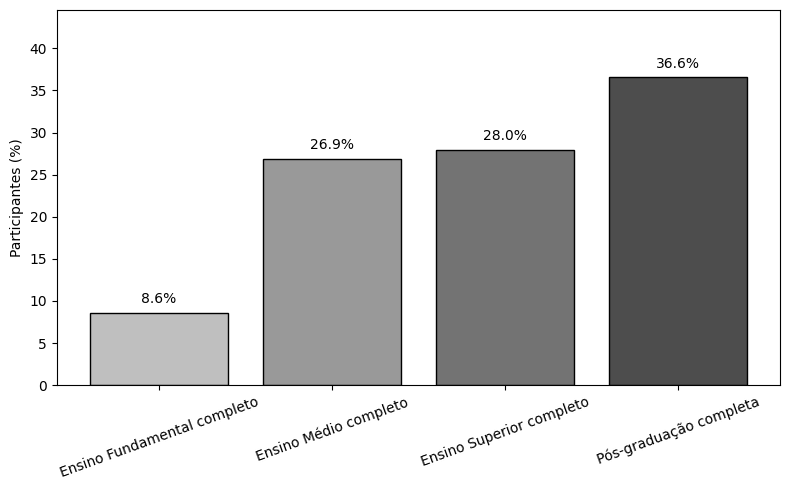

In [172]:
import matplotlib.pyplot as plt

dados_escolaridade = (
    df_cons_final[col_escolaridade]
    .value_counts()
    .reindex([
        "Ensino Fundamental completo",
        "Ensino Médio completo",
        "Ensino Superior completo",
        "Pós-graduação completa"
    ])
)

percentuais_escolaridade = dados_escolaridade / len(df_cons_final) * 100

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    percentuais_escolaridade.index,
    percentuais_escolaridade.values,
    edgecolor="black",
    color=["0.75", "0.60", "0.45", "0.30"]
)

ax.set_ylabel("Participantes (%)")
ax.set_xlabel("")
ax.set_ylim(0, max(percentuais_escolaridade.values) + 8)

ax.tick_params(axis="x", rotation=20)

for barra, valor in zip(barras, percentuais_escolaridade.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.8,
        f"{valor:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "grafico_escolaridade_consumidores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

sse é um gráfico de barras verticais (também chamado de gráfico de colunas).
Para a dissertação, eu colocaria a legenda assim:
Figura X – Distribuição dos consumidores participantes da pesquisa segundo o nível de escolaridade (n = 93).
E abaixo:
Fonte: Elaborado pela autora (2026).
Como os valores apresentados são percentuais, também podemos usar:
Figura X – Distribuição percentual dos consumidores segundo o nível de escolaridade (n = 93).

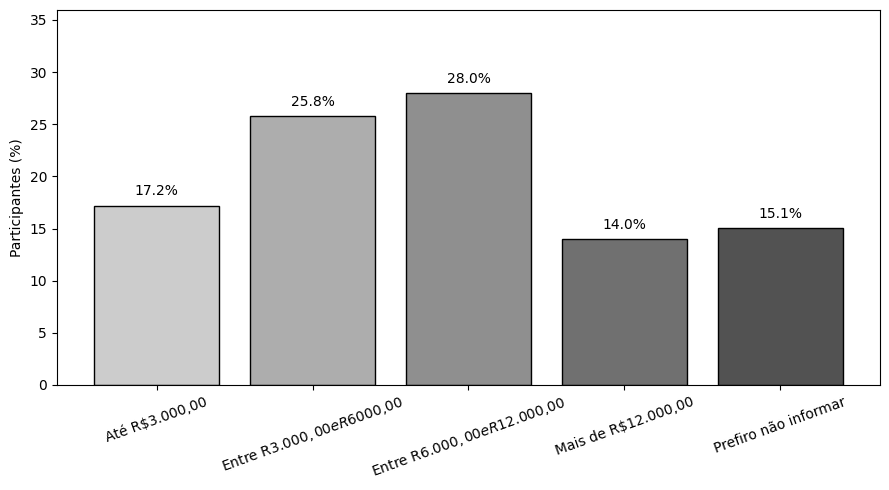

In [173]:
dados_renda = (
    df_cons_final["Renda familiar mensal (R$)"]
    .value_counts()
    .reindex([
        "Até R$3.000,00",
        "Entre R$3.000,00 e R$6000,00",
        "Entre R$6.000,00 e R$12.000,00",
        "Mais de R$12.000,00",
        "Prefiro não informar"
    ])
)

percentuais_renda = dados_renda / len(df_cons_final) * 100

fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(
    percentuais_renda.index,
    percentuais_renda.values,
    edgecolor="black",
    color=["0.80", "0.68", "0.56", "0.44", "0.32"]
)

ax.set_ylabel("Participantes (%)")
ax.set_xlabel("")
ax.set_ylim(0, max(percentuais_renda.values) + 8)

ax.tick_params(axis="x", rotation=20)

for barra, valor in zip(barras, percentuais_renda.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.7,
        f"{valor:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "grafico_renda_consumidores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

A legenda para a dissertação pode ficar:
Figura X – Distribuição percentual dos consumidores segundo a renda familiar mensal (n = 93).

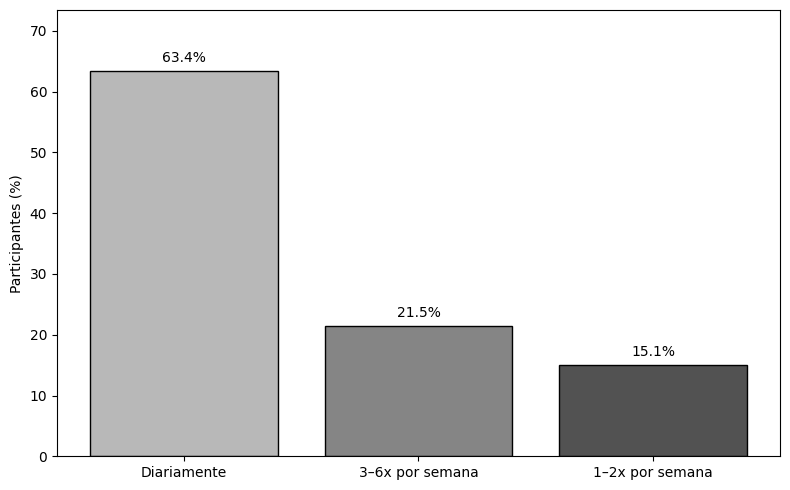

In [174]:
dados_frequencia = (
    df_cons_final[col_frequencia]
    .value_counts()
    .reindex([
        "Diariamente",
        "3–6x por semana",
        "1–2x por semana"
    ])
)

percentuais_frequencia = dados_frequencia / len(df_cons_final) * 100

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    percentuais_frequencia.index,
    percentuais_frequencia.values,
    edgecolor="black",
    color=["0.72", "0.52", "0.32"]
)

ax.set_ylabel("Participantes (%)")
ax.set_xlabel("")
ax.set_ylim(0, max(percentuais_frequencia.values) + 10)

for barra, valor in zip(barras, percentuais_frequencia.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"{valor:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "grafico_frequencia_consumo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição percentual dos consumidores segundo a frequência de consumo de leite ou derivados (n = 93).

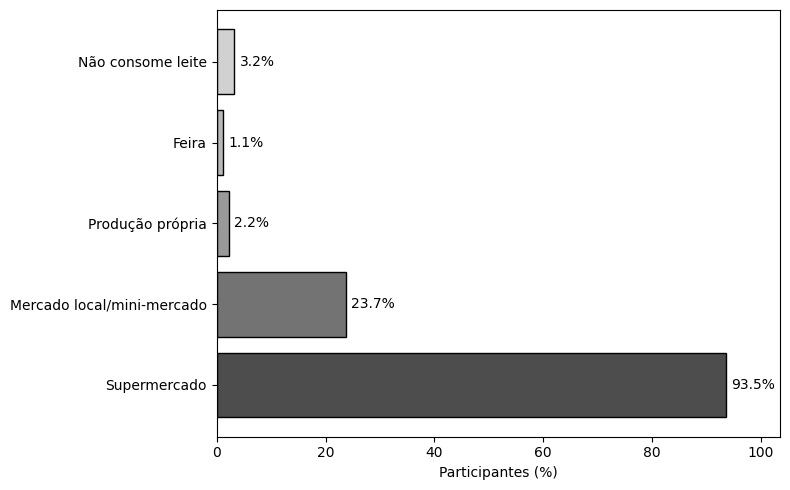

In [175]:
dados_locais = pd.Series({
    "Supermercado": 87,
    "Mercado local/mini-mercado": 22,
    "Produção própria": 2,
    "Feira": 1,
    "Não consome leite": 3
})

percentuais_locais = dados_locais / len(df_cons_final) * 100

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.barh(
    percentuais_locais.index,
    percentuais_locais.values,
    edgecolor="black",
    color=["0.30", "0.45", "0.60", "0.72", "0.82"]
)

ax.set_xlabel("Participantes (%)")
ax.set_ylabel("")
ax.set_xlim(0, max(percentuais_locais.values) + 10)

for barra, valor in zip(barras, percentuais_locais.values):
    ax.text(
        barra.get_width() + 1,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.1f}%",
        va="center"
    )

plt.tight_layout()

plt.savefig(
    "grafico_local_compra.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Legenda para a dissertação:
Figura X – Distribuição percentual dos consumidores segundo o local de compra do leite (n = 93).
E depois colocamos uma nota:
Nota: questão de múltipla escolha; os percentuais não totalizam 100%.

In [ ]:
Figura X – Distribuição percentual dos consumidores segundo o local de compra do leite (n = 93).

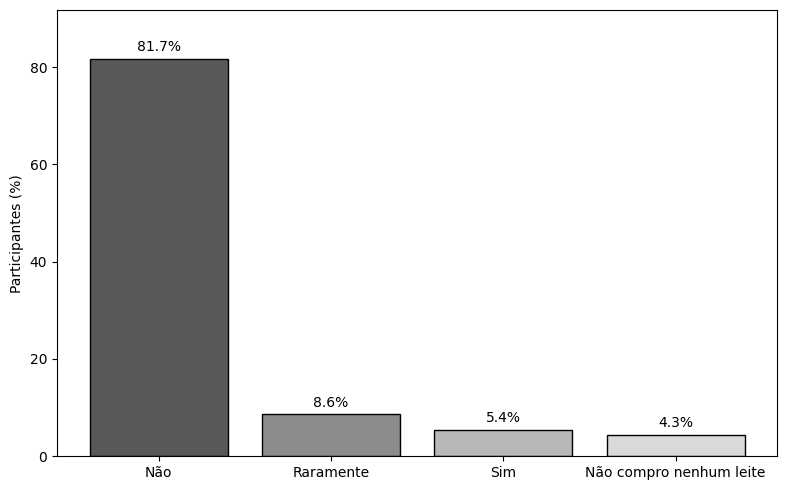

In [176]:
dados_selo = (
    df_cons_final[col_selo]
    .value_counts()
    .reindex([
        "Não",
        "Raramente",
        "Sim",
        "Não compro nenhum leite"
    ])
)

percentuais_selo = dados_selo / len(df_cons_final) * 100

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    percentuais_selo.index,
    percentuais_selo.values,
    edgecolor="black",
    color=["0.35", "0.55", "0.72", "0.85"]
)

ax.set_ylabel("Participantes (%)")
ax.set_xlabel("")
ax.set_ylim(0, max(percentuais_selo.values) + 10)

for barra, valor in zip(barras, percentuais_selo.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"{valor:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "grafico_compra_leite_selo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição percentual dos consumidores segundo o hábito de compra de leite com selo (n = 93).

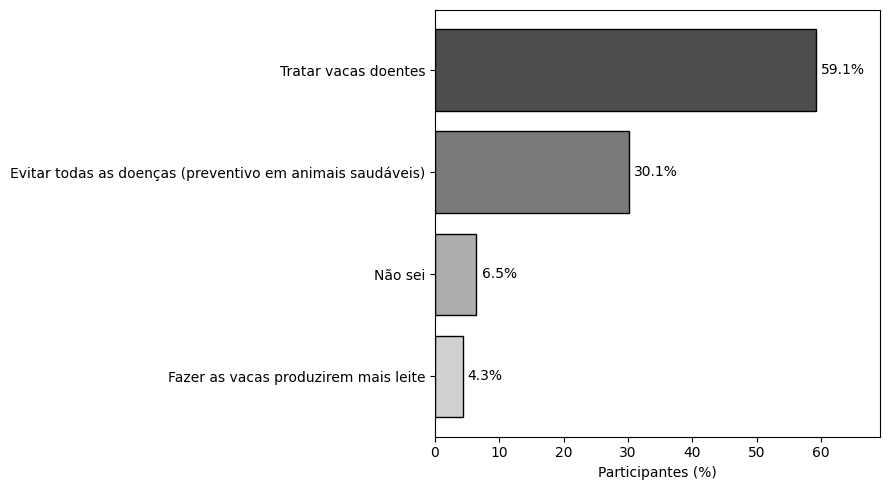

In [177]:
dados_uso = (
    df_cons_final[col_uso_antibiotico]
    .value_counts()
    .reindex([
        "Tratar vacas doentes",
        "Evitar todas as doenças (preventivo em animais saudáveis)",
        "Não sei",
        "Fazer as vacas produzirem mais leite"
    ])
)

percentuais_uso = dados_uso / len(df_cons_final) * 100

fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.barh(
    percentuais_uso.index,
    percentuais_uso.values,
    edgecolor="black",
    color=["0.30", "0.48", "0.68", "0.82"]
)

ax.set_xlabel("Participantes (%)")
ax.set_ylabel("")
ax.set_xlim(0, max(percentuais_uso.values) + 10)

ax.invert_yaxis()

for barra, valor in zip(barras, percentuais_uso.values):
    ax.text(
        barra.get_width() + 0.8,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.1f}%",
        va="center"
    )

plt.tight_layout()

plt.savefig(
    "grafico_percepcao_uso_antibioticos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição percentual das respostas dos consumidores sobre o principal uso dos antibióticos na pecuária leiteira (n = 93).

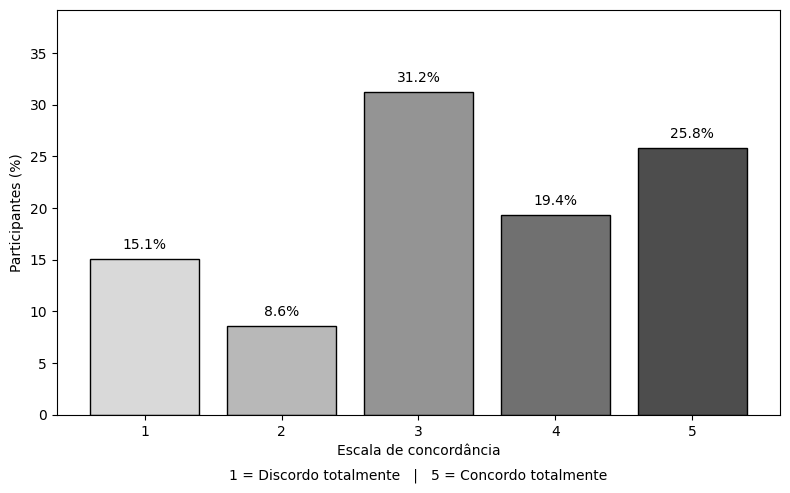

In [178]:
dados_preocupacao = (
    df_cons_final[col_preocupacao]
    .value_counts()
    .sort_index()
)

percentuais_preocupacao = dados_preocupacao / len(df_cons_final) * 100

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    percentuais_preocupacao.index.astype(str),
    percentuais_preocupacao.values,
    edgecolor="black",
    color=["0.85", "0.72", "0.58", "0.44", "0.30"]
)

ax.set_xlabel("Escala de concordância")
ax.set_ylabel("Participantes (%)")
ax.set_ylim(0, max(percentuais_preocupacao.values) + 8)

for barra, valor in zip(barras, percentuais_preocupacao.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.7,
        f"{valor:.1f}%",
        ha="center",
        va="bottom"
    )

ax.text(
    0.5,
    -0.16,
    "1 = Discordo totalmente   |   5 = Concordo totalmente",
    transform=ax.transAxes,
    ha="center"
)

plt.tight_layout()

plt.savefig(
    "grafico_preocupacao_residuos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição percentual das respostas dos consumidores à afirmação “Estou preocupado(a) com a presença de resíduos de antibióticos no leite” (n = 93).

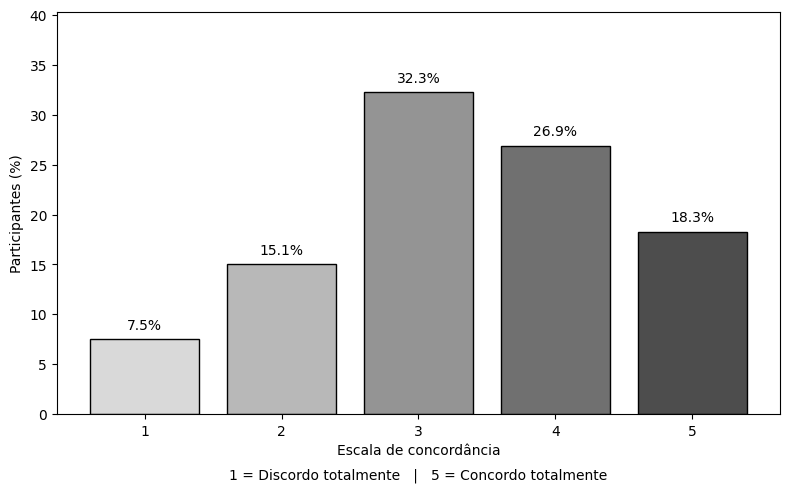

In [179]:
dados_seguranca = (
    df_cons_final[col_seguranca]
    .value_counts()
    .sort_index()
)

percentuais_seguranca = dados_seguranca / len(df_cons_final) * 100

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    percentuais_seguranca.index.astype(str),
    percentuais_seguranca.values,
    edgecolor="black",
    color=["0.85", "0.72", "0.58", "0.44", "0.30"]
)

ax.set_xlabel("Escala de concordância")
ax.set_ylabel("Participantes (%)")
ax.set_ylim(0, max(percentuais_seguranca.values) + 8)

for barra, valor in zip(barras, percentuais_seguranca.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.7,
        f"{valor:.1f}%",
        ha="center",
        va="bottom"
    )

ax.text(
    0.5,
    -0.16,
    "1 = Discordo totalmente   |   5 = Concordo totalmente",
    transform=ax.transAxes,
    ha="center"
)

plt.tight_layout()

plt.savefig(
    "grafico_seguranca_leite.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição percentual das respostas dos consumidores à afirmação “Acredito que o leite vendido no Brasil/na minha cidade é, na maioria das vezes, seguro quanto a resíduos de antibióticos” (n = 93).

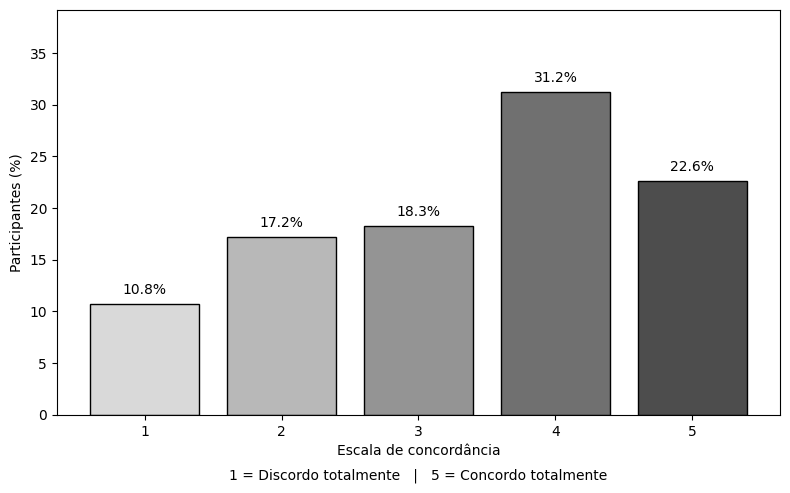

In [180]:
dados_confianca = (
    df_cons_final[col_confianca]
    .value_counts()
    .sort_index()
)

percentuais_confianca = dados_confianca / len(df_cons_final) * 100

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    percentuais_confianca.index.astype(str),
    percentuais_confianca.values,
    edgecolor="black",
    color=["0.85", "0.72", "0.58", "0.44", "0.30"]
)

ax.set_xlabel("Escala de concordância")
ax.set_ylabel("Participantes (%)")
ax.set_ylim(0, max(percentuais_confianca.values) + 8)

for barra, valor in zip(barras, percentuais_confianca.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.7,
        f"{valor:.1f}%",
        ha="center",
        va="bottom"
    )

ax.text(
    0.5,
    -0.16,
    "1 = Discordo totalmente   |   5 = Concordo totalmente",
    transform=ax.transAxes,
    ha="center"
)

plt.tight_layout()

plt.savefig(
    "grafico_confianca_fiscalizacao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição percentual das respostas dos consumidores à afirmação “Confio nas instituições que fiscalizam a qualidade do leite” (n = 93).

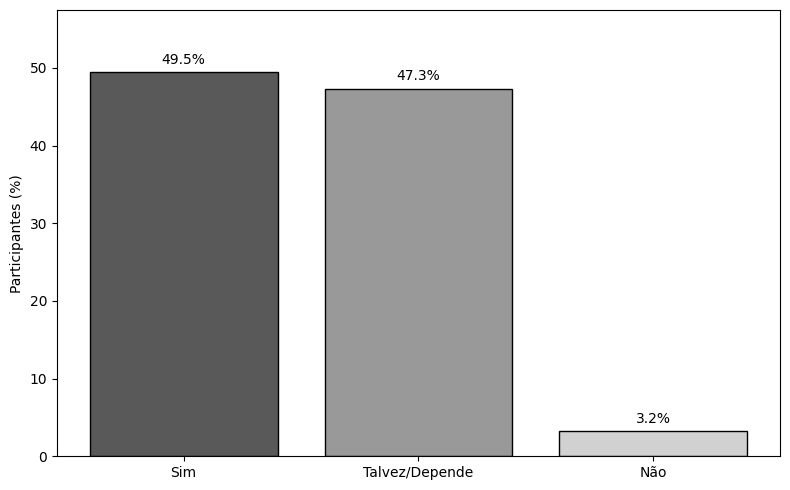

In [181]:
dados_interesse = (
    df_cons_final[col_interesse]
    .value_counts()
    .reindex([
        "Sim",
        "Talvez/Depende",
        "Não"
    ])
)

percentuais_interesse = dados_interesse / len(df_cons_final) * 100

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    percentuais_interesse.index,
    percentuais_interesse.values,
    edgecolor="black",
    color=["0.35", "0.60", "0.82"]
)

ax.set_ylabel("Participantes (%)")
ax.set_xlabel("")
ax.set_ylim(0, max(percentuais_interesse.values) + 8)

for barra, valor in zip(barras, percentuais_interesse.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.7,
        f"{valor:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "grafico_interesse_compra_selo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição percentual dos consumidores segundo o interesse em comprar leite com selo “Livre de Antibióticos” (n = 93).

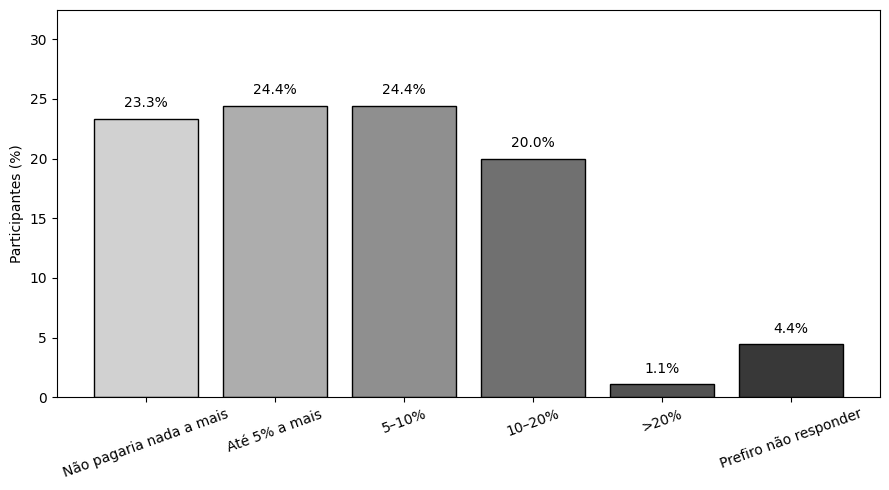

In [182]:
dados_dap = (
    df_dap_elegiveis[col_pagar]
    .value_counts(dropna=False)
    .reindex([
        "Não pagaria nada a mais",
        "Até 5% a mais",
        "5–10%",
        "10–20%",
        ">20%",
        "Prefiro não responder"
    ])
)

percentuais_dap = dados_dap / len(df_dap_elegiveis) * 100

fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(
    percentuais_dap.index,
    percentuais_dap.values,
    edgecolor="black",
    color=["0.82", "0.68", "0.56", "0.44", "0.32", "0.22"]
)

ax.set_ylabel("Participantes (%)")
ax.set_xlabel("")
ax.set_ylim(0, max(percentuais_dap.values) + 8)

ax.tick_params(axis="x", rotation=20)

for barra, valor in zip(barras, percentuais_dap.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.7,
        f"{valor:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "grafico_disposicao_pagar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição percentual da disposição a pagar por litro de leite entre consumidores que manifestaram interesse ou possível interesse em comprar leite com selo “Livre de Antibióticos” (n = 90).

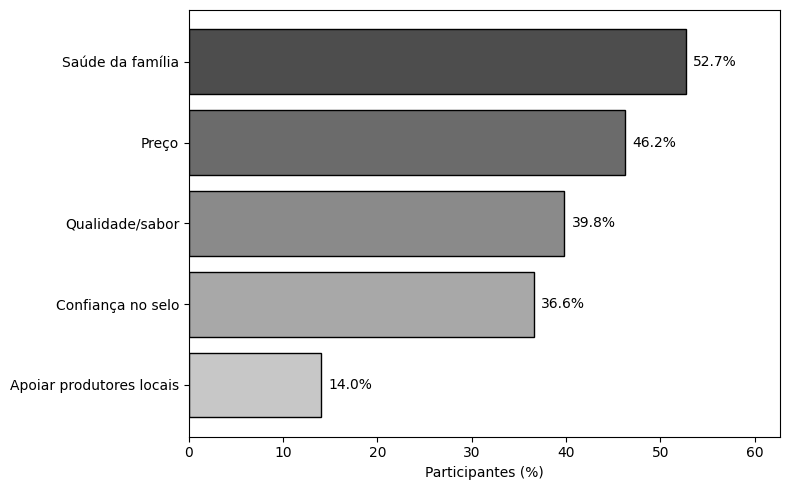

In [183]:
dados_motivos = pd.Series({
    "Saúde da família": 49,
    "Preço": 43,
    "Qualidade/sabor": 37,
    "Confiança no selo": 34,
    "Apoiar produtores locais": 13
})

percentuais_motivos = dados_motivos / len(df_cons_final) * 100

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.barh(
    percentuais_motivos.index,
    percentuais_motivos.values,
    edgecolor="black",
    color=["0.30", "0.42", "0.54", "0.66", "0.78"]
)

ax.set_xlabel("Participantes (%)")
ax.set_ylabel("")
ax.set_xlim(0, max(percentuais_motivos.values) + 10)

ax.invert_yaxis()

for barra, valor in zip(barras, percentuais_motivos.values):
    ax.text(
        barra.get_width() + 0.8,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.1f}%",
        va="center"
    )

plt.tight_layout()

plt.savefig(
    "grafico_motivos_compra.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Motivos que influenciam a compra de leite entre os consumidores participantes da pesquisa (n = 93).

/tmp/ipykernel_3523/3227174425.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


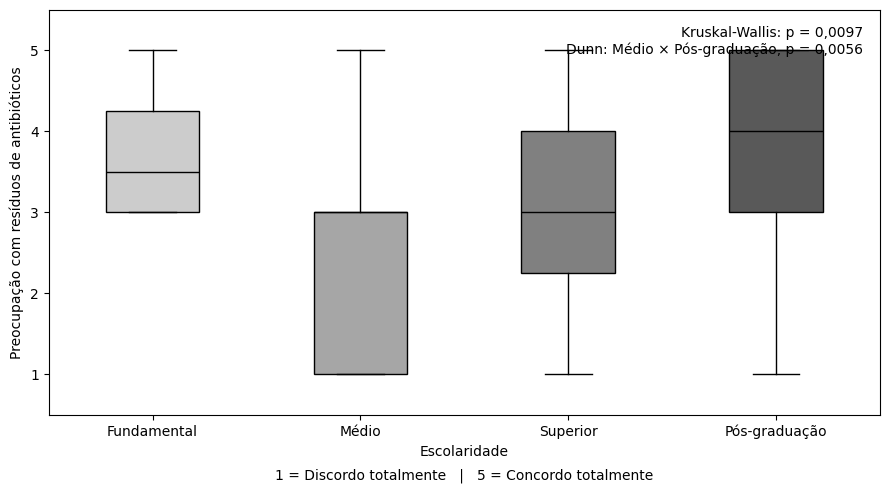

In [184]:
ordem_escolaridade = [
    "Ensino Fundamental completo",
    "Ensino Médio completo",
    "Ensino Superior completo",
    "Pós-graduação completa"
]

dados_box = [
    df_cons_final.loc[
        df_cons_final[col_escolaridade] == grupo,
        col_preocupacao
    ].dropna()
    for grupo in ordem_escolaridade
]

fig, ax = plt.subplots(figsize=(9, 5))

bp = ax.boxplot(
    dados_box,
    labels=[
        "Fundamental",
        "Médio",
        "Superior",
        "Pós-graduação"
    ],
    patch_artist=True,
    showfliers=False
)

tons = ["0.80", "0.65", "0.50", "0.35"]

for caixa, tom in zip(bp["boxes"], tons):
    caixa.set_facecolor(tom)
    caixa.set_edgecolor("black")

for elemento in ["whiskers", "caps", "medians"]:
    for item in bp[elemento]:
        item.set_color("black")

ax.set_ylabel("Preocupação com resíduos de antibióticos")
ax.set_xlabel("Escolaridade")
ax.set_ylim(0.5, 5.5)
ax.set_yticks([1, 2, 3, 4, 5])

ax.text(
    0.5,
    -0.16,
    "1 = Discordo totalmente   |   5 = Concordo totalmente",
    transform=ax.transAxes,
    ha="center"
)

ax.text(
    0.98,
    0.96,
    "Kruskal-Wallis: p = 0,0097\nDunn: Médio × Pós-graduação, p = 0,0056",
    transform=ax.transAxes,
    ha="right",
    va="top"
)

plt.tight_layout()

plt.savefig(
    "grafico_escolaridade_preocupacao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

/tmp/ipykernel_3523/2291600609.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


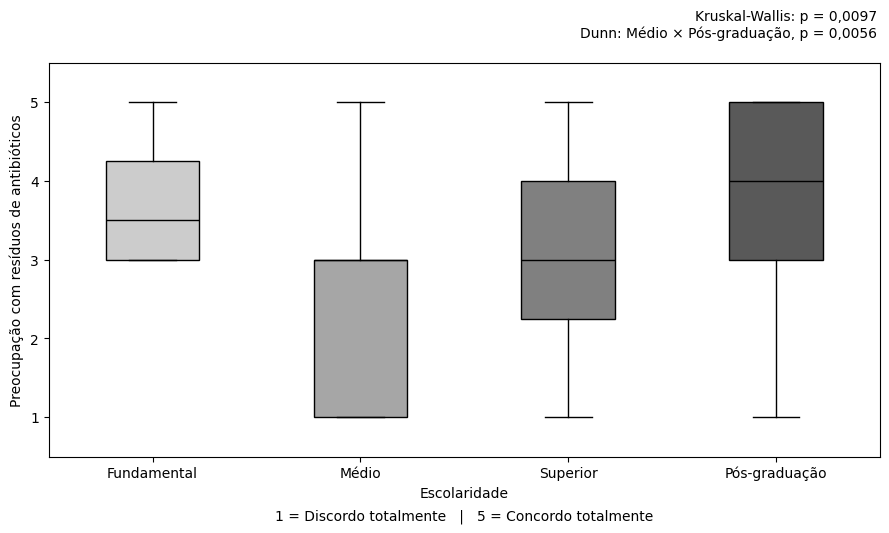

In [185]:
ordem_escolaridade = [
    "Ensino Fundamental completo",
    "Ensino Médio completo",
    "Ensino Superior completo",
    "Pós-graduação completa"
]

dados_box = [
    df_cons_final.loc[
        df_cons_final[col_escolaridade] == grupo,
        col_preocupacao
    ].dropna()
    for grupo in ordem_escolaridade
]

fig, ax = plt.subplots(figsize=(9, 5.5))

bp = ax.boxplot(
    dados_box,
    labels=[
        "Fundamental",
        "Médio",
        "Superior",
        "Pós-graduação"
    ],
    patch_artist=True,
    showfliers=False
)

tons = ["0.80", "0.65", "0.50", "0.35"]

for caixa, tom in zip(bp["boxes"], tons):
    caixa.set_facecolor(tom)
    caixa.set_edgecolor("black")

for elemento in ["whiskers", "caps", "medians"]:
    for item in bp[elemento]:
        item.set_color("black")

ax.set_ylabel("Preocupação com resíduos de antibióticos")
ax.set_xlabel("Escolaridade")
ax.set_ylim(0.5, 5.5)
ax.set_yticks([1, 2, 3, 4, 5])

ax.text(
    0.5,
    -0.16,
    "1 = Discordo totalmente   |   5 = Concordo totalmente",
    transform=ax.transAxes,
    ha="center"
)

# anotação fora da área do gráfico
fig.text(
    0.98,
    0.97,
    "Kruskal-Wallis: p = 0,0097\nDunn: Médio × Pós-graduação, p = 0,0056",
    ha="right",
    va="top"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.savefig(
    "grafico_escolaridade_preocupacao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição dos níveis de preocupação com resíduos de antibióticos segundo a escolaridade dos consumidores (n = 93).

/tmp/ipykernel_3523/3400468097.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


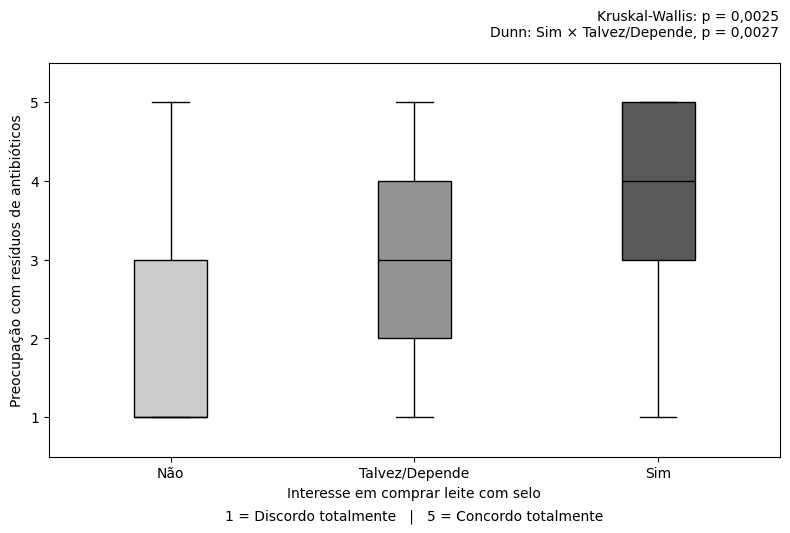

In [186]:
ordem_interesse = [
    "Não",
    "Talvez/Depende",
    "Sim"
]

dados_box_interesse = [
    df_cons_final.loc[
        df_cons_final[col_interesse] == grupo,
        col_preocupacao
    ].dropna()
    for grupo in ordem_interesse
]

fig, ax = plt.subplots(figsize=(8, 5.5))

bp = ax.boxplot(
    dados_box_interesse,
    labels=[
        "Não",
        "Talvez/Depende",
        "Sim"
    ],
    patch_artist=True,
    showfliers=False
)

tons = ["0.80", "0.58", "0.35"]

for caixa, tom in zip(bp["boxes"], tons):
    caixa.set_facecolor(tom)
    caixa.set_edgecolor("black")

for elemento in ["whiskers", "caps", "medians"]:
    for item in bp[elemento]:
        item.set_color("black")

ax.set_ylabel("Preocupação com resíduos de antibióticos")
ax.set_xlabel("Interesse em comprar leite com selo")
ax.set_ylim(0.5, 5.5)
ax.set_yticks([1, 2, 3, 4, 5])

ax.text(
    0.5,
    -0.16,
    "1 = Discordo totalmente   |   5 = Concordo totalmente",
    transform=ax.transAxes,
    ha="center"
)

fig.text(
    0.98,
    0.97,
    "Kruskal-Wallis: p = 0,0025\nDunn: Sim × Talvez/Depende, p = 0,0027",
    ha="right",
    va="top"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.savefig(
    "grafico_preocupacao_interesse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição dos níveis de preocupação com resíduos de antibióticos segundo o interesse em comprar leite com selo “Livre de Antibióticos” (n = 93).

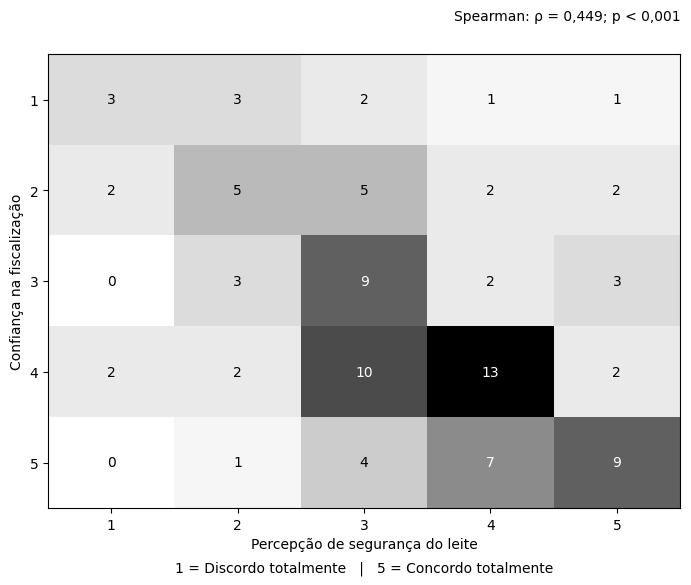

In [187]:
tabela_conf_seg = pd.crosstab(
    df_cons_final[col_confianca],
    df_cons_final[col_seguranca]
)

fig, ax = plt.subplots(figsize=(7, 6))

imagem = ax.imshow(
    tabela_conf_seg.values,
    cmap="Greys",
    aspect="auto"
)

ax.set_xticks(range(len(tabela_conf_seg.columns)))
ax.set_xticklabels(tabela_conf_seg.columns)

ax.set_yticks(range(len(tabela_conf_seg.index)))
ax.set_yticklabels(tabela_conf_seg.index)

ax.set_xlabel("Percepção de segurança do leite")
ax.set_ylabel("Confiança na fiscalização")

for i in range(tabela_conf_seg.shape[0]):
    for j in range(tabela_conf_seg.shape[1]):
        valor = tabela_conf_seg.iloc[i, j]

        ax.text(
            j,
            i,
            str(valor),
            ha="center",
            va="center",
            color="black" if valor < tabela_conf_seg.values.max()/2 else "white"
        )

fig.text(
    0.98,
    0.97,
    "Spearman: ρ = 0,449; p < 0,001",
    ha="right",
    va="top"
)

ax.text(
    0.5,
    -0.14,
    "1 = Discordo totalmente   |   5 = Concordo totalmente",
    transform=ax.transAxes,
    ha="center"
)

plt.tight_layout(rect=[0, 0, 1, 0.92])

plt.savefig(
    "grafico_confianca_seguranca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição conjunta das respostas de confiança na fiscalização e percepção de segurança do leite quanto a resíduos de antibióticos (n = 93).

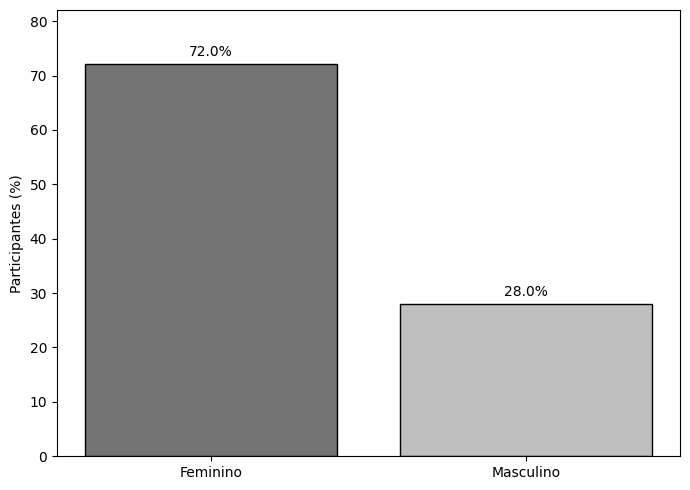

In [188]:
dados_sexo = (
    df_cons_final["Sexo"]
    .value_counts()
    .reindex([
        "Feminino",
        "Masculino"
    ])
)

percentuais_sexo = dados_sexo / len(df_cons_final) * 100

fig, ax = plt.subplots(figsize=(7, 5))

barras = ax.bar(
    percentuais_sexo.index,
    percentuais_sexo.values,
    edgecolor="black",
    color=["0.45", "0.75"]
)

ax.set_ylabel("Participantes (%)")
ax.set_xlabel("")
ax.set_ylim(0, max(percentuais_sexo.values) + 10)

for barra, valor in zip(barras, percentuais_sexo.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"{valor:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "grafico_sexo_consumidores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

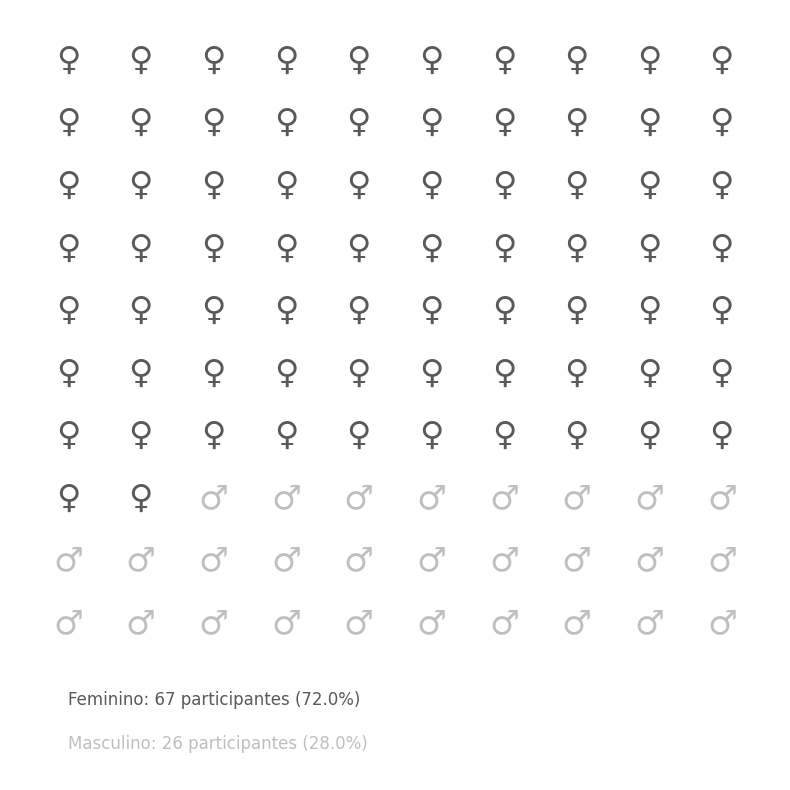

In [189]:
import matplotlib.pyplot as plt

# dados
n_total = 93
n_feminino = 67
n_masculino = 26

perc_feminino = round(n_feminino / n_total * 100)
perc_masculino = round(n_masculino / n_total * 100)

# cria lista com 100 símbolos
icones = ["♀"] * perc_feminino + ["♂"] * perc_masculino
cores = ["0.35"] * perc_feminino + ["0.75"] * perc_masculino

fig, ax = plt.subplots(figsize=(8, 8))

# desenha em grade 10 x 10
for i, (icone, cor) in enumerate(zip(icones, cores)):
    x = i % 10
    y = 9 - (i // 10)
    ax.text(
        x, y, icone,
        fontsize=24,
        ha="center",
        va="center",
        color=cor
    )

# legenda textual
ax.text(
    0, -1.3,
    f"Feminino: {n_feminino} participantes ({n_feminino/n_total*100:.1f}%)",
    fontsize=12,
    ha="left",
    color="0.35"
)

ax.text(
    0, -2.0,
    f"Masculino: {n_masculino} participantes ({n_masculino/n_total*100:.1f}%)",
    fontsize=12,
    ha="left",
    color="0.75"
)

ax.set_xlim(-0.8, 9.8)
ax.set_ylim(-2.5, 9.8)
ax.axis("off")

plt.tight_layout()

plt.savefig(
    "grafico_pictograma_sexo_consumidores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

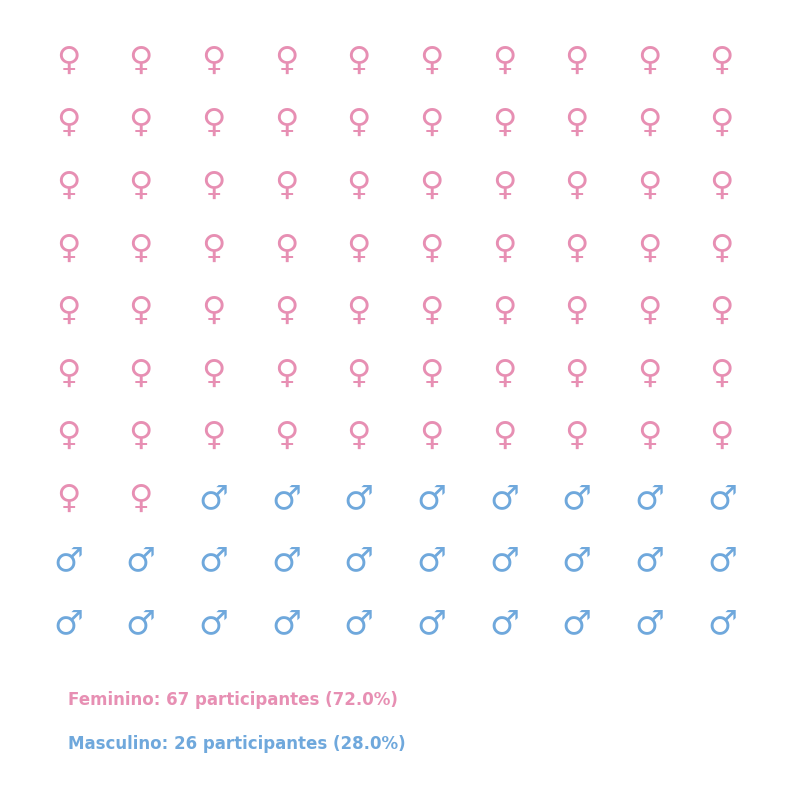

In [190]:
import matplotlib.pyplot as plt

# dados
n_total = 93
n_feminino = 67
n_masculino = 26

perc_feminino = round(n_feminino / n_total * 100)
perc_masculino = round(n_masculino / n_total * 100)

# cores específicas somente para este gráfico
rosa = "#E78FB3"
azul = "#6FA8DC"

# cria lista com 100 símbolos
icones = ["♀"] * perc_feminino + ["♂"] * perc_masculino
cores = [rosa] * perc_feminino + [azul] * perc_masculino

fig, ax = plt.subplots(figsize=(8, 8))

# desenha em grade 10 x 10
for i, (icone, cor) in enumerate(zip(icones, cores)):
    x = i % 10
    y = 9 - (i // 10)

    ax.text(
        x,
        y,
        icone,
        fontsize=24,
        ha="center",
        va="center",
        color=cor
    )

# legenda textual
ax.text(
    0,
    -1.3,
    f"Feminino: {n_feminino} participantes ({n_feminino/n_total*100:.1f}%)",
    fontsize=12,
    ha="left",
    color=rosa,
    fontweight="bold"
)

ax.text(
    0,
    -2.0,
    f"Masculino: {n_masculino} participantes ({n_masculino/n_total*100:.1f}%)",
    fontsize=12,
    ha="left",
    color=azul,
    fontweight="bold"
)

ax.set_xlim(-0.8, 9.8)
ax.set_ylim(-2.5, 9.8)
ax.axis("off")

plt.tight_layout()

plt.savefig(
    "grafico_pictograma_sexo_consumidores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição percentual dos consumidores segundo o sexo (n = 93).

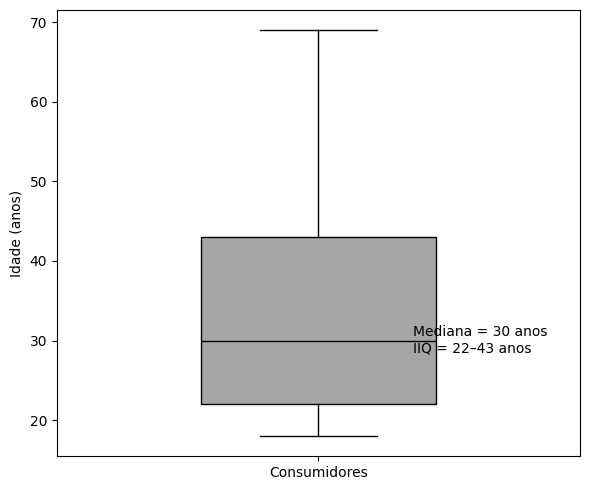

In [191]:
fig, ax = plt.subplots(figsize=(6, 5))

bp = ax.boxplot(
    df_cons_final["Idade_num"].dropna(),
    vert=True,
    patch_artist=True,
    widths=0.45,
    showfliers=True
)

bp["boxes"][0].set_facecolor("0.65")
bp["boxes"][0].set_edgecolor("black")

for elemento in ["whiskers", "caps", "medians"]:
    for item in bp[elemento]:
        item.set_color("black")

ax.set_ylabel("Idade (anos)")
ax.set_xticks([1])
ax.set_xticklabels(["Consumidores"])

ax.text(
    1.18,
    30,
    "Mediana = 30 anos\nIIQ = 22–43 anos",
    va="center"
)

plt.tight_layout()

plt.savefig(
    "grafico_idade_consumidores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

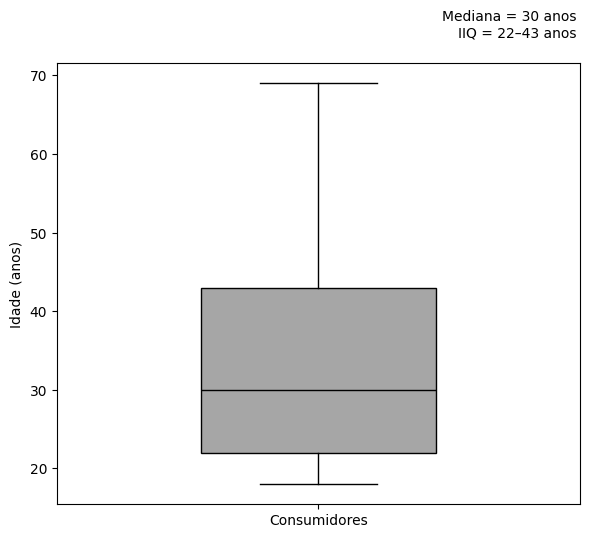

In [192]:
fig, ax = plt.subplots(figsize=(6, 5.5))

bp = ax.boxplot(
    df_cons_final["Idade_num"].dropna(),
    vert=True,
    patch_artist=True,
    widths=0.45,
    showfliers=True
)

bp["boxes"][0].set_facecolor("0.65")
bp["boxes"][0].set_edgecolor("black")

for elemento in ["whiskers", "caps", "medians"]:
    for item in bp[elemento]:
        item.set_color("black")

ax.set_ylabel("Idade (anos)")
ax.set_xticks([1])
ax.set_xticklabels(["Consumidores"])

fig.text(
    0.97,
    0.97,
    "Mediana = 30 anos\nIIQ = 22–43 anos",
    ha="right",
    va="top"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.savefig(
    "grafico_idade_consumidores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição da idade dos consumidores participantes da pesquisa (n = 93).

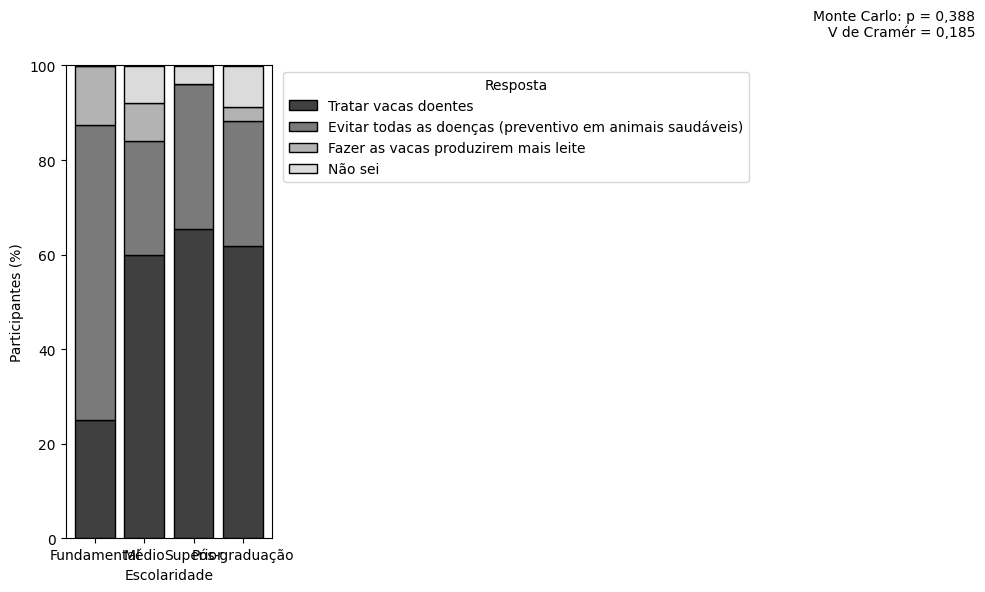

In [193]:
# tabela percentual por escolaridade
tabela_perc_escolaridade = pd.crosstab(
    df_cons_final[col_escolaridade],
    df_cons_final[col_uso_antibiotico],
    normalize="index"
) * 100

ordem_escolaridade = [
    "Ensino Fundamental completo",
    "Ensino Médio completo",
    "Ensino Superior completo",
    "Pós-graduação completa"
]

ordem_respostas = [
    "Tratar vacas doentes",
    "Evitar todas as doenças (preventivo em animais saudáveis)",
    "Fazer as vacas produzirem mais leite",
    "Não sei"
]

tabela_perc_escolaridade = (
    tabela_perc_escolaridade
    .reindex(index=ordem_escolaridade, columns=ordem_respostas)
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(10, 6))

tons = ["0.25", "0.48", "0.70", "0.86"]

base = np.zeros(len(tabela_perc_escolaridade))

for resposta, tom in zip(ordem_respostas, tons):
    valores = tabela_perc_escolaridade[resposta].values

    ax.bar(
        ["Fundamental", "Médio", "Superior", "Pós-graduação"],
        valores,
        bottom=base,
        label=resposta,
        edgecolor="black",
        color=tom
    )

    base += valores

ax.set_ylabel("Participantes (%)")
ax.set_xlabel("Escolaridade")
ax.set_ylim(0, 100)

ax.legend(
    title="Resposta",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

fig.text(
    0.98,
    0.98,
    "Monte Carlo: p = 0,388\nV de Cramér = 0,185",
    ha="right",
    va="top"
)

plt.tight_layout(rect=[0, 0, 0.78, 0.92])

plt.savefig(
    "grafico_escolaridade_percepcao_antibioticos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

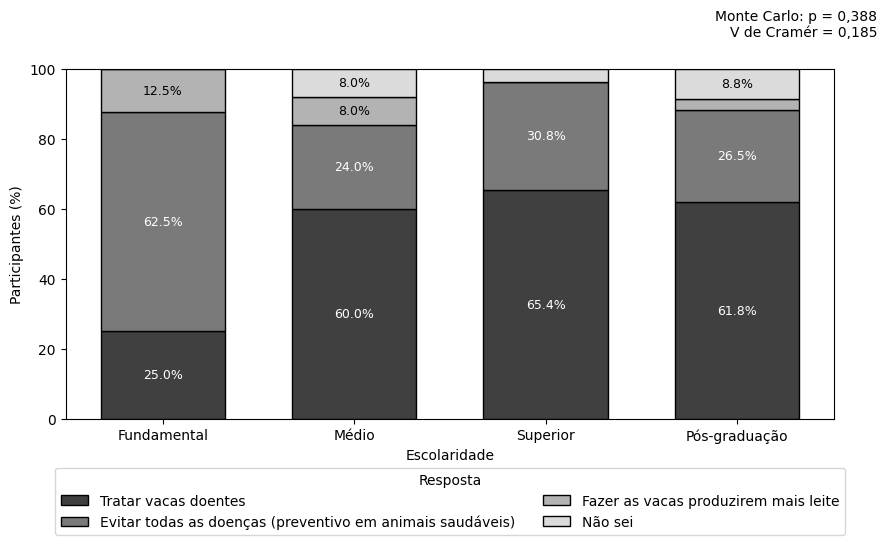

In [195]:
tabela_perc_escolaridade = pd.crosstab(
    df_cons_final[col_escolaridade],
    df_cons_final[col_uso_antibiotico],
    normalize="index"
) * 100

ordem_escolaridade = [
    "Ensino Fundamental completo",
    "Ensino Médio completo",
    "Ensino Superior completo",
    "Pós-graduação completa"
]

ordem_respostas = [
    "Tratar vacas doentes",
    "Evitar todas as doenças (preventivo em animais saudáveis)",
    "Fazer as vacas produzirem mais leite",
    "Não sei"
]

tabela_perc_escolaridade = (
    tabela_perc_escolaridade
    .reindex(index=ordem_escolaridade, columns=ordem_respostas)
    .fillna(0)
)

rotulos = [
    "Fundamental",
    "Médio",
    "Superior",
    "Pós-graduação"
]

fig, ax = plt.subplots(figsize=(9, 6.5))

tons = ["0.25", "0.48", "0.70", "0.86"]

base = np.zeros(len(rotulos))

for resposta, tom in zip(ordem_respostas, tons):
    valores = tabela_perc_escolaridade[resposta].values

    barras = ax.bar(
        rotulos,
        valores,
        bottom=base,
        label=resposta,
        edgecolor="black",
        color=tom,
        width=0.65
    )

    for i, valor in enumerate(valores):
        if valor >= 8:
            ax.text(
                i,
                base[i] + valor / 2,
                f"{valor:.1f}%",
                ha="center",
                va="center",
                fontsize=9,
                color="white" if tom in ["0.25", "0.48"] else "black"
            )

    base += valores

ax.set_ylabel("Participantes (%)")
ax.set_xlabel("Escolaridade")
ax.set_ylim(0, 100)

fig.text(
    0.98,
    0.98,
    "Monte Carlo: p = 0,388\nV de Cramér = 0,185",
    ha="right",
    va="top"
)

ax.legend(
    title="Resposta",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=True
)

plt.tight_layout(rect=[0, 0.12, 1, 0.92])

plt.savefig(
    "grafico_escolaridade_percepcao_antibioticos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição percentual das respostas sobre o principal uso dos antibióticos segundo a escolaridade dos consumidores (n = 93).

/tmp/ipykernel_3523/1463197734.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


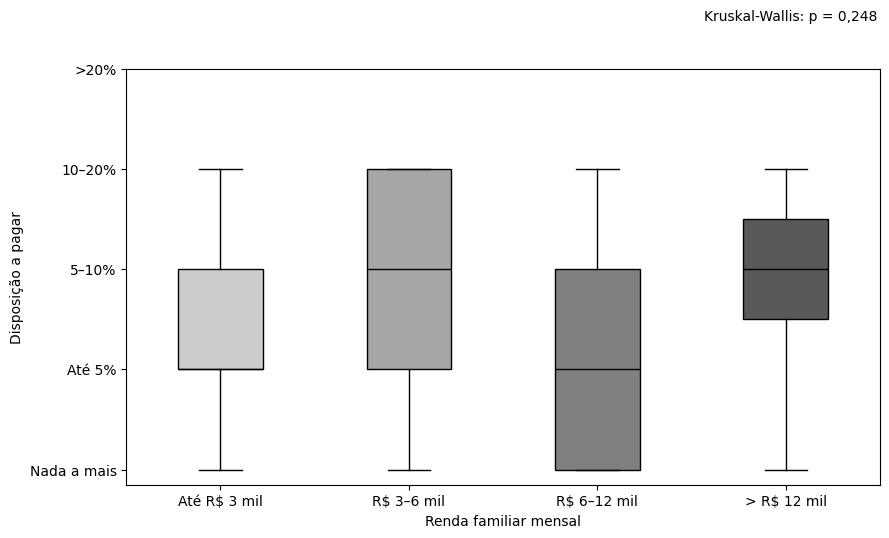

In [196]:
ordem_renda = [
    "Até R$3.000,00",
    "Entre R$3.000,00 e R$6000,00",
    "Entre R$6.000,00 e R$12.000,00",
    "Mais de R$12.000,00"
]

rotulos_renda = [
    "Até R$ 3 mil",
    "R$ 3–6 mil",
    "R$ 6–12 mil",
    "> R$ 12 mil"
]

dados_box_renda_dap = [
    df_renda_dap_final.loc[
        df_renda_dap_final["Renda familiar mensal (R$)"] == grupo,
        "disposicao_pagar_ord"
    ].dropna()
    for grupo in ordem_renda
]

fig, ax = plt.subplots(figsize=(9, 5.5))

bp = ax.boxplot(
    dados_box_renda_dap,
    labels=rotulos_renda,
    patch_artist=True,
    showfliers=False
)

tons = ["0.80", "0.65", "0.50", "0.35"]

for caixa, tom in zip(bp["boxes"], tons):
    caixa.set_facecolor(tom)
    caixa.set_edgecolor("black")

for elemento in ["whiskers", "caps", "medians"]:
    for item in bp[elemento]:
        item.set_color("black")

ax.set_ylabel("Disposição a pagar")
ax.set_xlabel("Renda familiar mensal")

ax.set_yticks([0, 1, 2, 3, 4])
ax.set_yticklabels([
    "Nada a mais",
    "Até 5%",
    "5–10%",
    "10–20%",
    ">20%"
])

fig.text(
    0.98,
    0.97,
    "Kruskal-Wallis: p = 0,248",
    ha="right",
    va="top"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.savefig(
    "grafico_renda_disposicao_pagar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição da disposição a pagar segundo a renda familiar mensal dos consumidores (n = 74).

/tmp/ipykernel_3523/2509380129.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


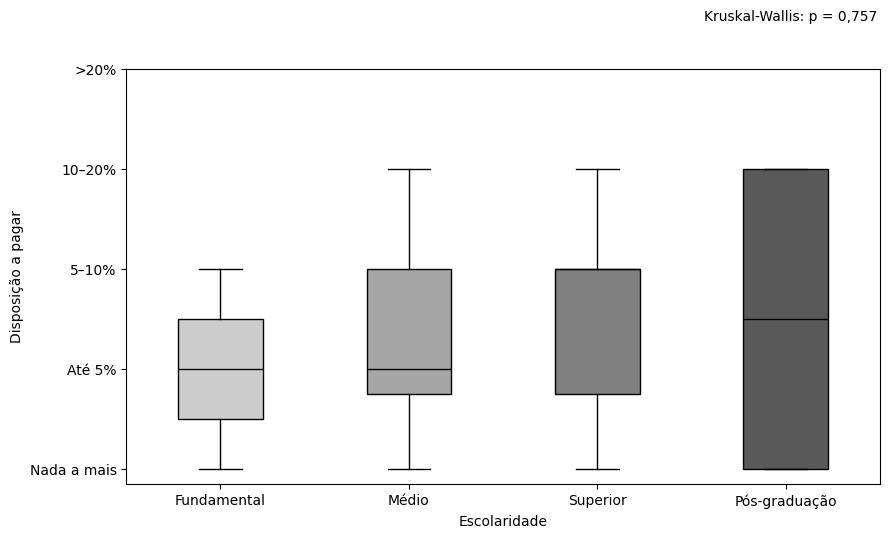

In [197]:
ordem_escolaridade = [
    "Ensino Fundamental completo",
    "Ensino Médio completo",
    "Ensino Superior completo",
    "Pós-graduação completa"
]

rotulos_escolaridade = [
    "Fundamental",
    "Médio",
    "Superior",
    "Pós-graduação"
]

dados_box_esc_dap = [
    df_esc_dap_final.loc[
        df_esc_dap_final[col_escolaridade] == grupo,
        "disposicao_pagar_ord"
    ].dropna()
    for grupo in ordem_escolaridade
]

fig, ax = plt.subplots(figsize=(9, 5.5))

bp = ax.boxplot(
    dados_box_esc_dap,
    labels=rotulos_escolaridade,
    patch_artist=True,
    showfliers=False
)

tons = ["0.80", "0.65", "0.50", "0.35"]

for caixa, tom in zip(bp["boxes"], tons):
    caixa.set_facecolor(tom)
    caixa.set_edgecolor("black")

for elemento in ["whiskers", "caps", "medians"]:
    for item in bp[elemento]:
        item.set_color("black")

ax.set_ylabel("Disposição a pagar")
ax.set_xlabel("Escolaridade")

ax.set_yticks([0, 1, 2, 3, 4])
ax.set_yticklabels([
    "Nada a mais",
    "Até 5%",
    "5–10%",
    "10–20%",
    ">20%"
])

fig.text(
    0.98,
    0.97,
    "Kruskal-Wallis: p = 0,757",
    ha="right",
    va="top"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.savefig(
    "grafico_escolaridade_disposicao_pagar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição da disposição a pagar segundo a escolaridade dos consumidores (n = 85).

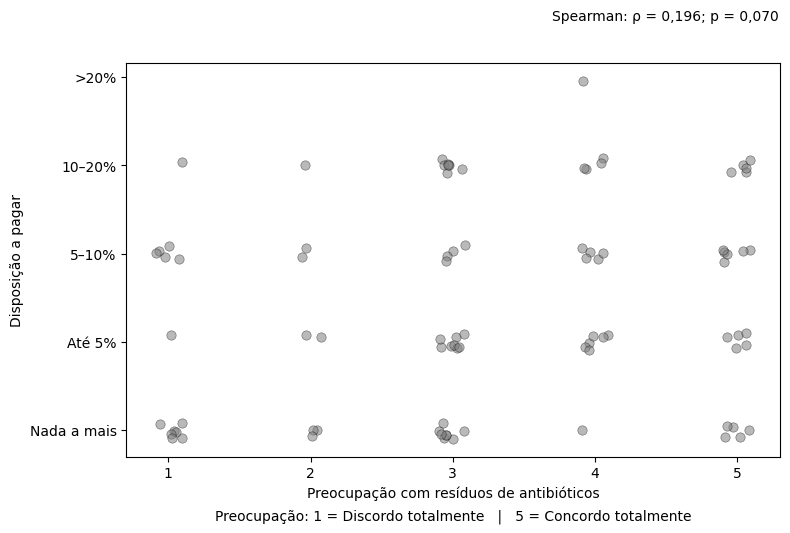

In [198]:
np.random.seed(42)

dados_plot = df_preocupacao_dap_final[
    [col_preocupacao, "disposicao_pagar_ord"]
].copy()

x_jitter = (
    dados_plot[col_preocupacao].values
    + np.random.uniform(-0.10, 0.10, len(dados_plot))
)

y_jitter = (
    dados_plot["disposicao_pagar_ord"].values
    + np.random.uniform(-0.10, 0.10, len(dados_plot))
)

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.scatter(
    x_jitter,
    y_jitter,
    s=45,
    alpha=0.55,
    edgecolor="black",
    linewidth=0.4,
    color="0.50"
)

ax.set_xlabel("Preocupação com resíduos de antibióticos")
ax.set_ylabel("Disposição a pagar")

ax.set_xticks([1, 2, 3, 4, 5])
ax.set_yticks([0, 1, 2, 3, 4])

ax.set_yticklabels([
    "Nada a mais",
    "Até 5%",
    "5–10%",
    "10–20%",
    ">20%"
])

fig.text(
    0.98,
    0.97,
    "Spearman: ρ = 0,196; p = 0,070",
    ha="right",
    va="top"
)

ax.text(
    0.5,
    -0.16,
    "Preocupação: 1 = Discordo totalmente   |   5 = Concordo totalmente",
    transform=ax.transAxes,
    ha="center"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.savefig(
    "grafico_preocupacao_disposicao_pagar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Agora vamos para preocupação com resíduos × disposição a pagar.
Como as duas variáveis são ordinais e a correlação de Spearman não foi significativa (ρ = 0,196; p = 0,070), aqui fica melhor usar um gráfico de dispersão com pequeno deslocamento dos pontos (jitter) para enxergar onde as respostas se concentram sem uma ficar exatamente em cima da outra.

Figura X – Relação entre preocupação com resíduos de antibióticos e disposição a pagar entre os consumidores (n = 87).

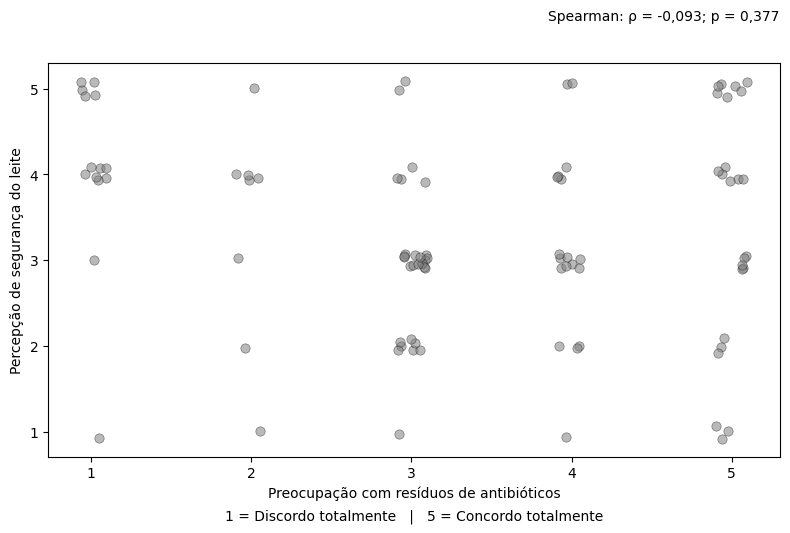

In [199]:
np.random.seed(42)

dados_plot = df_preoc_seg_final[
    [col_preocupacao, col_seguranca]
].copy()

x_jitter = (
    dados_plot[col_preocupacao].values
    + np.random.uniform(-0.10, 0.10, len(dados_plot))
)

y_jitter = (
    dados_plot[col_seguranca].values
    + np.random.uniform(-0.10, 0.10, len(dados_plot))
)

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.scatter(
    x_jitter,
    y_jitter,
    s=45,
    alpha=0.55,
    edgecolor="black",
    linewidth=0.4,
    color="0.50"
)

ax.set_xlabel("Preocupação com resíduos de antibióticos")
ax.set_ylabel("Percepção de segurança do leite")

ax.set_xticks([1, 2, 3, 4, 5])
ax.set_yticks([1, 2, 3, 4, 5])

fig.text(
    0.98,
    0.97,
    "Spearman: ρ = -0,093; p = 0,377",
    ha="right",
    va="top"
)

ax.text(
    0.5,
    -0.16,
    "1 = Discordo totalmente   |   5 = Concordo totalmente",
    transform=ax.transAxes,
    ha="center"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.savefig(
    "grafico_preocupacao_seguranca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

O próximo gráfico será preocupação com resíduos × percepção de segurança, que também foi uma correlação de Spearman não significativa.
Como as duas são escalas Likert de 1 a 5, vamos usar novamente um gráfico de dispersão com jitter.

Figura X – Relação entre preocupação com resíduos de antibióticos e percepção de segurança do leite entre os consumidores (n = 93).

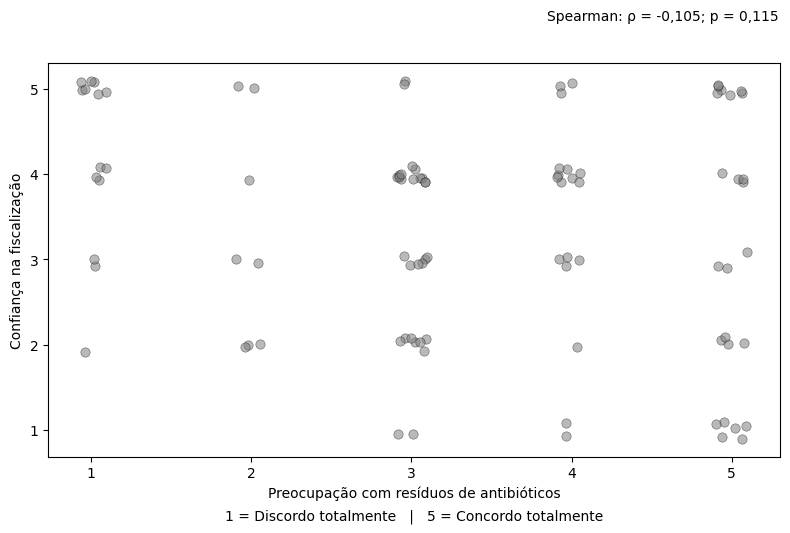

In [200]:
np.random.seed(42)

dados_plot = df_preoc_conf_final[
    [col_preocupacao, col_confianca]
].copy()

x_jitter = (
    dados_plot[col_preocupacao].values
    + np.random.uniform(-0.10, 0.10, len(dados_plot))
)

y_jitter = (
    dados_plot[col_confianca].values
    + np.random.uniform(-0.10, 0.10, len(dados_plot))
)

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.scatter(
    x_jitter,
    y_jitter,
    s=45,
    alpha=0.55,
    edgecolor="black",
    linewidth=0.4,
    color="0.50"
)

ax.set_xlabel("Preocupação com resíduos de antibióticos")
ax.set_ylabel("Confiança na fiscalização")

ax.set_xticks([1, 2, 3, 4, 5])
ax.set_yticks([1, 2, 3, 4, 5])

fig.text(
    0.98,
    0.97,
    "Spearman: ρ = -0,105; p = 0,115",
    ha="right",
    va="top"
)

ax.text(
    0.5,
    -0.16,
    "1 = Discordo totalmente   |   5 = Concordo totalmente",
    transform=ax.transAxes,
    ha="center"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.savefig(
    "grafico_preocupacao_confianca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Relação entre preocupação com resíduos de antibióticos e confiança nas instituições fiscalizadoras entre os consumidores (n = 93).

/tmp/ipykernel_3523/3557430298.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


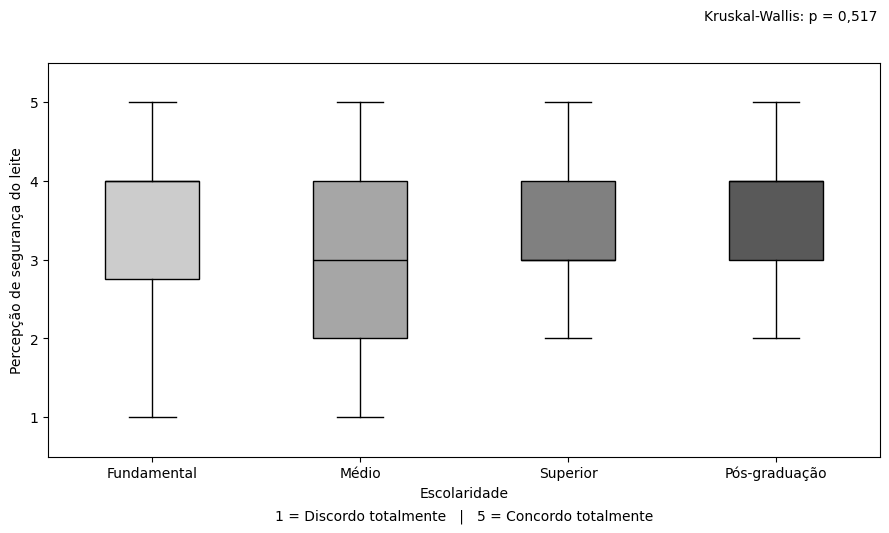

In [201]:
ordem_escolaridade = [
    "Ensino Fundamental completo",
    "Ensino Médio completo",
    "Ensino Superior completo",
    "Pós-graduação completa"
]

rotulos_escolaridade = [
    "Fundamental",
    "Médio",
    "Superior",
    "Pós-graduação"
]

dados_box_esc_seg = [
    df_cons_final.loc[
        df_cons_final[col_escolaridade] == grupo,
        col_seguranca
    ].dropna()
    for grupo in ordem_escolaridade
]

fig, ax = plt.subplots(figsize=(9, 5.5))

bp = ax.boxplot(
    dados_box_esc_seg,
    labels=rotulos_escolaridade,
    patch_artist=True,
    showfliers=False
)

tons = ["0.80", "0.65", "0.50", "0.35"]

for caixa, tom in zip(bp["boxes"], tons):
    caixa.set_facecolor(tom)
    caixa.set_edgecolor("black")

for elemento in ["whiskers", "caps", "medians"]:
    for item in bp[elemento]:
        item.set_color("black")

ax.set_ylabel("Percepção de segurança do leite")
ax.set_xlabel("Escolaridade")
ax.set_ylim(0.5, 5.5)
ax.set_yticks([1, 2, 3, 4, 5])

ax.text(
    0.5,
    -0.16,
    "1 = Discordo totalmente   |   5 = Concordo totalmente",
    transform=ax.transAxes,
    ha="center"
)

fig.text(
    0.98,
    0.97,
    "Kruskal-Wallis: p = 0,517",
    ha="right",
    va="top"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.savefig(
    "grafico_escolaridade_seguranca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição da percepção de segurança do leite segundo a escolaridade dos consumidores (n = 93).

/tmp/ipykernel_3523/2582581573.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


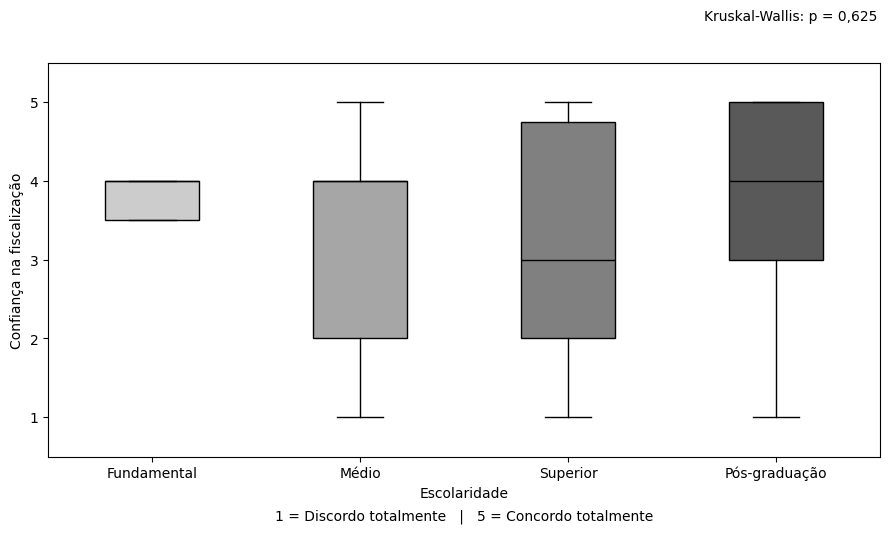

In [202]:
dados_box_esc_conf = [
    df_cons_final.loc[
        df_cons_final[col_escolaridade] == grupo,
        col_confianca
    ].dropna()
    for grupo in ordem_escolaridade
]

fig, ax = plt.subplots(figsize=(9, 5.5))

bp = ax.boxplot(
    dados_box_esc_conf,
    labels=rotulos_escolaridade,
    patch_artist=True,
    showfliers=False
)

tons = ["0.80", "0.65", "0.50", "0.35"]

for caixa, tom in zip(bp["boxes"], tons):
    caixa.set_facecolor(tom)
    caixa.set_edgecolor("black")

for elemento in ["whiskers", "caps", "medians"]:
    for item in bp[elemento]:
        item.set_color("black")

ax.set_ylabel("Confiança na fiscalização")
ax.set_xlabel("Escolaridade")
ax.set_ylim(0.5, 5.5)
ax.set_yticks([1, 2, 3, 4, 5])

ax.text(
    0.5,
    -0.16,
    "1 = Discordo totalmente   |   5 = Concordo totalmente",
    transform=ax.transAxes,
    ha="center"
)

fig.text(
    0.98,
    0.97,
    "Kruskal-Wallis: p = 0,625",
    ha="right",
    va="top"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.savefig(
    "grafico_escolaridade_confianca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Distribuição da confiança nas instituições fiscalizadoras segundo a escolaridade dos consumidores (n = 93).

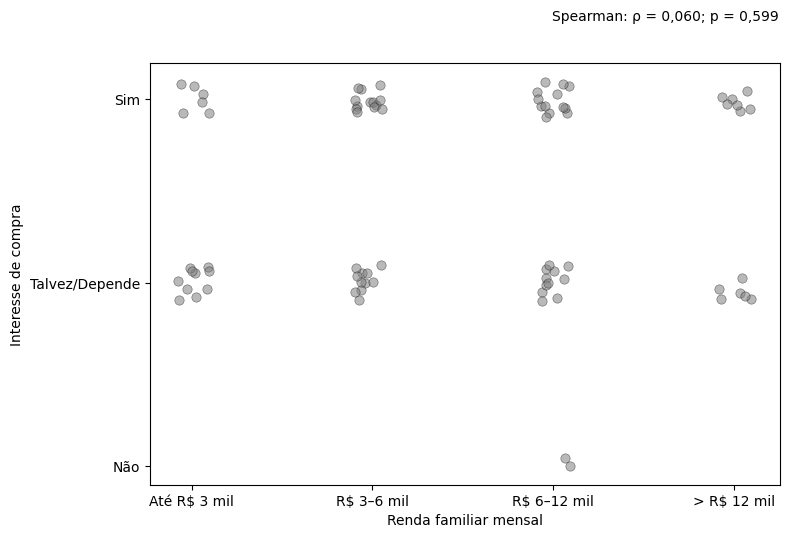

In [203]:
np.random.seed(42)

dados_plot = df_renda_interesse_final[
    ["renda_ord_final", "interesse_ord_final"]
].copy()

x_jitter = (
    dados_plot["renda_ord_final"].values
    + np.random.uniform(-0.10, 0.10, len(dados_plot))
)

y_jitter = (
    dados_plot["interesse_ord_final"].values
    + np.random.uniform(-0.10, 0.10, len(dados_plot))
)

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.scatter(
    x_jitter,
    y_jitter,
    s=45,
    alpha=0.55,
    edgecolor="black",
    linewidth=0.4,
    color="0.50"
)

ax.set_xlabel("Renda familiar mensal")
ax.set_ylabel("Interesse de compra")

ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels([
    "Até R$ 3 mil",
    "R$ 3–6 mil",
    "R$ 6–12 mil",
    "> R$ 12 mil"
])

ax.set_yticks([0, 1, 2])
ax.set_yticklabels([
    "Não",
    "Talvez/Depende",
    "Sim"
])

fig.text(
    0.98,
    0.97,
    "Spearman: ρ = 0,060; p = 0,599",
    ha="right",
    va="top"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.savefig(
    "grafico_renda_interesse_compra.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figura X – Relação entre renda familiar mensal e interesse em comprar leite com selo “Livre de Antibióticos” entre os consumidores (n = 79).

Então agora o passo 4 dos consumidores está fechado:
- gráficos descritivos;
- gráficos das associações significativas;
- gráficos das associações não significativas que constam na tabela inferencial;
- todos salvos em alta resolução no Colab.
Agora seguimos para o passo 5: análise descritiva dos resultados.